# 06. Mechanism ablations, calibration controls and corrected development evaluation

**Goal.** Establish with controls whether the MASSK correction improves probability quality, which of its elements are needed, and whether the improvement holds outside the development panel.

**Research questions.**

- Step 1 (development panel). RQ1: mechanism. RQ2: retrieval versus recalibration. RQ3: sensitivity to the neighbour count $k$, the softmax temperature $T$ and the probability floor $\varepsilon$. RQ4: retrieval quality of the frozen similarity. RQ5: effect of the arXiv pilot cohort dated 2026. RQ6: dependence on near-identical neighbours.
- Step 2. Stress evaluation with one implementation on the temporal and external cohorts, raw-text perturbations and computational cost.
- Step 3. Topic-level relevance of the retrieved neighbours, and a prespecified confirmation of the frozen system on a newly acquired cohort.

**Data.** Development panel, $n = 6{,}708$ publications, two repeats of three outer folds. Temporal cohort ($n = 1{,}914$) and external cohort ($n = 1{,}181$) in step 2. A cohort of OpenAlex publications acquired for step 3 after the evaluated system was frozen.

**Requires.** Saved artifacts of notebooks 01, 02, 04 and 05: acquisition records, cleaned texts, frozen Qwen3 and SPECTER2 embeddings, fold assignments, PRISM-Evidence inner out-of-fold and outer-held posteriors, and the recorded stress model. Step 3 requests records from the OpenAlex service on its first execution and reads the stored responses afterwards.

**Scope.** Every step is fixed in `Docs/research_protocol_rev01.md` before its execution (run `rev01`). Steps 1 and 2 are post hoc or retrospective and therefore exploratory. The confirmation of step 3 is the only prespecified test on publications that no earlier analysis had used.

In [1]:
import hashlib
import html
import json
import math
import random
import re
import time
import unicodedata
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import torch
import torch.nn.functional as F
import yaml
from huggingface_hub import snapshot_download
from IPython.display import Image, Markdown, display
from matplotlib import font_manager
from matplotlib.text import Text
from PIL import Image as PILImage
from scipy import sparse
from scipy.optimize import minimize_scalar
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score, matthews_corrcoef
from sklearn.neighbors import NearestNeighbors
from transformers import AutoModel, AutoTokenizer
from transformers import logging as hf_logging


def find_project_root(start: Path | None = None) -> Path:
    """Return the nearest parent directory that contains PROJECT_REQUIREMENTS.md."""
    start = (start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "PROJECT_REQUIREMENTS.md").is_file():
            return candidate
    raise FileNotFoundError("PROJECT_REQUIREMENTS.md not found above the working directory")


ROOT = find_project_root()
CFG = yaml.safe_load((ROOT / "Configs" / "rev01_experiment.yaml").read_text())
SEED = int(CFG["seed"])
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

RUN_ID = CFG["run_id"]
TABLES = ROOT / CFG["outputs"]["tables"]
FIG_PNG = ROOT / CFG["outputs"]["figures_png"]
FIG_PDF = ROOT / CFG["outputs"]["figures_pdf"]
for directory in (TABLES, FIG_PNG, FIG_PDF):
    directory.mkdir(parents=True, exist_ok=True)

K = int(CFG["classes"])
DEFAULT = CFG["retrieval_default"]
FIT = CFG["fitting"]
STAT = CFG["statistics"]
ECE_BINS = int(STAT["ece_bins"])
N_BOOT = int(STAT["bootstrap_iterations"])
REGISTRY: list[dict] = []

In [2]:
# Tables: default pandas rendering, nothing truncated.
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)

MINUS = "−"
SUPERSCRIPT = str.maketrans("-0123456789", "⁻⁰¹²³⁴⁵⁶⁷⁸⁹")


def fmt_num(x: float, digits: int = 4) -> str:
    """Fixed-point number with a typographic minus; negative zero is suppressed."""
    if not np.isfinite(x):
        raise ValueError(f"non-finite value cannot be displayed: {x}")
    text = f"{x:.{digits}f}"
    if float(text) == 0.0:
        text = f"{0.0:.{digits}f}"
    return text.replace("-", MINUS)


def fmt_signed(x: float, digits: int = 4) -> str:
    """Signed difference: '+0.0120', '−0.0340', '0.0000'."""
    text = fmt_num(x, digits)
    if text.startswith(MINUS) or float(text.replace(MINUS, "-")) == 0.0:
        return text
    return "+" + text


def fmt_p(p: float) -> str:
    """p-value for display: never 'p = 0'."""
    if not 0.0 <= p <= 1.0:
        raise ValueError(f"p-value out of range: {p}")
    if p < 0.001:
        return "< 0.001"
    if p > 0.999:
        return "> 0.999"
    return f"{p:.3f}"


def fmt_sci(x: float, digits: int = 2) -> str:
    """Scientific notation with a multiplication sign and a superscript exponent."""
    if x == 0:
        return "0"
    mantissa, exponent = f"{x:.{digits}e}".split("e")
    return f"{mantissa.replace('-', MINUS)} × 10{str(int(exponent)).translate(SUPERSCRIPT)}"


def fmt_ci(low: float, high: float, digits: int = 4) -> str:
    """Signed 95 % interval in square brackets."""
    return f"[{fmt_signed(low, digits)}, {fmt_signed(high, digits)}]"


def fmt_pm(mean: float, sd: float, digits: int = 4) -> str:
    """Mean ± SD."""
    return f"{fmt_num(mean, digits)} ± {fmt_num(sd, digits)}"


def show_table(df: pd.DataFrame, caption: str) -> None:
    """Show a complete table with default pandas rendering after integrity checks."""
    if df.isna().any().any():
        raise ValueError("table contains missing values")
    if df.astype(str).apply(lambda s: s.str.contains("…|\\.\\.\\.", regex=True)).any().any():
        raise ValueError("table contains an ellipsis")
    display(Markdown(f"**{caption}**"))
    display(df)


def save_table(df: pd.DataFrame, name: str, caption: str, section: str) -> None:
    """Save the numeric table as CSV and LaTeX (booktabs) and register it."""
    df.to_csv(TABLES / f"{name}.csv", index=False)
    df.to_latex(TABLES / f"{name}.tex", index=False, escape=True,
                float_format=lambda v: f"${v:.6g}$")
    REGISTRY.append({"result_id": name, "type": "table", "notebook": "06", "section": section,
                     "run_id": RUN_ID, "artifact": f"{CFG['outputs']['tables']}/{name}.csv",
                     "caption": caption})

In [3]:
# Figures: Matplotlib only, Times New Roman, 18-20 pt, 350 dpi.
font_manager.findfont(font_manager.FontProperties(family="Times New Roman"),
                      fallback_to_default=False)
FONT_MIN_PT, FONT_MAX_PT, DPI = 18, 20, 350
OKABE_ITO = ["#0072B2", "#D55E00", "#009E73", "#CC79A7",
             "#E69F00", "#56B4E9", "#000000", "#F0E442"]
MODEL_COLOUR = {"V1": OKABE_ITO[0], "V0": OKABE_ITO[1], "control": OKABE_ITO[2]}
mpl.rcParams.update({
    "font.family": "Times New Roman",
    "font.size": 18,
    "axes.titlesize": 20,
    "axes.labelsize": 20,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.fontsize": 18,
    "legend.title_fontsize": 18,
    "figure.titlesize": 20,
    "figure.labelsize": 20,
    "mathtext.fontset": "custom",
    "mathtext.rm": "Times New Roman",
    "mathtext.it": "Times New Roman:italic",
    "mathtext.bf": "Times New Roman:bold",
    "axes.unicode_minus": True,
    "axes.prop_cycle": mpl.cycler(color=OKABE_ITO),
    "figure.dpi": DPI,
    "savefig.dpi": DPI,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.05,
    "figure.constrained_layout.use": True,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})


def label_panels(axes) -> None:
    """Put (a), (b), (c), ... below each panel as an extra line of its x-axis label."""
    for i, ax in enumerate(np.ravel(axes)):
        letter = f"({chr(ord('a') + i)})"
        current = ax.get_xlabel()
        ax.set_xlabel(f"{current}\n{letter}" if current else letter)


def _undrawn_tick_labels(fig) -> set[int]:
    """Tick labels outside the view interval exist as objects but are not drawn."""
    undrawn = set()
    for ax in fig.axes:
        for axis in (ax.xaxis, ax.yaxis):
            lo, hi = sorted(axis.get_view_interval())
            tol = 1e-9 * max(1.0, abs(hi - lo))
            for tick in axis.get_major_ticks() + axis.get_minor_ticks():
                loc = tick.get_loc()
                if loc is None or not lo - tol <= loc <= hi + tol:
                    undrawn.update({id(tick.label1), id(tick.label2)})
    return undrawn


def check_figure(fig) -> None:
    """Stop if drawn text is outside 18-20 pt, not Times New Roman, or overlapping."""
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    undrawn = _undrawn_tick_labels(fig)
    texts = [t for t in fig.findobj(Text)
             if t.get_visible() and t.get_text().strip() and id(t) not in undrawn]
    problems = [f"{t.get_text()[:30]!r}: {t.get_fontsize():.1f} pt, {t.get_fontname()}"
                for t in texts
                if not FONT_MIN_PT <= t.get_fontsize() <= FONT_MAX_PT
                or t.get_fontname() != "Times New Roman"]
    boxes = [(t.get_text()[:30], t.get_window_extent(renderer)) for t in texts]
    problems += [f"overlap: {a!r} / {b!r}"
                 for i, (a, box_a) in enumerate(boxes)
                 for b, box_b in boxes[i + 1:] if box_a.overlaps(box_b)]
    if problems:
        raise ValueError("figure violates the standard:\n" + "\n".join(problems))


def show_figure(fig, name: str, caption: str, section: str) -> None:
    """Check, save PNG and PDF at 350 dpi, close, show the saved PNG once, then the caption."""
    check_figure(fig)
    png = FIG_PNG / f"{name}.png"
    fig.savefig(png, dpi=DPI)
    fig.savefig(FIG_PDF / f"{name}.pdf")
    plt.close(fig)
    with PILImage.open(png) as im:
        width_px = im.width
    display(Image(filename=str(png), width=round(width_px / DPI * 96)))
    display(Markdown(f"**{caption}**"))
    REGISTRY.append({"result_id": name, "type": "figure", "notebook": "06", "section": section,
                     "run_id": RUN_ID, "artifact": f"{CFG['outputs']['figures_png']}/{name}.png",
                     "caption": caption})

## 1. Inputs and development panel

**Question.** Which publications form the panel on which every variant is fitted and evaluated?

**Method.** The panel is the pooled training and validation data of the original split. Each publication is held out once in each of the two repeats, so there are six outer contexts. Inside a context, correction parameters are fitted on the inner out-of-fold posteriors of the outer-training rows. The arXiv pilot cohort is reported separately because its publication year (2026) is later than the retrospective temporal cohort (2025); RQ5 examines its influence.

In [4]:
dev = (pd.read_parquet(ROOT / CFG["inputs"]["development"])
       .sort_values("development_row_index").reset_index(drop=True))
y = dev["label_id"].to_numpy(np.int64)
N = len(y)
is_pilot = dev["source"].to_numpy() == "arxiv"
CLASS_NAMES = dev.groupby("label_id")["thematic_class"].first().sort_index().tolist()
assert N == 6708 and set(dev["split"]) <= {"train", "validation"} and len(CLASS_NAMES) == K


def load_unit_vectors(path: Path) -> np.ndarray:
    """Load an embedding matrix and L2-normalise its rows."""
    a = np.load(path).astype(np.float32)
    return a / np.maximum(np.linalg.norm(a, axis=1, keepdims=True), 1e-8)


EQ = torch.from_numpy(load_unit_vectors(ROOT / CFG["inputs"]["qwen3"]))
ES = torch.from_numpy(load_unit_vectors(ROOT / CFG["inputs"]["specter2"]))
YT = torch.from_numpy(y)
assert len(EQ) == N and len(ES) == N

PC = [f"probability_{i}" for i in range(K)]
SC = [f"semantic_probability_{i}" for i in range(K)]
KEYS = ["repeat", "outer_fold", "development_row_index"]
folds = pd.read_parquet(ROOT / CFG["inputs"]["outer_folds"])
inner_roles = pd.read_parquet(ROOT / CFG["inputs"]["inner_folds"])[KEYS + ["inner_fold"]].drop_duplicates()
inner_base = pd.read_parquet(ROOT / CFG["inputs"]["prism_inner_oof"]).merge(
    inner_roles, on=KEYS, validate="one_to_one")
outer_base = pd.read_parquet(ROOT / CFG["inputs"]["prism_outer"])
CONTEXTS = [(int(r), int(f)) for r in sorted(folds["repeat"].unique())
            for f in sorted(folds["outer_fold"].unique())]

ctx = {}
for r, f in CONTEXTS:
    held = folds[(folds["repeat"] == r) & (folds["outer_fold"] == f)]
    hi = np.sort(held["development_row_index"].to_numpy(np.int64))
    ti = np.setdiff1d(np.arange(N), hi, assume_unique=True)
    ib = inner_base[(inner_base["repeat"] == r) & (inner_base["outer_fold"] == f)].sort_values(
        "development_row_index")
    ob = (outer_base[(outer_base["repeat"] == r) & (outer_base["outer_fold"] == f)]
          .groupby("development_row_index", as_index=False)[PC].mean()
          .sort_values("development_row_index"))
    assert np.array_equal(ib["development_row_index"].to_numpy(), ti)
    assert np.array_equal(ob["development_row_index"].to_numpy(), hi)
    assert np.array_equal(ib["true_label"].to_numpy(), y[ti])
    ctx[(r, f)] = {"hi": hi, "ti": ti, "inner_fold": ib["inner_fold"].to_numpy(),
                   "base_inner": ib[SC].to_numpy(np.float32),
                   "base_outer": ob[PC].to_numpy(np.float32)}
assert len(CONTEXTS) == 6

In [5]:
group_sizes = folds[folds["repeat"] == 0]["author_institution_component"].value_counts()
CAPTION_6_1 = ("Table 6.1. Composition of the development panel used in run rev01 "
               "(6,708 publications). Class sizes are the smallest and largest of the eight "
               "thematic classes within each cohort. The outer folds are stratified by class and "
               f"grouped by an author–institution proxy with {len(group_sizes):,} groups, of which "
               f"{fmt_num(100.0 * (group_sizes == 1).mean(), 1)} % contain one publication.")
rows = []
for (source, split), g in dev.groupby(["source", "split"], sort=False):
    per_class = g["label_id"].value_counts()
    rows.append({"cohort": {"openalex": "OpenAlex", "arxiv": "arXiv pilot"}[source],
                 "original_role": split, "publications": len(g),
                 "share_percent": 100.0 * len(g) / N,
                 "year_min": int(g["publication_year"].min()),
                 "year_max": int(g["publication_year"].max()),
                 "smallest_class": int(per_class.min()), "largest_class": int(per_class.max())})
all_class = dev["label_id"].value_counts()
rows.append({"cohort": "All", "original_role": "development", "publications": N,
             "share_percent": 100.0, "year_min": int(dev["publication_year"].min()),
             "year_max": int(dev["publication_year"].max()),
             "smallest_class": int(all_class.min()), "largest_class": int(all_class.max())})
composition = pd.DataFrame(rows)
save_table(composition, "table6_1_panel_composition", CAPTION_6_1, "1")

view = pd.DataFrame({
    "Cohort": composition["cohort"],
    "Original role": composition["original_role"],
    "Publications": composition["publications"].map(lambda v: f"{v:d}"),
    "Share (%)": composition["share_percent"].map(lambda v: fmt_num(v, 2)),
    "Publication years": [f"{a}" if a == b else f"{a}–{b}"
                          for a, b in zip(composition["year_min"], composition["year_max"])],
    "Smallest class (n)": composition["smallest_class"].map(lambda v: f"{v:d}"),
    "Largest class (n)": composition["largest_class"].map(lambda v: f"{v:d}"),
}).set_index("Cohort")
show_table(view, CAPTION_6_1)

**Table 6.1. Composition of the development panel used in run rev01 (6,708 publications). Class sizes are the smallest and largest of the eight thematic classes within each cohort. The outer folds are stratified by class and grouped by an author–institution proxy with 6,539 groups, of which 98.4 % contain one publication.**

,Original role,Publications,Share (%),Publication years,Smallest class (n),Largest class (n)
Cohort,,,,,,
OpenAlex,train,3825,57.02,2018–2022,307,609
OpenAlex,validation,1707,25.45,2023–2024,183,276
arXiv pilot,validation,1176,17.53,2026,142,150
All,development,6708,100.00,2018–2026,641,1034


**Interpretation.** The arXiv pilot cohort contributes 1,176 of the 6,708 publications (17.53 %), all dated 2026, with 142–150 publications per class. It is later than the retrospective 2025 cohort, so the development panel cannot support a forward-in-time reading of that cohort. The OpenAlex training years are unbalanced across classes (307–609 publications per class). The author–institution grouping leaves 98.4 % of the groups with a single publication, so the outer folds are effectively class-stratified random folds.

## 2. Neighbour evidence and correction variants

**Question.** How are the neighbour evidence and the nine compared variants defined?

**Method.** For a query publication $i$ and an index publication $j$, the dual-view similarity is the mean cosine of the frozen Qwen3 ($Q$) and SPECTER2 ($S$) vectors. The $k$ nearest index publications $N_k(i)$ give a softmax-weighted class distribution:

$$
s_{ij} = \tfrac{1}{2}\left[\cos\!\left(e_i^{Q}, e_j^{Q}\right) + \cos\!\left(e_i^{S}, e_j^{S}\right)\right],
\qquad
p_i^{k}(c) = \sum_{j \in N_k(i)} \frac{\exp(s_{ij}/T)}{\sum_{r \in N_k(i)} \exp(s_{ir}/T)}\;\mathbb{1}[y_j = c].
$$

With the PRISM-Evidence posterior $p_i^{b}$ and the confidence multiplier $u_i = 1 - \max_j p_i^{b}(j)$, the MASSK correction is

$$
z_{ic} = \log p_i^{b}(c) + u_i\,\gamma_c\left[\log p_i^{k}(c) - \log p_i^{b}(c)\right],
\qquad \gamma_c = \sigma(g_c),
\qquad p_i^{M} = \operatorname{softmax}(z_i).
$$

Probabilities are clipped to $[\varepsilon, 1]$ before logarithms. The variants are:

| ID | Variant | Corrected logits | Parameters |
|---|---|---|---|
| V0 | PRISM-Evidence | $\log p^{b}$ | 0 |
| V1 | MASSK (Full) | $\log p^{b} + u\,\gamma_c\,(\log p^{k} - \log p^{b})$ | 8 |
| V2 | Shared γ | as V1 with one $\gamma$ | 1 |
| V3 | No multiplier | as V1 with $u = 1$ | 8 |
| V4 | Shared γ, no multiplier | as V2 with $u = 1$ | 1 |
| V5 | kNN only | $\log p^{k}$ | 0 |
| C1 | Temperature scaling | $\log p^{b} / \tau$ | 1 |
| C2 | Class bias | $\log p^{b} + b_c$ | 8 |
| C3 | Vector scaling | $a_c \log p^{b} + b_c$ | 16 |

Every learned variant is fitted in the same way: class-weighted cross-entropy with weights $n/(8\,n_c)$ on the inner out-of-fold rows of an outer-training context, full-batch Adam with learning rate 0.05 for 300 iterations, keeping the state with the lowest observed objective. The penalty $0.01\cdot\operatorname{mean}(\gamma^2)$ applies to the $\gamma$ variants. The retrieval index for fitting contains the other inner folds; for outer-held predictions it contains the outer-training rows. Default settings are $k = 5$, $T = 0.07$, $\varepsilon = 10^{-7}$.

In [6]:
KMAX = max(CFG["sensitivity"]["top_k"])


def top_neighbours(query: np.ndarray, docs: np.ndarray, view: str = "dual", kmax: int = KMAX):
    """Similarities and labels of the kmax nearest index rows for each query row."""
    q, d = torch.from_numpy(query), torch.from_numpy(docs)
    if view == "dual":
        sim = 0.5 * (EQ[q] @ EQ[d].T + ES[q] @ ES[d].T)
    elif view == "qwen3":
        sim = EQ[q] @ EQ[d].T
    elif view == "specter2":
        sim = ES[q] @ ES[d].T
    else:
        raise ValueError(view)
    val, pos = torch.topk(sim, k=kmax, dim=1)
    return val.numpy(), YT[d[pos]].numpy()


def neighbour_sets(index_mask: np.ndarray) -> dict:
    """Cross-fitted inner neighbours and outer neighbours per context; the index is limited to index_mask."""
    out = {}
    for key, c in ctx.items():
        ti, hi, inner = c["ti"], c["hi"], c["inner_fold"]
        val = np.empty((len(ti), KMAX), np.float32)
        lab = np.empty((len(ti), KMAX), np.int64)
        for fold in np.unique(inner):
            m = inner == fold
            val[m], lab[m] = top_neighbours(ti[m], ti[~m & index_mask[ti]])
        outer_val, outer_lab = top_neighbours(hi, ti[index_mask[ti]])
        out[key] = {"inner_val": val, "inner_lab": lab, "outer_val": outer_val, "outer_lab": outer_lab}
    return out


def knn_posterior(val: np.ndarray, lab: np.ndarray, k: int, temperature: float) -> np.ndarray:
    """Softmax-weighted class distribution of the k nearest neighbours."""
    v = val[:, :k].astype(np.float64) / temperature
    w = np.exp(v - v.max(axis=1, keepdims=True))
    w /= w.sum(axis=1, keepdims=True)
    p = np.zeros((len(val), K))
    np.add.at(p, (np.arange(len(val))[:, None], lab[:, :k]), w)
    return p


NB_ALL = neighbour_sets(np.ones(N, bool))
NB_NO_PILOT = neighbour_sets(~is_pilot)

In [7]:
VARIANTS = {
    "V0": {"name": "PRISM-Evidence", "kind": "none", "parameters": 0},
    "V1": {"name": "MASSK (Full)", "kind": "full", "parameters": 8},
    "V2": {"name": "Shared γ", "kind": "shared", "parameters": 1},
    "V3": {"name": "No multiplier", "kind": "no_mult", "parameters": 8},
    "V4": {"name": "Shared γ, no multiplier", "kind": "shared_no_mult", "parameters": 1},
    "V5": {"name": "kNN only", "kind": "knn_only", "parameters": 0},
    "C1": {"name": "Temperature scaling", "kind": "temp", "parameters": 1},
    "C2": {"name": "Class bias", "kind": "bias", "parameters": 8},
    "C3": {"name": "Vector scaling", "kind": "vector", "parameters": 16},
}
GAMMA_KINDS = ("full", "shared", "no_mult", "shared_no_mult")


def variant_logits(kind: str, params: dict, lb: torch.Tensor, lk: torch.Tensor, u: torch.Tensor):
    """Corrected logits and the penalty term of one variant."""
    zero = lb.new_zeros(())
    if kind == "knn_only":
        return lk, zero
    if kind in GAMMA_KINDS:
        gamma = torch.sigmoid(params["raw"])
        scale = u if kind in ("full", "shared") else 1.0
        return lb + scale * gamma[None, :] * (lk - lb), FIT["gamma_penalty"] * gamma.square().mean()
    if kind == "temp":
        return lb / torch.exp(params["log_tau"]), zero
    if kind == "bias":
        return lb + params["b"][None, :], zero
    if kind == "vector":
        return params["a"][None, :] * lb + params["b"][None, :], zero
    raise ValueError(kind)


def log_inputs(base: np.ndarray, near: np.ndarray, eps: float):
    """Clipped log-probabilities and the confidence multiplier as float32 tensors."""
    lb = torch.log(torch.from_numpy(np.clip(base, eps, 1.0).astype(np.float32)))
    lk = torch.log(torch.from_numpy(np.clip(near, eps, 1.0).astype(np.float32)))
    u = (1.0 - torch.from_numpy(base.astype(np.float32)).max(dim=1).values)[:, None]
    return lb, lk, u


def fit_variant(kind: str, base: np.ndarray, near: np.ndarray, target: np.ndarray, eps: float) -> dict:
    """Fit one variant on inner out-of-fold rows; return the parameters with the lowest objective."""
    if kind in ("none", "knn_only"):
        return {}
    lb, lk, u = log_inputs(base, near, eps)
    yt = torch.from_numpy(target)
    class_weight = len(yt) / (K * torch.bincount(yt, minlength=K).float())
    g0 = float(np.log(FIT["gamma_init"] / (1.0 - FIT["gamma_init"])))
    start = {"full": {"raw": torch.full((K,), g0)},
             "shared": {"raw": torch.full((1,), g0)},
             "no_mult": {"raw": torch.full((K,), g0)},
             "shared_no_mult": {"raw": torch.full((1,), g0)},
             "temp": {"log_tau": torch.zeros(1)},
             "bias": {"b": torch.zeros(K)},
             "vector": {"a": torch.ones(K), "b": torch.zeros(K)}}[kind]
    params = {name: torch.nn.Parameter(value.clone()) for name, value in start.items()}
    optimiser = torch.optim.Adam(list(params.values()), lr=FIT["learning_rate"])
    best_loss, best = float("inf"), None
    for _ in range(int(FIT["iterations"])):
        optimiser.zero_grad()
        logits, penalty = variant_logits(kind, params, lb, lk, u)
        loss = F.cross_entropy(logits, yt, weight=class_weight) + penalty
        loss.backward()
        state = {name: value.detach().clone() for name, value in params.items()}
        optimiser.step()
        if float(loss.detach()) < best_loss:
            best_loss, best = float(loss.detach()), state
    return {name: value.numpy() for name, value in best.items()}


def apply_variant(kind: str, params: dict, base: np.ndarray, near: np.ndarray, eps: float) -> np.ndarray:
    """Posterior of one variant for held-out rows."""
    if kind == "none":
        return base.astype(np.float64)
    lb, lk, u = log_inputs(base, near, eps)
    with torch.no_grad():
        logits, _ = variant_logits(kind, {n: torch.from_numpy(v) for n, v in params.items()}, lb, lk, u)
    return torch.softmax(logits.double(), dim=1).numpy()


def run_variant(kind: str, k: int, temperature: float, eps: float, neighbours: dict = NB_ALL):
    """Fit in every context and predict its outer-held rows; returns (2, N, K) posteriors and parameters."""
    post, fitted = np.zeros((2, N, K)), {}
    for (r, f), c in ctx.items():
        nb = neighbours[(r, f)]
        near_inner = knn_posterior(nb["inner_val"], nb["inner_lab"], k, temperature)
        near_outer = knn_posterior(nb["outer_val"], nb["outer_lab"], k, temperature)
        fitted[(r, f)] = fit_variant(kind, c["base_inner"], near_inner, y[c["ti"]], eps)
        post[r, c["hi"]] = apply_variant(kind, fitted[(r, f)], c["base_outer"], near_outer, eps)
    assert np.allclose(post.sum(axis=2), 1.0, atol=1e-4)
    return post, fitted


# Structural check: a coefficient of zero returns the clipped base posterior.
_c = ctx[CONTEXTS[0]]
_near = knn_posterior(NB_ALL[CONTEXTS[0]]["outer_val"], NB_ALL[CONTEXTS[0]]["outer_lab"],
                      DEFAULT["top_k"], DEFAULT["temperature"])
_zero = apply_variant("full", {"raw": np.full(K, -60.0, np.float32)}, _c["base_outer"], _near,
                      DEFAULT["probability_floor"])
_clipped = np.clip(_c["base_outer"], DEFAULT["probability_floor"], 1.0).astype(np.float64)
assert np.allclose(_zero, _clipped / _clipped.sum(axis=1, keepdims=True), atol=1e-6)

POST, PARAMS = {}, {}
for vid, spec in VARIANTS.items():
    POST[vid], PARAMS[vid] = run_variant(spec["kind"], DEFAULT["top_k"], DEFAULT["temperature"],
                                         DEFAULT["probability_floor"])
PAPER = {vid: post.mean(axis=0) for vid, post in POST.items()}

## 3. Reproduction of the recorded MASSK predictions

**Question.** Does the present implementation reproduce the coefficients and posteriors recorded for the proposed model in notebook 04?

**Method.** The check has two parts. (i) The recorded class-wise coefficients are applied with the neighbour evidence and the correction formula of this notebook; this isolates the implementation from the optimiser. (ii) The coefficients are refitted here on CPU with the recorded procedure, and the resulting posteriors are compared with the recorded ones, which were fitted on a GPU. The protocol sets a tolerance of $10^{-3}$ for the maximum absolute probability difference. All later analyses use the coefficients fitted in this notebook, so that every variant is fitted on the same device with the same procedure.

In [8]:
METRIC_NAMES = ["NLL", "Brier", "ECE", "Macro-F1", "Accuracy", "MCC"]
LOWER_IS_BETTER = {"NLL", "Brier", "ECE"}
ECE_EDGES = np.linspace(0.0, 1.0, ECE_BINS + 1)


def normalise(p: np.ndarray) -> np.ndarray:
    """Clip at 1e-9 and renormalise, as in the recorded evaluation."""
    p = np.clip(p, 1e-9, 1.0)
    return p / p.sum(axis=1, keepdims=True)


def metrics(p: np.ndarray, target: np.ndarray) -> dict:
    """Classification and probability metrics of one posterior matrix."""
    p = normalise(p)
    pred, conf = p.argmax(axis=1), p.max(axis=1)
    correct = (pred == target).astype(float)
    ece = 0.0
    for lo, hi in zip(ECE_EDGES[:-1], ECE_EDGES[1:]):
        m = (conf > lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(correct[m].mean() - conf[m].mean())
    return {"NLL": float(-np.log(p[np.arange(len(target)), target]).mean()),
            "Brier": float(((p - np.eye(K)[target]) ** 2).sum(axis=1).mean()),
            "ECE": float(ece),
            "Macro-F1": float(f1_score(target, pred, average="macro")),
            "Accuracy": float(correct.mean()),
            "MCC": float(matthews_corrcoef(target, pred))}


E1 = pd.DataFrame({vid: metrics(PAPER[vid], y) for vid in VARIANTS}).T

reference = pd.read_parquet(ROOT / CFG["inputs"]["massk_outer_reference"])
ref_post = np.zeros((2, N, K))
ref_post[reference["repeat"].to_numpy(), reference["development_row_index"].to_numpy()] = (
    reference[PC].to_numpy())
gamma_ref = (pd.read_csv(ROOT / CFG["inputs"]["massk_gamma_reference"])
             .sort_values(["repeat", "outer_fold", "class_id"])["gamma"].to_numpy()
             .reshape(len(CONTEXTS), K))
gamma_new = np.stack([1.0 / (1.0 + np.exp(-PARAMS["V1"][key]["raw"].astype(np.float64)))
                      for key in CONTEXTS])
recorded = pd.read_csv(ROOT / CFG["inputs"]["massk_metrics_reference"]).set_index("track")
TOLERANCE = float(CFG["replay_tolerance"])

# Part (i): recorded coefficients with the neighbour evidence and formula of this notebook.
post_recorded_gamma = np.zeros((2, N, K))
for i, key in enumerate(CONTEXTS):
    c, nb = ctx[key], NB_ALL[key]
    near = knn_posterior(nb["outer_val"], nb["outer_lab"], DEFAULT["top_k"], DEFAULT["temperature"])
    raw = np.log(gamma_ref[i] / (1.0 - gamma_ref[i])).astype(np.float32)
    post_recorded_gamma[key[0], c["hi"]] = apply_variant("full", {"raw": raw}, c["base_outer"], near,
                                                         DEFAULT["probability_floor"])
formula_diff = float(np.abs(post_recorded_gamma - ref_post).max())
assert formula_diff < 1e-5

# Part (ii): coefficients refitted on CPU.
row_diff = np.abs(POST["V1"] - ref_post).max(axis=2)
rows_above = int((row_diff > TOLERANCE).sum())

checks = pd.DataFrame([
    {"quantity": "(i) Posteriors with the recorded coefficients (13,416 rows × 8 classes)",
     "recorded": np.nan, "recomputed": np.nan, "max_abs_difference": formula_diff},
    {"quantity": "(ii) Class-wise coefficients γ refitted on CPU (6 contexts × 8 classes)",
     "recorded": np.nan, "recomputed": np.nan,
     "max_abs_difference": float(np.abs(gamma_new - gamma_ref).max())},
    {"quantity": "(ii) Posteriors with the refitted coefficients (13,416 rows × 8 classes)",
     "recorded": np.nan, "recomputed": np.nan, "max_abs_difference": float(row_diff.max())},
    {"quantity": "PRISM-Evidence paper-level NLL",
     "recorded": recorded.loc["PRISM_EVIDENCE_ANCHOR", "nll"], "recomputed": E1.loc["V0", "NLL"],
     "max_abs_difference": abs(recorded.loc["PRISM_EVIDENCE_ANCHOR", "nll"] - E1.loc["V0", "NLL"])},
    {"quantity": "MASSK paper-level NLL",
     "recorded": recorded.loc["MASSK_CLASSWISE_RETRIEVAL_RESIDUAL", "nll"],
     "recomputed": E1.loc["V1", "NLL"],
     "max_abs_difference": abs(recorded.loc["MASSK_CLASSWISE_RETRIEVAL_RESIDUAL", "nll"]
                               - E1.loc["V1", "NLL"])},
    {"quantity": "MASSK paper-level macro-F1",
     "recorded": recorded.loc["MASSK_CLASSWISE_RETRIEVAL_RESIDUAL", "macro_f1"],
     "recomputed": E1.loc["V1", "Macro-F1"],
     "max_abs_difference": abs(recorded.loc["MASSK_CLASSWISE_RETRIEVAL_RESIDUAL", "macro_f1"]
                               - E1.loc["V1", "Macro-F1"])},
])
CAPTION_6_2 = ("Table 6.2. Agreement between the recorded MASSK results of notebook 04 and their "
               "recomputation in this notebook. For the three arrays only the maximum absolute "
               "difference applies (n/a: not a single value). The predeclared tolerance for "
               f"posteriors is 1 × 10⁻³. With the refitted coefficients, {rows_above} of "
               f"{row_diff.size:,} outer-held rows exceed it (99.9th percentile of the row-wise "
               f"maximum: {fmt_sci(float(np.quantile(row_diff, 0.999)))}).")
save_table(checks.fillna(-1.0), "table6_2_reproduction", CAPTION_6_2 + " In the CSV, −1 marks n/a.", "3")
view = pd.DataFrame({
    "Quantity": checks["quantity"],
    "Recorded": [fmt_num(v, 6) if np.isfinite(v) else "n/a" for v in checks["recorded"]],
    "Recomputed": [fmt_num(v, 6) if np.isfinite(v) else "n/a" for v in checks["recomputed"]],
    "Maximum absolute difference": checks["max_abs_difference"].map(fmt_sci),
}).set_index("Quantity")
show_table(view, CAPTION_6_2)

**Table 6.2. Agreement between the recorded MASSK results of notebook 04 and their recomputation in this notebook. For the three arrays only the maximum absolute difference applies (n/a: not a single value). The predeclared tolerance for posteriors is 1 × 10⁻³. With the refitted coefficients, 7 of 13,416 outer-held rows exceed it (99.9th percentile of the row-wise maximum: 7.10 × 10⁻⁴).**

,Recorded,Recomputed,Maximum absolute difference
Quantity,,,
"(i) Posteriors with the recorded coefficients (13,416 rows × 8 classes)",n/a,n/a,1.79 × 10⁻⁷
(ii) Class-wise coefficients γ refitted on CPU (6 contexts × 8 classes),n/a,n/a,5.80 × 10⁻⁴
"(ii) Posteriors with the refitted coefficients (13,416 rows × 8 classes)",n/a,n/a,1.15 × 10⁻³
PRISM-Evidence paper-level NLL,0.555242,0.555242,0
MASSK paper-level NLL,0.544806,0.544804,2.09 × 10⁻⁶
MASSK paper-level macro-F1,0.805731,0.805731,0


**Interpretation.** With the recorded coefficients the posteriors agree to $1.79 \times 10^{-7}$, so the neighbour evidence and the correction formula are implemented as recorded. Refitting on CPU moves the coefficients by up to $5.80 \times 10^{-4}$, and 7 of 13,416 outer-held rows then differ by more than $10^{-3}$ (maximum $1.15 \times 10^{-3}$). The predeclared tolerance is therefore not met for the refit. This is logged as a deviation in the protocol, and the tolerance is left unchanged. Paper-level results are unaffected at the reported precision: NLL 0.544804 against the recorded 0.544806, and an identical macro-F1 of 0.805731.

## 4. RQ1 and RQ2: mechanism ablations and calibration controls

**Questions.** RQ1: do the class-specific coefficients and the confidence multiplier contribute to probability quality? RQ2: does retrieval evidence improve probability quality beyond recalibration alone?

**Method.** Two estimands are reported. E1 averages the two repeat posteriors of each publication and computes metrics on the 6,708 publications. E2 computes metrics in each of the six outer contexts. The primary endpoint is E1 NLL. Differences follow one sign convention: $\Delta > 0$ favours MASSK (Full); for losses $\Delta = M_{\text{variant}} - M_{\text{Full}}$ and for scores $\Delta = M_{\text{Full}} - M_{\text{variant}}$. Intervals come from a paired paper-level bootstrap with 20,000 resamples, in which the same resampled panels are applied to every variant. The primary family contains seven comparisons of Full with V0, V2, V3, V4, C1, C2 and C3 on E1 NLL, with two-sided bootstrap p-values and the Holm correction at $\alpha = 0.05$. A comparison meets the predeclared rule if the adjusted test favours Full and the lower 95 % bound of $\Delta$Macro-F1 is at least −0.003.

In [9]:
def variant_label(vid: str) -> str:
    """Identifier and name of a variant for table rows."""
    return f"{vid} {VARIANTS[vid]['name']}"


CAPTION_6_3 = ("Table 6.3. Development performance of all variants under estimand E1 "
               "(repeat-averaged posteriors, 6,708 publications). NLL, Brier score and ECE "
               "(15 equal-width bins): lower is better. Macro-F1, accuracy and MCC: higher is better.")
e1_numeric = E1.reset_index(names="variant_id")
e1_numeric.insert(1, "variant", [VARIANTS[v]["name"] for v in e1_numeric["variant_id"]])
e1_numeric.insert(2, "parameters", [VARIANTS[v]["parameters"] for v in e1_numeric["variant_id"]])
save_table(e1_numeric, "table6_3_e1_metrics", CAPTION_6_3, "4")

view = pd.DataFrame({"Variant": [variant_label(v) for v in E1.index],
                     "Parameters": [f"{VARIANTS[v]['parameters']:d}" for v in E1.index]})
for name in METRIC_NAMES:
    view[name] = E1[name].map(fmt_num).to_numpy()
show_table(view.set_index("Variant"), CAPTION_6_3)

**Table 6.3. Development performance of all variants under estimand E1 (repeat-averaged posteriors, 6,708 publications). NLL, Brier score and ECE (15 equal-width bins): lower is better. Macro-F1, accuracy and MCC: higher is better.**

,Parameters,NLL,Brier,ECE,Macro-F1,Accuracy,MCC
Variant,,,,,,,
V0 PRISM-Evidence,0,0.5552,0.2820,0.0163,0.8053,0.8093,0.7819
V1 MASSK (Full),8,0.5448,0.2789,0.0141,0.8057,0.8099,0.7825
V2 Shared γ,1,0.5442,0.2783,0.0134,0.8057,0.8099,0.7825
V3 No multiplier,8,0.5438,0.2789,0.0218,0.8062,0.8104,0.7831
"V4 Shared γ, no multiplier",1,0.5436,0.2784,0.0206,0.8056,0.8099,0.7825
V5 kNN only,0,1.1462,0.3064,0.0347,0.7853,0.7898,0.7594
C1 Temperature scaling,1,0.5525,0.2820,0.0156,0.8052,0.8093,0.7819
C2 Class bias,8,0.5577,0.2834,0.0137,0.8047,0.8083,0.7808
C3 Vector scaling,16,0.5532,0.2830,0.0173,0.8048,0.8089,0.7815


In [10]:
CTX_METRICS = {vid: pd.DataFrame([metrics(POST[vid][r, ctx[(r, f)]["hi"]], y[ctx[(r, f)]["hi"]])
                                  for r, f in CONTEXTS]) for vid in VARIANTS}
rows = []
for vid in VARIANTS:
    per = CTX_METRICS[vid]
    rows.append({"variant_id": vid, "variant": VARIANTS[vid]["name"],
                 "nll_mean": per["NLL"].mean(), "nll_sd": per["NLL"].std(ddof=1),
                 "macro_f1_mean": per["Macro-F1"].mean(), "macro_f1_sd": per["Macro-F1"].std(ddof=1),
                 "contexts_full_lower_nll": int((CTX_METRICS["V1"]["NLL"] < per["NLL"]).sum()),
                 "contexts_full_higher_macro_f1": int(
                     (CTX_METRICS["V1"]["Macro-F1"] > per["Macro-F1"]).sum())})
E2 = pd.DataFrame(rows).set_index("variant_id")
CAPTION_6_4 = ("Table 6.4. Development performance under estimand E2: mean ± SD over the six outer "
               "contexts (2,236 held-out publications each). The last two columns count the contexts "
               "in which MASSK (Full) is better than the row variant (n/a for the Full row itself).")
save_table(E2.reset_index(), "table6_4_e2_metrics", CAPTION_6_4, "4")

view = pd.DataFrame({
    "Variant": [variant_label(v) for v in E2.index],
    "NLL (mean ± SD)": [fmt_pm(a, b) for a, b in zip(E2["nll_mean"], E2["nll_sd"])],
    "Macro-F1 (mean ± SD)": [fmt_pm(a, b) for a, b in zip(E2["macro_f1_mean"], E2["macro_f1_sd"])],
    "Full has lower NLL": ["n/a" if v == "V1" else f"{c:d}/6"
                           for v, c in zip(E2.index, E2["contexts_full_lower_nll"])],
    "Full has higher Macro-F1": ["n/a" if v == "V1" else f"{c:d}/6"
                                 for v, c in zip(E2.index, E2["contexts_full_higher_macro_f1"])],
}).set_index("Variant")
show_table(view, CAPTION_6_4)

**Table 6.4. Development performance under estimand E2: mean ± SD over the six outer contexts (2,236 held-out publications each). The last two columns count the contexts in which MASSK (Full) is better than the row variant (n/a for the Full row itself).**

,NLL (mean ± SD),Macro-F1 (mean ± SD),Full has lower NLL,Full has higher Macro-F1
Variant,,,,
V0 PRISM-Evidence,0.5675 ± 0.0273,0.7976 ± 0.0100,6/6,5/6
V1 MASSK (Full),0.5592 ± 0.0290,0.7999 ± 0.0102,n/a,n/a
V2 Shared γ,0.5579 ± 0.0284,0.8003 ± 0.0108,1/6,3/6
V3 No multiplier,0.5586 ± 0.0298,0.8000 ± 0.0103,2/6,3/6
"V4 Shared γ, no multiplier",0.5577 ± 0.0291,0.7998 ± 0.0104,1/6,3/6
V5 kNN only,1.3900 ± 0.1035,0.7806 ± 0.0067,6/6,6/6
C1 Temperature scaling,0.5658 ± 0.0288,0.7976 ± 0.0100,6/6,5/6
C2 Class bias,0.5702 ± 0.0273,0.7973 ± 0.0113,6/6,5/6
C3 Vector scaling,0.5668 ± 0.0288,0.7973 ± 0.0111,6/6,4/6


In [11]:
def paper_terms(p: np.ndarray, target: np.ndarray) -> dict:
    """Per-publication terms from which every metric of a resampled panel is a weighted sum."""
    p = normalise(p)
    n = len(target)
    pred, conf = p.argmax(axis=1), p.max(axis=1)
    correct = (pred == target).astype(np.float64)
    bin_id = np.clip(np.searchsorted(ECE_EDGES, conf, side="left") - 1, 0, ECE_BINS - 1)
    gap = np.zeros((n, ECE_BINS))
    gap[np.arange(n), bin_id] = correct - conf
    cm = np.zeros((n, K * K))
    cm[np.arange(n), target * K + pred] = 1.0
    return {"nll": -np.log(p[np.arange(n), target]),
            "brier": ((p - np.eye(K)[target]) ** 2).sum(axis=1),
            "correct": correct, "gap": gap, "cm": cm}


def metrics_from_weights(w: np.ndarray, terms: dict) -> dict:
    """Metrics of resampled panels; each row of w holds the multinomial counts of one replicate."""
    n = w.sum(axis=1)
    cm = (w @ terms["cm"]).reshape(-1, K, K)
    tp = np.einsum("bkk->bk", cm)
    true_n, pred_n = cm.sum(axis=2), cm.sum(axis=1)
    f1 = np.divide(2.0 * tp, true_n + pred_n, out=np.zeros_like(tp), where=(true_n + pred_n) > 0)
    mcc = (tp.sum(axis=1) * n - (pred_n * true_n).sum(axis=1)) / np.sqrt(
        (n ** 2 - (pred_n ** 2).sum(axis=1)) * (n ** 2 - (true_n ** 2).sum(axis=1)))
    return {"NLL": w @ terms["nll"] / n, "Brier": w @ terms["brier"] / n,
            "ECE": np.abs(w @ terms["gap"]).sum(axis=1) / n, "Macro-F1": f1.mean(axis=1),
            "Accuracy": w @ terms["correct"] / n, "MCC": mcc}


def bootstrap_metrics(posteriors: dict, target: np.ndarray, n_boot: int, seed: int, chunk: int = 500):
    """Paired paper-level bootstrap: identical resampled panels for every variant."""
    rng = np.random.default_rng(seed)
    n = len(target)
    terms = {vid: paper_terms(p, target) for vid, p in posteriors.items()}
    out = {vid: {m: [] for m in METRIC_NAMES} for vid in terms}
    for start in range(0, n_boot, chunk):
        w = rng.multinomial(n, np.full(n, 1.0 / n), size=min(chunk, n_boot - start)).astype(np.float64)
        for vid, t in terms.items():
            for m, values in metrics_from_weights(w, t).items():
                out[vid][m].append(values)
    return {vid: {m: np.concatenate(v) for m, v in d.items()} for vid, d in out.items()}


def bootstrap_mean(values: np.ndarray, n_boot: int, seed: int, chunk: int = 500) -> np.ndarray:
    """Bootstrap distribution of the mean of per-publication values."""
    rng = np.random.default_rng(seed)
    n = len(values)
    out = []
    for start in range(0, n_boot, chunk):
        w = rng.multinomial(n, np.full(n, 1.0 / n), size=min(chunk, n_boot - start))
        out.append(w @ values / n)
    return np.concatenate(out)


def holm(pvalues: np.ndarray) -> np.ndarray:
    """Holm step-down adjusted p-values."""
    p = np.asarray(pvalues, float)
    adjusted, running = np.empty(len(p)), 0.0
    for rank, i in enumerate(np.argsort(p)):
        running = max(running, min(1.0, (len(p) - rank) * p[i]))
        adjusted[i] = running
    return adjusted


# The weighted-sum form must return the direct metrics on the unresampled panel.
_direct = metrics(PAPER["V1"], y)
_weighted = metrics_from_weights(np.ones((1, N)), paper_terms(PAPER["V1"], y))
assert all(abs(_direct[m] - float(_weighted[m][0])) < 1e-10 for m in METRIC_NAMES)

BOOT = bootstrap_metrics(PAPER, y, N_BOOT, SEED)


def delta(metric: str, vid: str) -> tuple[float, np.ndarray]:
    """Point estimate and bootstrap distribution of Δ; Δ > 0 favours MASSK (Full)."""
    sign = 1.0 if metric in LOWER_IS_BETTER else -1.0
    return (sign * (E1.loc[vid, metric] - E1.loc["V1", metric]),
            sign * (BOOT[vid][metric] - BOOT["V1"][metric]))

In [12]:
PRIMARY = ["V0", "V2", "V3", "V4", "C1", "C2", "C3"]
rows = []
for vid in PRIMARY:
    d_nll, b_nll = delta("NLL", vid)
    d_f1, b_f1 = delta("Macro-F1", vid)
    rows.append({"comparator_id": vid, "comparator": VARIANTS[vid]["name"],
                 "delta_nll": d_nll, "nll_ci_low": np.quantile(b_nll, 0.025),
                 "nll_ci_high": np.quantile(b_nll, 0.975),
                 "p_bootstrap": min(1.0, 2.0 * min((b_nll <= 0).mean(), (b_nll >= 0).mean())),
                 "delta_macro_f1": d_f1, "f1_ci_low": np.quantile(b_f1, 0.025),
                 "f1_ci_high": np.quantile(b_f1, 0.975)})
primary = pd.DataFrame(rows)
primary["p_holm"] = holm(primary["p_bootstrap"].to_numpy())
primary["rule_met"] = ((primary["delta_nll"] > 0) & (primary["p_holm"] < STAT["alpha"])
                       & (primary["f1_ci_low"] >= -STAT["f1_tolerance"]))
CAPTION_6_5 = ("Table 6.5. Primary family: MASSK (Full) against seven comparators on E1 NLL. "
               "Δ > 0 favours Full. Intervals are 95 % percentile intervals of a paired "
               "paper-level bootstrap (20,000 resamples); p-values are two-sided bootstrap values, "
               "adjusted by the Holm method over the seven comparisons. The rule is met if the "
               "adjusted test favours Full and the lower bound of ΔMacro-F1 is at least −0.003.")
save_table(primary, "table6_5_primary_family", CAPTION_6_5, "4")

view = pd.DataFrame({
    "Full versus": [variant_label(v) for v in primary["comparator_id"]],
    "ΔNLL": primary["delta_nll"].map(fmt_signed),
    "95 % CI (ΔNLL)": [fmt_ci(a, b) for a, b in zip(primary["nll_ci_low"], primary["nll_ci_high"])],
    "p": primary["p_bootstrap"].map(fmt_p),
    "p (Holm)": primary["p_holm"].map(fmt_p),
    "ΔMacro-F1": primary["delta_macro_f1"].map(fmt_signed),
    "95 % CI (ΔMacro-F1)": [fmt_ci(a, b) for a, b in zip(primary["f1_ci_low"], primary["f1_ci_high"])],
    "Rule met": np.where(primary["rule_met"], "yes", "no"),
}).set_index("Full versus")
show_table(view, CAPTION_6_5)

**Table 6.5. Primary family: MASSK (Full) against seven comparators on E1 NLL. Δ > 0 favours Full. Intervals are 95 % percentile intervals of a paired paper-level bootstrap (20,000 resamples); p-values are two-sided bootstrap values, adjusted by the Holm method over the seven comparisons. The rule is met if the adjusted test favours Full and the lower bound of ΔMacro-F1 is at least −0.003.**

,ΔNLL,95 % CI (ΔNLL),p,p (Holm),ΔMacro-F1,95 % CI (ΔMacro-F1),Rule met
Full versus,,,,,,,
V0 PRISM-Evidence,+0.0104,"[+0.0074, +0.0134]",< 0.001,< 0.001,+0.0005,"[−0.0026, +0.0035]",yes
V2 Shared γ,−0.0006,"[−0.0017, +0.0005]",0.304,0.547,+0.0001,"[−0.0015, +0.0017]",no
V3 No multiplier,−0.0010,"[−0.0026, +0.0006]",0.215,0.547,−0.0004,"[−0.0019, +0.0010]",no
"V4 Shared γ, no multiplier",−0.0012,"[−0.0031, +0.0006]",0.182,0.547,+0.0001,"[−0.0017, +0.0019]",no
C1 Temperature scaling,+0.0077,"[+0.0048, +0.0106]",< 0.001,< 0.001,+0.0005,"[−0.0025, +0.0035]",yes
C2 Class bias,+0.0129,"[+0.0097, +0.0161]",< 0.001,< 0.001,+0.0011,"[−0.0025, +0.0046]",yes
C3 Vector scaling,+0.0084,"[+0.0051, +0.0117]",< 0.001,< 0.001,+0.0009,"[−0.0027, +0.0045]",yes


**Interpretation.**

- **RQ2.** MASSK (Full) has a lower NLL than PRISM-Evidence ($\Delta = +0.0104$ [+0.0074, +0.0134]) and than each calibration control fitted on the same rows: temperature scaling (+0.0077), class bias (+0.0129) and vector scaling (+0.0084). All four comparisons have Holm-adjusted $p < 0.001$ and a lower bound of $\Delta$Macro-F1 above −0.003. Recalibration does not account for the gain: temperature scaling lowers NLL from 0.5552 to 0.5525, against 0.5448 for the correction. Retrieval evidence beyond recalibration is supported on this panel.
- **RQ1.** None of the three mechanism comparisons favours Full. A single shared coefficient (V2), class-wise coefficients without the confidence multiplier (V3) and a single coefficient without the multiplier (V4) all have a nominally lower NLL than Full ($\Delta = -0.0006$, $-0.0010$ and $-0.0012$), with intervals that include zero. Neither the class-specific coefficients nor the confidence multiplier is supported as a contribution to NLL.
- **Estimand E2** agrees. Full has the lower NLL in 6 of 6 contexts against PRISM-Evidence and the three controls, but in only 1 or 2 of 6 contexts against V2–V4 (Table 6.4).
- **Neighbour evidence alone** (V5) is far worse (NLL 1.1462, macro-F1 0.7853), so the gain comes from combining the two sources.

In [13]:
SECONDARY_METRICS = ["Brier", "ECE", "Accuracy", "MCC"]
rows = []
for vid in PRIMARY + ["V5"]:
    row = {"comparator_id": vid, "comparator": VARIANTS[vid]["name"]}
    for name in ["NLL"] + SECONDARY_METRICS:
        d, b = delta(name, vid)
        key = name.lower()
        row.update({f"delta_{key}": d, f"{key}_ci_low": np.quantile(b, 0.025),
                    f"{key}_ci_high": np.quantile(b, 0.975)})
    rows.append(row)
secondary = pd.DataFrame(rows)
CAPTION_6_6 = ("Table 6.6. Secondary endpoints under E1: differences between MASSK (Full) and each "
               "comparator with unadjusted 95 % paired bootstrap intervals. Δ > 0 favours Full. "
               "The kNN-only variant (V5) is outside the primary family; its ΔNLL is "
               + fmt_signed(float(secondary.loc[secondary["comparator_id"] == "V5", "delta_nll"].iloc[0]))
               + " " + fmt_ci(float(secondary.loc[secondary["comparator_id"] == "V5", "nll_ci_low"].iloc[0]),
                              float(secondary.loc[secondary["comparator_id"] == "V5", "nll_ci_high"].iloc[0]))
               + ".")
save_table(secondary, "table6_6_secondary_endpoints", CAPTION_6_6, "4")

view = pd.DataFrame({"Full versus": [variant_label(v) for v in secondary["comparator_id"]]})
for name in SECONDARY_METRICS:
    key = name.lower()
    view[f"Δ{name} [95 % CI]"] = [f"{fmt_signed(d)} {fmt_ci(a, b)}" for d, a, b in zip(
        secondary[f"delta_{key}"], secondary[f"{key}_ci_low"], secondary[f"{key}_ci_high"])]
show_table(view.set_index("Full versus"), CAPTION_6_6)

**Table 6.6. Secondary endpoints under E1: differences between MASSK (Full) and each comparator with unadjusted 95 % paired bootstrap intervals. Δ > 0 favours Full. The kNN-only variant (V5) is outside the primary family; its ΔNLL is +0.6014 [+0.5349, +0.6690].**

,ΔBrier [95 % CI],ΔECE [95 % CI],ΔAccuracy [95 % CI],ΔMCC [95 % CI]
Full versus,,,,
V0 PRISM-Evidence,"+0.0031 [+0.0016, +0.0046]","+0.0023 [−0.0069, +0.0102]","+0.0006 [−0.0024, +0.0036]","+0.0007 [−0.0027, +0.0041]"
V2 Shared γ,"−0.0006 [−0.0011, −0.0001]","−0.0007 [−0.0041, +0.0030]","0.0000 [−0.0015, +0.0015]","0.0000 [−0.0017, +0.0017]"
V3 No multiplier,"0.0000 [−0.0005, +0.0005]","+0.0077 [−0.0016, +0.0100]","−0.0004 [−0.0018, +0.0009]","−0.0005 [−0.0021, +0.0010]"
"V4 Shared γ, no multiplier","−0.0005 [−0.0011, +0.0002]","+0.0065 [−0.0038, +0.0091]","0.0000 [−0.0018, +0.0016]","0.0000 [−0.0020, +0.0019]"
C1 Temperature scaling,"+0.0032 [+0.0017, +0.0046]","+0.0015 [−0.0062, +0.0093]","+0.0006 [−0.0024, +0.0036]","+0.0007 [−0.0027, +0.0041]"
C2 Class bias,"+0.0046 [+0.0029, +0.0062]","−0.0004 [−0.0080, +0.0099]","+0.0016 [−0.0018, +0.0051]","+0.0018 [−0.0022, +0.0058]"
C3 Vector scaling,"+0.0041 [+0.0025, +0.0058]","+0.0032 [−0.0049, +0.0106]","+0.0010 [−0.0025, +0.0046]","+0.0011 [−0.0030, +0.0051]"
V5 kNN only,"+0.0275 [+0.0209, +0.0341]","+0.0206 [+0.0100, +0.0283]","+0.0201 [+0.0122, +0.0279]","+0.0231 [+0.0141, +0.0319]"


In [14]:
def sigmoid(x: np.ndarray) -> np.ndarray:
    """Logistic function."""
    return 1.0 / (1.0 + np.exp(-np.asarray(x, np.float64)))


gamma_full = np.stack([sigmoid(PARAMS["V1"][key]["raw"]) for key in CONTEXTS])
gamma_nomult = np.stack([sigmoid(PARAMS["V3"][key]["raw"]) for key in CONTEXTS])
classwise = pd.DataFrame({"class_id": np.arange(K), "class_name": CLASS_NAMES,
                          "gamma_full_mean": gamma_full.mean(axis=0),
                          "gamma_full_sd": gamma_full.std(axis=0, ddof=1),
                          "gamma_no_multiplier_mean": gamma_nomult.mean(axis=0),
                          "gamma_no_multiplier_sd": gamma_nomult.std(axis=0, ddof=1)})
scalars = {"V2 shared γ": [float(sigmoid(PARAMS["V2"][key]["raw"])[0]) for key in CONTEXTS],
           "V4 shared γ, no multiplier": [float(sigmoid(PARAMS["V4"][key]["raw"])[0]) for key in CONTEXTS],
           "C1 temperature τ": [float(np.exp(PARAMS["C1"][key]["log_tau"])[0]) for key in CONTEXTS]}
scalar = pd.DataFrame([{"parameter": name, "mean": np.mean(v), "sd": np.std(v, ddof=1),
                        "minimum": np.min(v), "maximum": np.max(v)} for name, v in scalars.items()])
CAPTION_6_7 = ("Table 6.7. Fitted parameters, mean ± SD over the six outer contexts: class-wise "
               "coefficients of MASSK (Full) and of the variant without the confidence multiplier, "
               "and the scalar parameters of V2, V4 and C1.")
save_table(classwise, "table6_7a_classwise_coefficients", CAPTION_6_7, "4")
save_table(scalar, "table6_7b_scalar_parameters", CAPTION_6_7, "4")

view = pd.DataFrame({
    "Class": CLASS_NAMES,
    "γ, MASSK (Full)": [fmt_pm(a, b, 3) for a, b in zip(classwise["gamma_full_mean"],
                                                         classwise["gamma_full_sd"])],
    "γ, no multiplier (V3)": [fmt_pm(a, b, 3) for a, b in zip(classwise["gamma_no_multiplier_mean"],
                                                               classwise["gamma_no_multiplier_sd"])],
}).set_index("Class")
show_table(view, CAPTION_6_7 + " Part 1: class-wise coefficients.")
view = pd.DataFrame({
    "Parameter": scalar["parameter"],
    "Mean ± SD": [fmt_pm(a, b, 3) for a, b in zip(scalar["mean"], scalar["sd"])],
    "Range": [f"{fmt_num(a, 3)}–{fmt_num(b, 3)}" for a, b in zip(scalar["minimum"], scalar["maximum"])],
}).set_index("Parameter")
show_table(view, CAPTION_6_7 + " Part 2: scalar parameters.")

**Table 6.7. Fitted parameters, mean ± SD over the six outer contexts: class-wise coefficients of MASSK (Full) and of the variant without the confidence multiplier, and the scalar parameters of V2, V4 and C1. Part 1: class-wise coefficients.**

,"γ, MASSK (Full)","γ, no multiplier (V3)"
Class,,
"Biochemistry, Genetics and Molecular Biology",0.128 ± 0.028,0.041 ± 0.013
Computer Science,0.035 ± 0.013,0.014 ± 0.006
"Economics, Econometrics and Finance",0.183 ± 0.032,0.070 ± 0.012
Engineering,0.092 ± 0.034,0.028 ± 0.010
Materials Science,0.166 ± 0.034,0.060 ± 0.011
Mathematics,0.139 ± 0.015,0.049 ± 0.003
Medicine,0.128 ± 0.038,0.051 ± 0.011
Physics and Astronomy,0.137 ± 0.020,0.044 ± 0.007


**Table 6.7. Fitted parameters, mean ± SD over the six outer contexts: class-wise coefficients of MASSK (Full) and of the variant without the confidence multiplier, and the scalar parameters of V2, V4 and C1. Part 2: scalar parameters.**

,Mean ± SD,Range
Parameter,,
V2 shared γ,0.112 ± 0.016,0.093–0.134
"V4 shared γ, no multiplier",0.038 ± 0.006,0.031–0.049
C1 temperature τ,0.957 ± 0.006,0.951–0.966


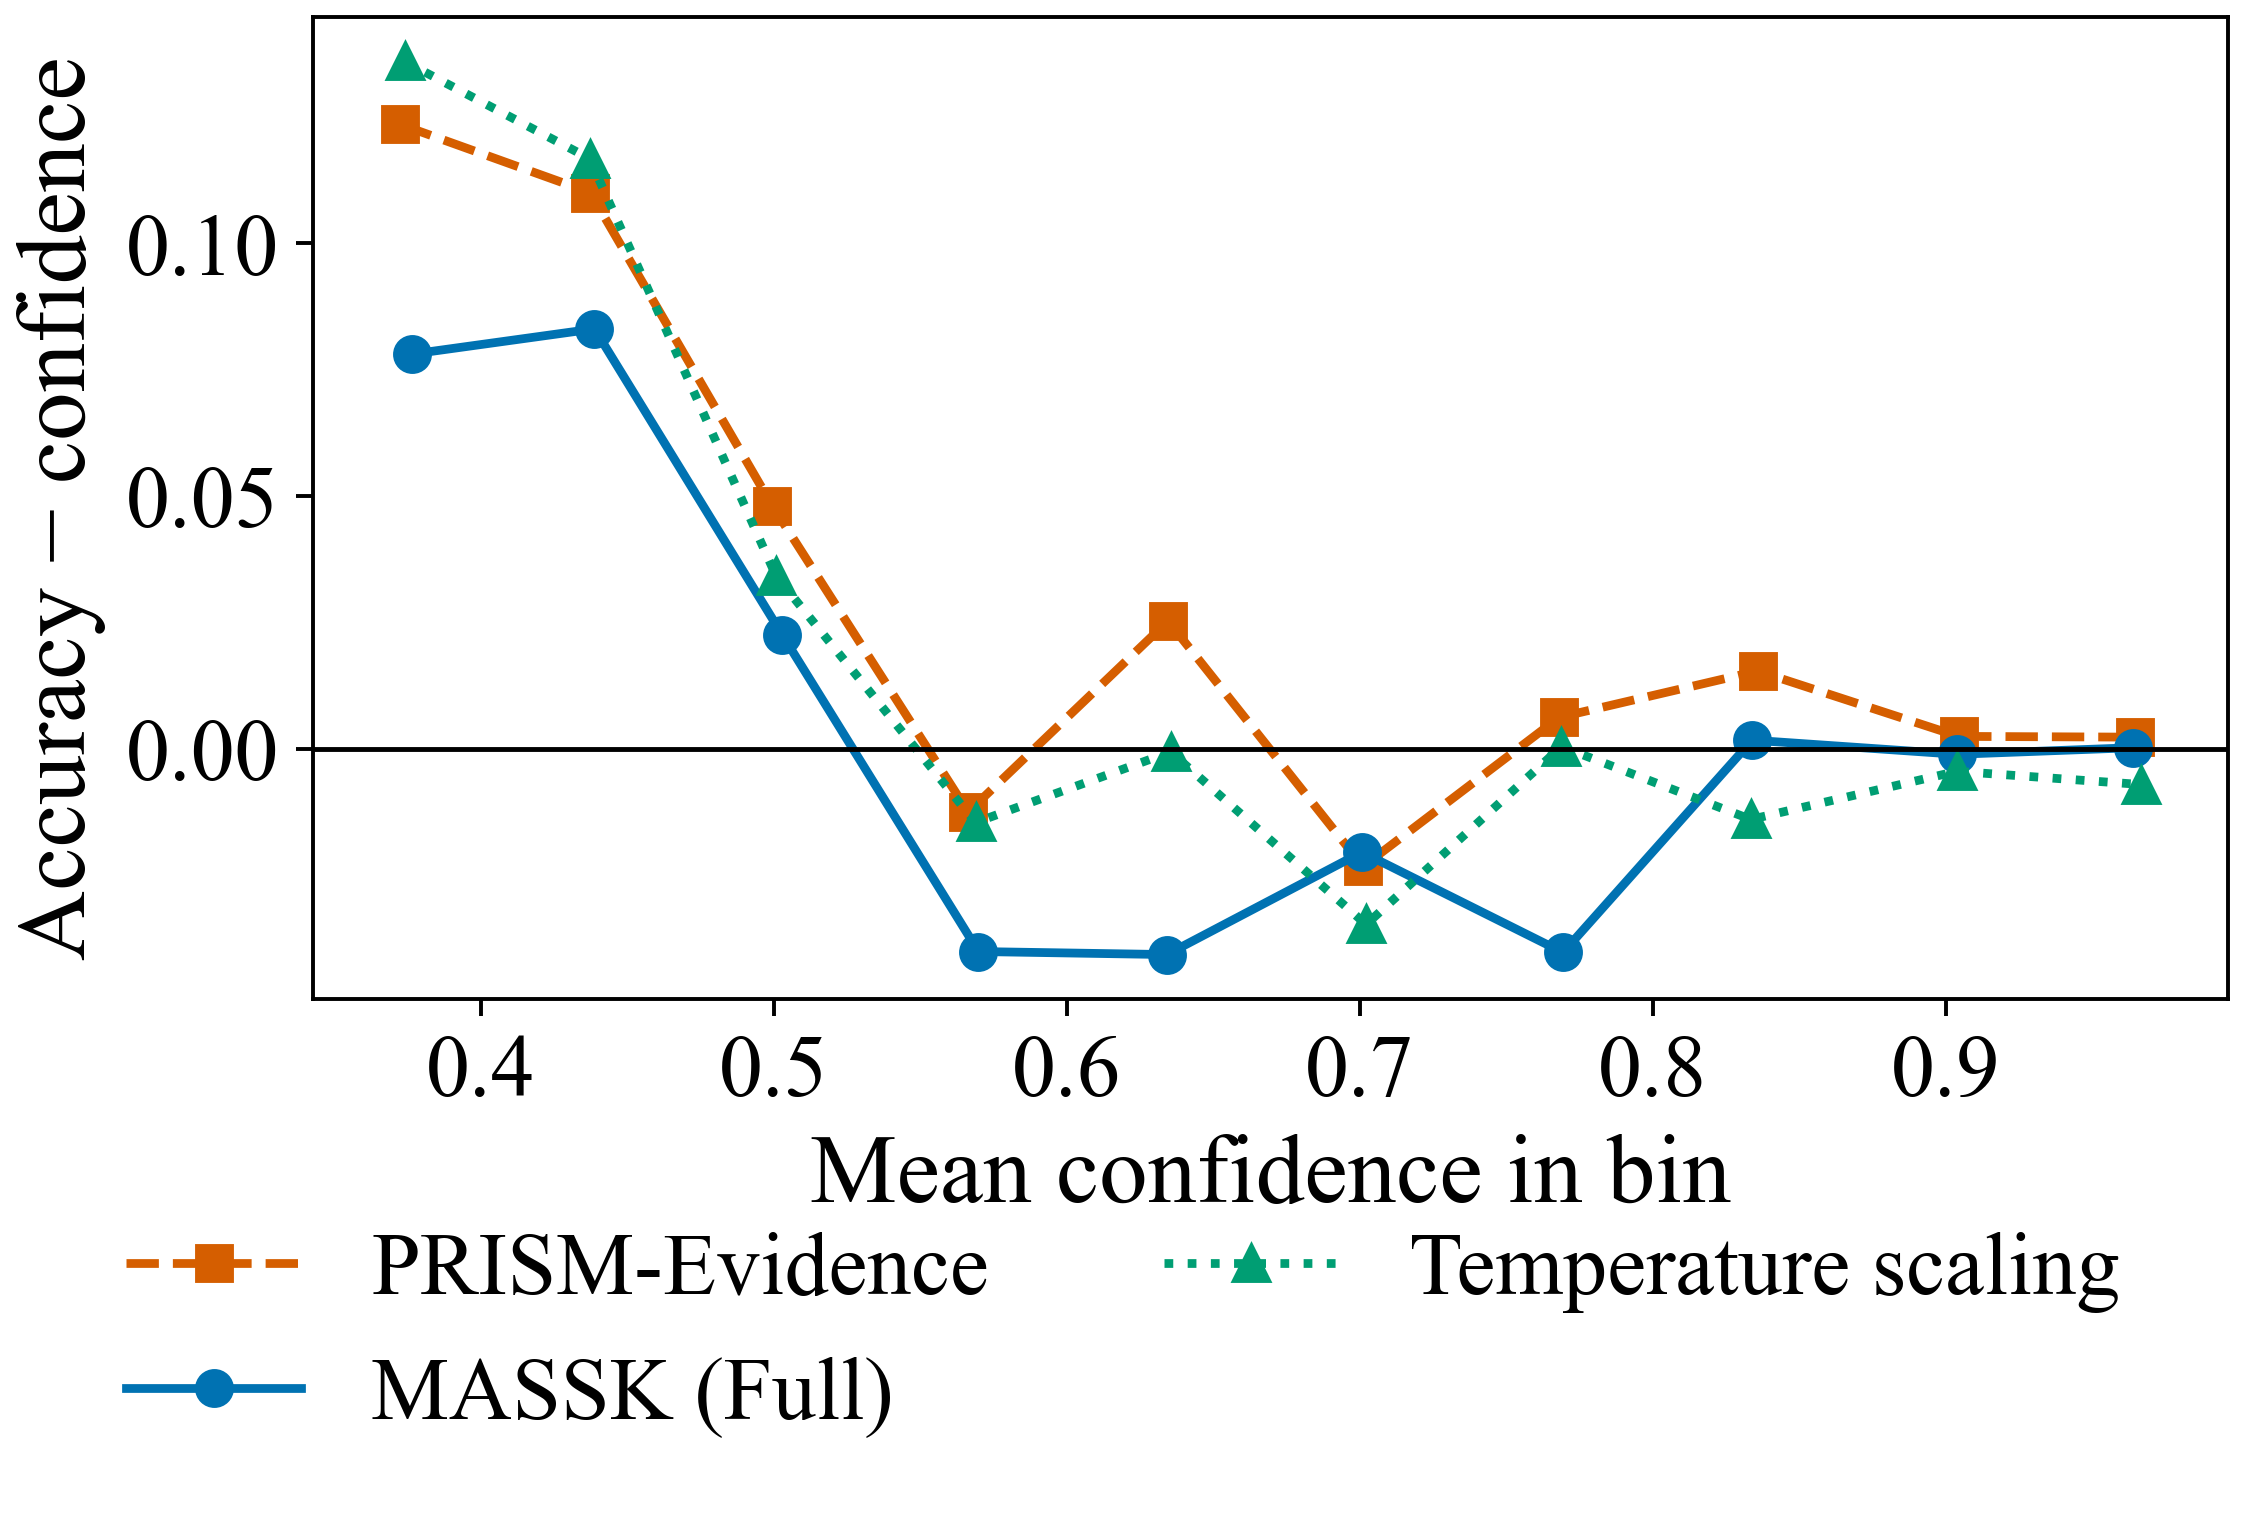

**Figure 6.1. Calibration gap (accuracy − confidence) by confidence bin under E1 for PRISM-Evidence, MASSK (Full) and the calibration control with the lowest NLL (Temperature scaling). Fifteen equal-width bins; bins with fewer than 30 publications are omitted. Values below zero indicate overconfidence.**

In [15]:
BEST_CONTROL = E1.loc[["C1", "C2", "C3"], "NLL"].idxmin()
MIN_BIN = 30
rows = []
for vid in ["V0", "V1", BEST_CONTROL]:
    p = normalise(PAPER[vid])
    conf, correct = p.max(axis=1), (p.argmax(axis=1) == y).astype(float)
    for b, (lo, hi) in enumerate(zip(ECE_EDGES[:-1], ECE_EDGES[1:])):
        m = (conf > lo) & (conf <= hi)
        if m.sum() >= MIN_BIN:
            rows.append({"variant_id": vid, "variant": VARIANTS[vid]["name"], "bin": b,
                         "publications": int(m.sum()), "mean_confidence": conf[m].mean(),
                         "accuracy": correct[m].mean(), "gap": correct[m].mean() - conf[m].mean()})
calibration = pd.DataFrame(rows)
CAPTION_F6_1 = ("Figure 6.1. Calibration gap (accuracy − confidence) by confidence bin under E1 for "
                f"PRISM-Evidence, MASSK (Full) and the calibration control with the lowest NLL "
                f"({VARIANTS[BEST_CONTROL]['name']}). Fifteen equal-width bins; bins with fewer than "
                f"{MIN_BIN} publications are omitted. Values below zero indicate overconfidence.")
calibration.to_csv(TABLES / "figure6_1_calibration_gap.csv", index=False)

fig, ax = plt.subplots(figsize=(6.4, 4.4))
for vid, marker, style in zip(["V0", "V1", BEST_CONTROL], ["s", "o", "^"], ["--", "-", ":"]):
    part = calibration[calibration["variant_id"] == vid]
    ax.plot(part["mean_confidence"], part["gap"], marker=marker, linestyle=style,
            markersize=7, linewidth=1.8, color=MODEL_COLOUR.get(vid, MODEL_COLOUR["control"]),
            label=VARIANTS[vid]["name"])
ax.axhline(0.0, color="black", linewidth=1.0)
ax.set_xlabel("Mean confidence in bin")
ax.set_ylabel("Accuracy − confidence")
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
show_figure(fig, "figure6_1_calibration_gap", CAPTION_F6_1, "4")

**Interpretation.**

- **Brier score** follows NLL. Full is better than PRISM-Evidence and the controls ($\Delta$ from +0.0031 to +0.0046, intervals above zero), while the shared-coefficient variant is nominally better than Full ($\Delta = -0.0006$ [−0.0011, −0.0001]).
- **Predicted classes are unchanged.** All accuracy, MCC and macro-F1 differences among V0–V4 and C1–C3 have intervals that include zero. The correction changes probabilities, not labels.
- **The confidence multiplier is associated with calibration, not with NLL.** ECE is 0.0141 with the multiplier and 0.0218 without it (V3), but the interval of the difference includes zero ($\Delta = +0.0077$ [−0.0016, +0.0100]).
- **Parameters.** The coefficients are small: 0.035–0.183 by class in Full, with the weakest correction for Computer Science, and 0.112 ± 0.016 when shared. Temperature scaling selects $\tau = 0.957$, a slight sharpening.
- **Figure 6.1.** Below a confidence of 0.5, PRISM-Evidence is underconfident by 0.05–0.12, and the correction reduces this to 0.02–0.08. Between 0.55 and 0.80 the corrected model is overconfident by 0.02–0.04.

## 5. RQ3: sensitivity to the neighbour count, temperature and probability floor

**Question.** Is the effect of the correction stable across $k$, $T$ and $\varepsilon$?

**Method.** One factor is changed at a time from the default ($k = 5$, $T = 0.07$, $\varepsilon = 10^{-7}$). The eight coefficients are refitted for each setting with the same procedure, and E1 NLL is compared with PRISM-Evidence. The grid is descriptive: the default is retained whatever the result.

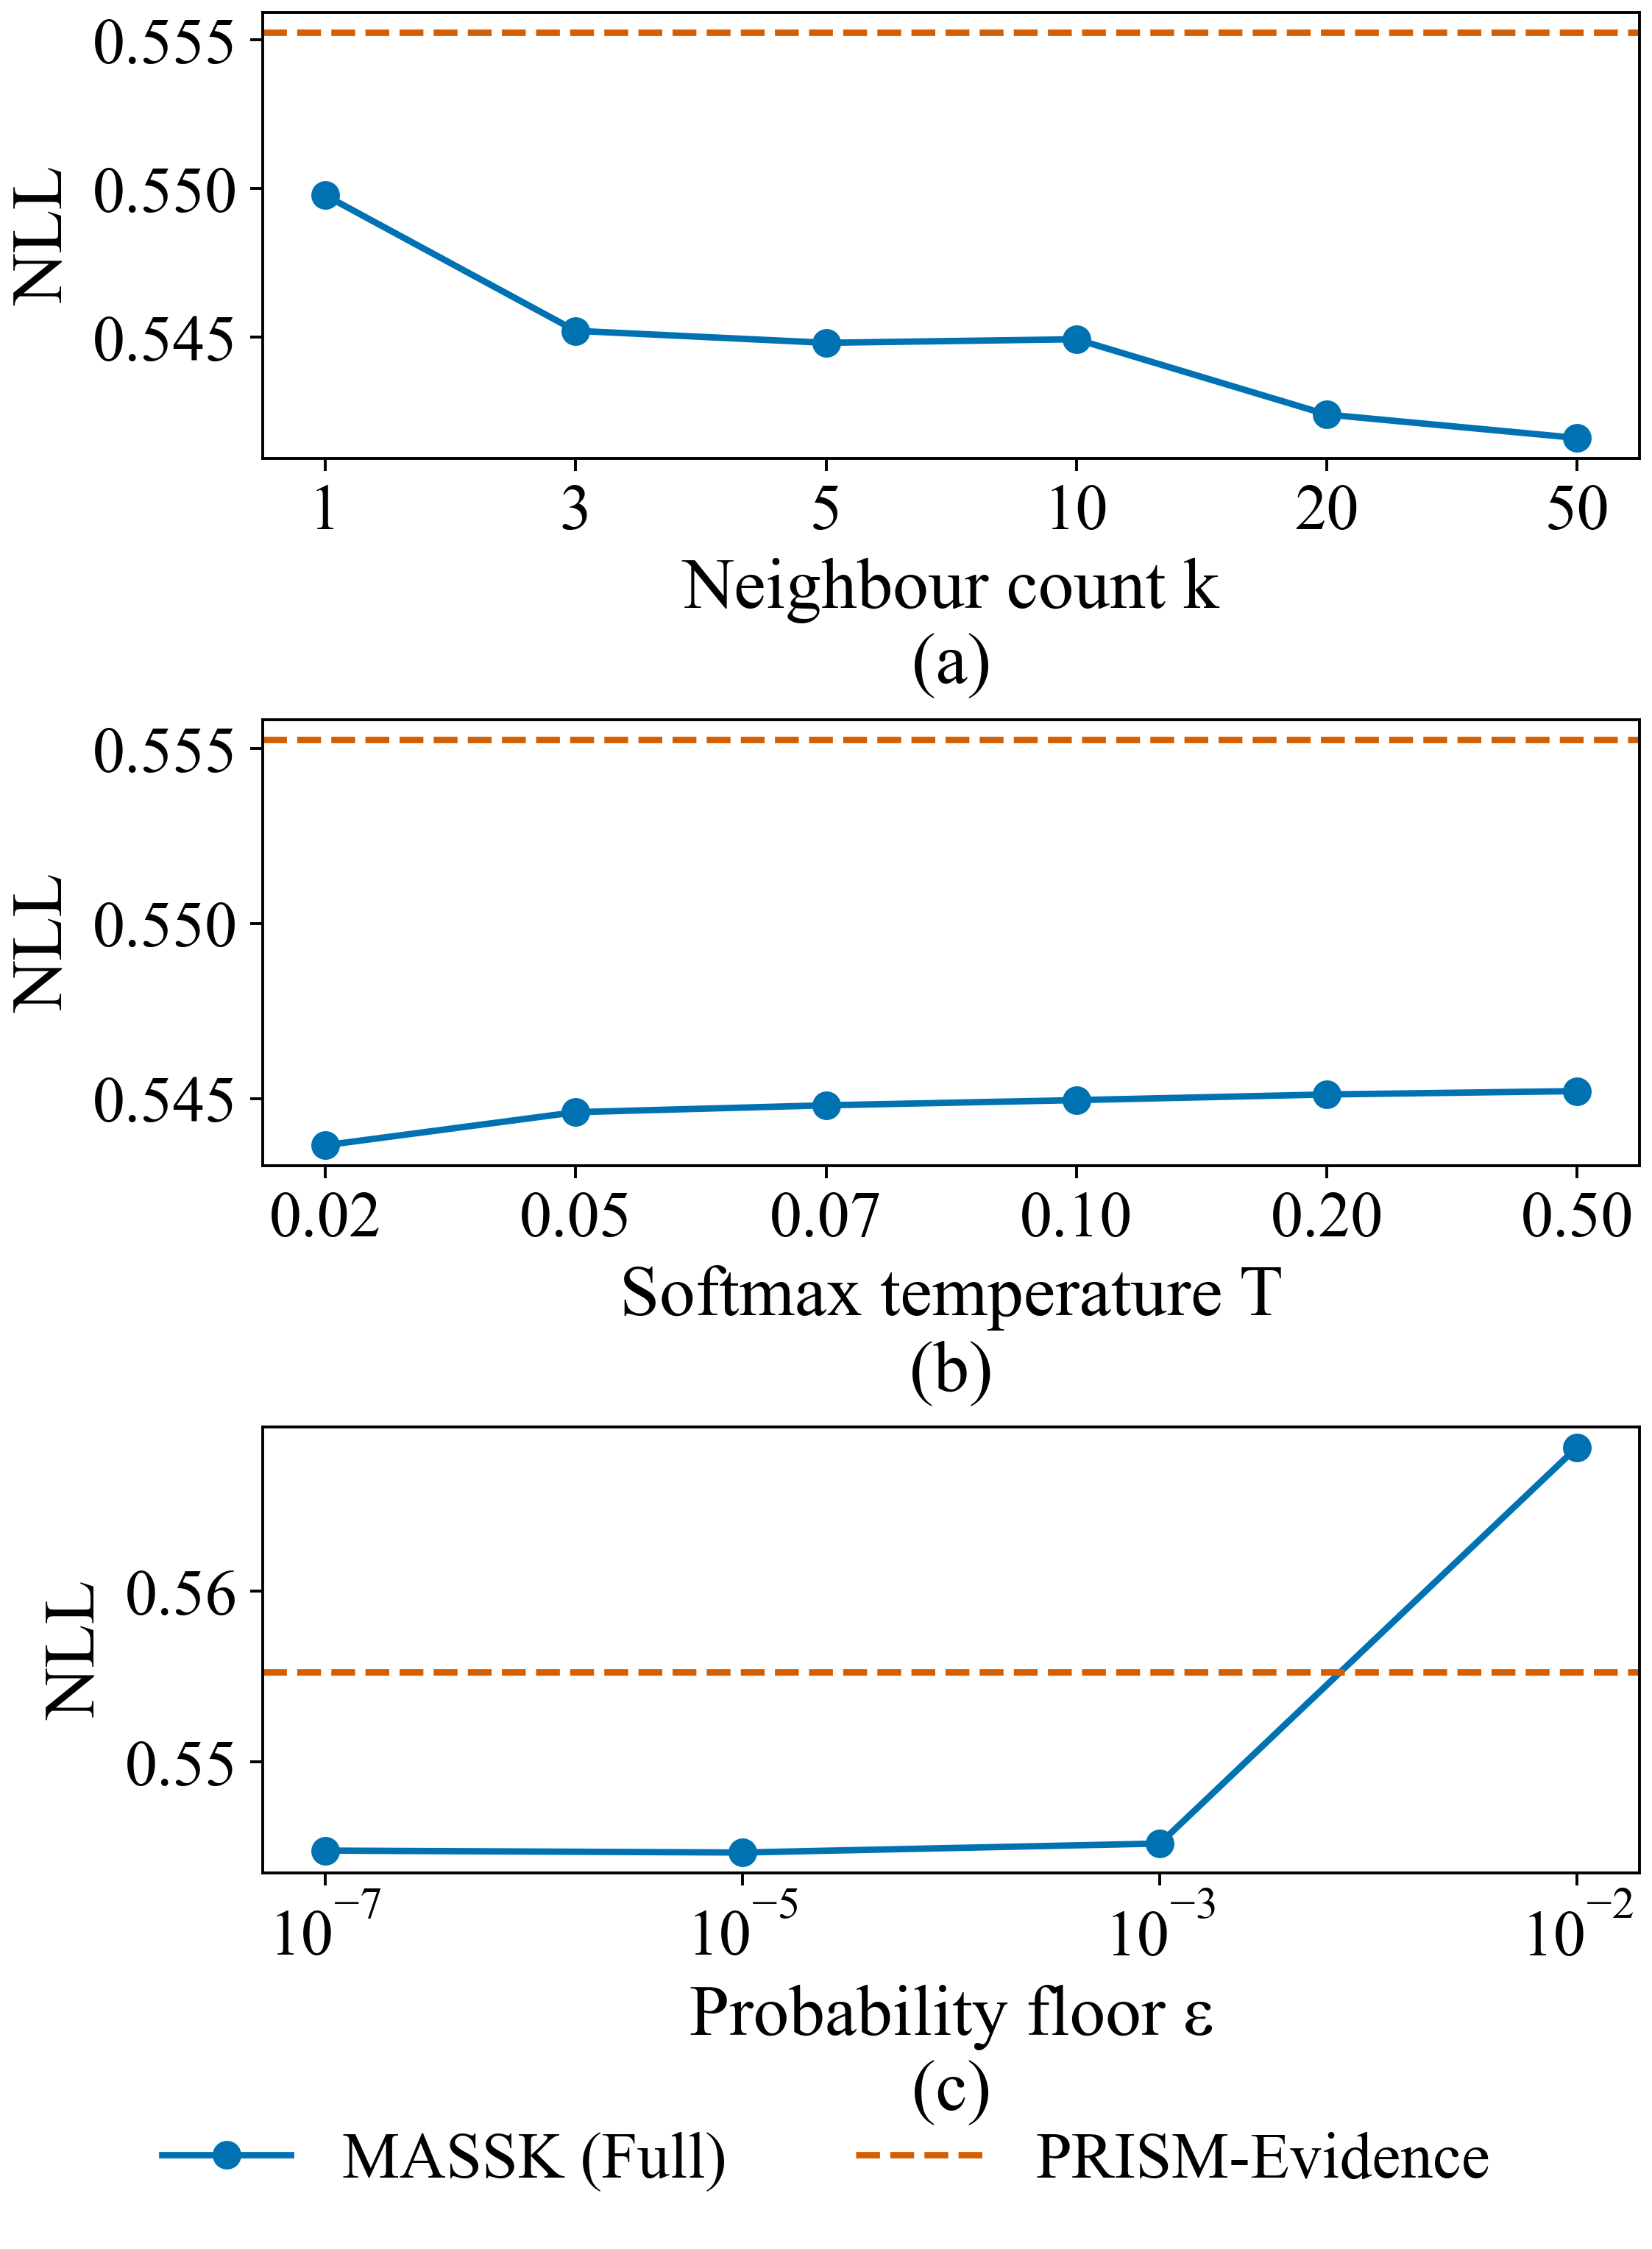

**Figure 6.2. Sensitivity of MASSK (Full) E1 NLL to one factor at a time, with the coefficients refitted at each setting: (a) neighbour count k; (b) softmax temperature T; (c) probability floor ε. The dashed line is PRISM-Evidence (NLL 0.5552). Across the 16 settings NLL ranges from 0.5416 to 0.5684; the default setting is k = 5, T = 0.07, ε = 10⁻⁷.**

In [16]:
def full_at(k: int, temperature: float, eps: float) -> dict:
    """E1 metrics and the mean per-context NLL of MASSK (Full) refitted at one setting."""
    post, _ = run_variant("full", k, temperature, eps)
    per_context = [metrics(post[r, ctx[(r, f)]["hi"]], y[ctx[(r, f)]["hi"]])["NLL"] for r, f in CONTEXTS]
    return {**metrics(post.mean(axis=0), y), "NLL_context_mean": float(np.mean(per_context))}


grid = ([("k", float(v), {"k": int(v), "temperature": DEFAULT["temperature"],
                          "eps": DEFAULT["probability_floor"]}) for v in CFG["sensitivity"]["top_k"]]
        + [("T", float(v), {"k": DEFAULT["top_k"], "temperature": float(v),
                            "eps": DEFAULT["probability_floor"]}) for v in CFG["sensitivity"]["temperature"]]
        + [("eps", float(v), {"k": DEFAULT["top_k"], "temperature": DEFAULT["temperature"],
                              "eps": float(v)}) for v in CFG["sensitivity"]["probability_floor"]])
sensitivity = pd.DataFrame([{"factor": factor, "value": value, **full_at(**kwargs)}
                            for factor, value, kwargs in grid])
sensitivity["delta_nll_vs_prism"] = E1.loc["V0", "NLL"] - sensitivity["NLL"]
sensitivity["delta_macro_f1_vs_prism"] = sensitivity["Macro-F1"] - E1.loc["V0", "Macro-F1"]
sensitivity.to_csv(TABLES / "figure6_2_sensitivity.csv", index=False)

best = sensitivity.loc[sensitivity["NLL"].idxmin()]
worst = sensitivity.loc[sensitivity["NLL"].idxmax()]
CAPTION_F6_2 = ("Figure 6.2. Sensitivity of MASSK (Full) E1 NLL to one factor at a time, with the "
                "coefficients refitted at each setting: (a) neighbour count k; (b) softmax "
                "temperature T; (c) probability floor ε. The dashed line is PRISM-Evidence "
                f"(NLL {fmt_num(E1.loc['V0', 'NLL'])}). Across the 16 settings NLL ranges from "
                f"{fmt_num(best['NLL'])} to {fmt_num(worst['NLL'])}; the default setting is "
                "k = 5, T = 0.07, ε = 10⁻⁷.")

panels = [("k", "Neighbour count k", [f"{int(v)}" for v in CFG["sensitivity"]["top_k"]]),
          ("T", "Softmax temperature T", [f"{v:.2f}" for v in CFG["sensitivity"]["temperature"]]),
          ("eps", "Probability floor ε",
           [f"$10^{{{int(np.round(np.log10(v)))}}}$" for v in CFG["sensitivity"]["probability_floor"]])]
fig, axes = plt.subplots(3, 1, figsize=(6.4, 8.8))
for ax, (factor, xlabel, ticklabels) in zip(axes, panels):
    part = sensitivity[sensitivity["factor"] == factor]
    x = np.arange(len(part))
    ax.plot(x, part["NLL"], marker="o", markersize=7, linewidth=1.8, color=MODEL_COLOUR["V1"],
            label="MASSK (Full)")
    ax.axhline(E1.loc["V0", "NLL"], linestyle="--", linewidth=1.8, color=MODEL_COLOUR["V0"],
               label="PRISM-Evidence")
    ax.set_xticks(x, ticklabels)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("NLL")
label_panels(axes)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
show_figure(fig, "figure6_2_sensitivity", CAPTION_F6_2, "5")

**Interpretation.** MASSK (Full) has a lower NLL than PRISM-Evidence in 15 of the 16 settings.

- **Temperature** has almost no influence (NLL 0.5437–0.5452).
- **Neighbour count.** NLL falls from 0.5498 at $k = 1$ to 0.5416 at $k = 50$, so the default $k = 5$ (0.5448) is not the best setting on this panel. With $k = 1$, macro-F1 is 0.0028 below PRISM-Evidence.
- **Probability floor.** Values up to $10^{-3}$ leave NLL unchanged (0.5447–0.5452). A floor of $10^{-2}$ raises NLL to 0.5684, above PRISM-Evidence. The floor applies to both posteriors, so this value also flattens the base posterior; the two effects were not separated.

The default is retained as predeclared. The dependence on $k$ is a limitation of the fixed setting.

## 6. RQ4: retrieval quality of the frozen similarity

**Question.** What retrieval quality does the frozen dual-view similarity achieve, compared with each single view, when no vector involves label training?

**Method.** Queries are the outer-held publications of a context, and the index contains its outer-training publications. Similarity is the cosine of the frozen L2-normalised vectors: the dual-view mean, Qwen3 only, or SPECTER2 only. A retrieved publication is relevant if it has the same thematic class as the query, so the measures describe class consistency of neighbours and not topical relevance. With binary relevance, $\mathrm{nDCG@10} = \sum_{r=1}^{10} \mathrm{rel}_r / \log_2(r+1)$ divided by the same sum with ten relevant results; every class has more than ten publications in every index.

In [17]:
CUTOFF = int(CFG["retrieval_eval_cutoff"])
DISCOUNT = 1.0 / np.log2(np.arange(2, CUTOFF + 2))


def retrieval_metrics(labels: np.ndarray, target: np.ndarray) -> dict:
    """nDCG, precision and reciprocal rank at the cutoff with same-class relevance."""
    rel = (labels[:, :CUTOFF] == target[:, None]).astype(float)
    first = np.where(rel.any(axis=1), rel.argmax(axis=1) + 1.0, np.inf)
    return {"ndcg": float(((rel * DISCOUNT).sum(axis=1) / DISCOUNT.sum()).mean()),
            "precision": float(rel.mean()), "mrr": float((1.0 / first).mean())}


rows = []
for view_name, label in [("dual", "Dual view (Qwen3 + SPECTER2)"), ("qwen3", "Qwen3 only"),
                         ("specter2", "SPECTER2 only")]:
    per = []
    for key in CONTEXTS:
        c = ctx[key]
        labels = (NB_ALL[key]["outer_lab"] if view_name == "dual"
                  else top_neighbours(c["hi"], c["ti"], view=view_name, kmax=CUTOFF)[1])
        per.append(retrieval_metrics(labels, y[c["hi"]]))
    per = pd.DataFrame(per)
    rows.append({"similarity": label, **{f"{m}_mean": per[m].mean() for m in per},
                 **{f"{m}_sd": per[m].std(ddof=1) for m in per}})
retrieval = pd.DataFrame(rows)
CAPTION_6_8 = ("Table 6.8. Retrieval with frozen cosine similarity and same-class relevance: "
               "mean ± SD over the six outer contexts (queries: outer-held publications; index: "
               "outer-training publications; cutoff 10).")
save_table(retrieval, "table6_8_frozen_retrieval", CAPTION_6_8, "6")

view = pd.DataFrame({
    "Similarity": retrieval["similarity"],
    "nDCG@10": [fmt_pm(a, b) for a, b in zip(retrieval["ndcg_mean"], retrieval["ndcg_sd"])],
    "Precision@10": [fmt_pm(a, b) for a, b in zip(retrieval["precision_mean"], retrieval["precision_sd"])],
    "MRR@10": [fmt_pm(a, b) for a, b in zip(retrieval["mrr_mean"], retrieval["mrr_sd"])],
}).set_index("Similarity")
show_table(view, CAPTION_6_8)

**Table 6.8. Retrieval with frozen cosine similarity and same-class relevance: mean ± SD over the six outer contexts (queries: outer-held publications; index: outer-training publications; cutoff 10).**

,nDCG@10,Precision@10,MRR@10
Similarity,,,
Dual view (Qwen3 + SPECTER2),0.7077 ± 0.0056,0.6970 ± 0.0056,0.8282 ± 0.0042
Qwen3 only,0.7070 ± 0.0074,0.6968 ± 0.0075,0.8296 ± 0.0081
SPECTER2 only,0.6832 ± 0.0057,0.6739 ± 0.0063,0.8071 ± 0.0051


**Interpretation.** With frozen vectors, the dual-view similarity reaches an nDCG@10 of 0.7077 ± 0.0056, the same as Qwen3 alone (0.7070 ± 0.0074) and above SPECTER2 alone (0.6832 ± 0.0057). Adding SPECTER2 to Qwen3 gives no measurable retrieval gain under same-class relevance. The value of 0.7807 recorded in notebook 04 was obtained with projection heads trained on class labels; it does not describe the frozen similarity defined in Section 2. Same-class relevance measures the class consistency of neighbours, not topical relevance; Section 12 examines relevance at the level of subfields, primary topics and shared references.

## 7. RQ5: influence of the arXiv pilot cohort

**Question.** Does the effect persist when the 1,176 arXiv publications dated 2026 are excluded from the retrieval index and from evaluation?

**Method.** (a) PRISM-Evidence and MASSK (Full) are evaluated on the OpenAlex publications only. (b) The coefficients are refitted with the pilot publications removed from every retrieval index, and the result is evaluated on the OpenAlex publications. The pilot rows are also evaluated separately as a descriptive complement. PRISM-Evidence itself was trained with the pilot rows; retraining it is outside run rev01. $\Delta\mathrm{NLL} = \mathrm{NLL}_{\text{PRISM}} - \mathrm{NLL}_{\text{model}}$, so positive values favour the corrected model.

In [18]:
POST_NO_PILOT, PARAMS_NO_PILOT = run_variant("full", DEFAULT["top_k"], DEFAULT["temperature"],
                                             DEFAULT["probability_floor"], neighbours=NB_NO_PILOT)
PAPER_NO_PILOT = POST_NO_PILOT.mean(axis=0)


def per_paper_nll(p: np.ndarray) -> np.ndarray:
    """Negative log-likelihood of each publication."""
    return -np.log(normalise(p)[np.arange(N), y])


NLL_BASE = per_paper_nll(PAPER["V0"])
rows = []
for subset_name, mask in [("OpenAlex", ~is_pilot), ("arXiv pilot", is_pilot)]:
    candidates = [("PRISM-Evidence", "none", PAPER["V0"]), ("MASSK (Full)", "all development rows", PAPER["V1"])]
    if subset_name == "OpenAlex":
        candidates.append(("MASSK (Full), refitted", "pilot rows excluded", PAPER_NO_PILOT))
    for model, index_name, paper in candidates:
        m = metrics(paper[mask], y[mask])
        diff = (NLL_BASE - per_paper_nll(paper))[mask]
        boot = bootstrap_mean(diff, N_BOOT, SEED) if model != "PRISM-Evidence" else np.zeros(2)
        rows.append({"evaluation_rows": subset_name, "publications": int(mask.sum()), "model": model,
                     "retrieval_index": index_name, "nll": m["NLL"], "macro_f1": m["Macro-F1"],
                     "delta_nll": float(diff.mean()), "delta_ci_low": float(np.quantile(boot, 0.025)),
                     "delta_ci_high": float(np.quantile(boot, 0.975))})
pilot = pd.DataFrame(rows)
CAPTION_6_9 = ("Table 6.9. Influence of the arXiv pilot cohort under E1. ΔNLL is PRISM-Evidence "
               "minus the row model with an unadjusted 95 % paired bootstrap interval; positive "
               "values favour the row model (n/a for the PRISM-Evidence rows, which are the reference).")
save_table(pilot, "table6_9_pilot_exclusion", CAPTION_6_9, "7")

view = pd.DataFrame({
    "Evaluation rows": [f"{a} (n = {b:d})" for a, b in zip(pilot["evaluation_rows"], pilot["publications"])],
    "Model": pilot["model"],
    "Retrieval index": pilot["retrieval_index"],
    "NLL": pilot["nll"].map(fmt_num),
    "Macro-F1": pilot["macro_f1"].map(fmt_num),
    "ΔNLL [95 % CI]": ["n/a" if model == "PRISM-Evidence" else f"{fmt_signed(d)} {fmt_ci(a, b)}"
                        for model, d, a, b in zip(pilot["model"], pilot["delta_nll"],
                                                  pilot["delta_ci_low"], pilot["delta_ci_high"])],
}).set_index("Evaluation rows")
show_table(view, CAPTION_6_9)

**Table 6.9. Influence of the arXiv pilot cohort under E1. ΔNLL is PRISM-Evidence minus the row model with an unadjusted 95 % paired bootstrap interval; positive values favour the row model (n/a for the PRISM-Evidence rows, which are the reference).**

,Model,Retrieval index,NLL,Macro-F1,ΔNLL [95 % CI]
Evaluation rows,,,,,
OpenAlex (n = 5532),PRISM-Evidence,none,0.5784,0.7964,n/a
OpenAlex (n = 5532),MASSK (Full),all development rows,0.5686,0.7973,"+0.0099 [+0.0065, +0.0133]"
OpenAlex (n = 5532),"MASSK (Full), refitted",pilot rows excluded,0.5652,0.7992,"+0.0133 [+0.0105, +0.0161]"
arXiv pilot (n = 1176),PRISM-Evidence,none,0.4461,0.8537,n/a
arXiv pilot (n = 1176),MASSK (Full),all development rows,0.4330,0.8521,"+0.0130 [+0.0065, +0.0193]"


**Interpretation.** On the 5,532 OpenAlex publications, the NLL gain over PRISM-Evidence is +0.0099 [+0.0065, +0.0133] with the full index, and +0.0133 [+0.0105, +0.0161] when the pilot publications are removed from every retrieval index and the coefficients are refitted. The gain therefore does not depend on the pilot cohort as a source of neighbours. On the pilot publications themselves the gain is +0.0130 [+0.0065, +0.0193]. Two limits remain: PRISM-Evidence was trained with the pilot rows, and the 2025 and external cohorts were not opened in this run.

## 8. RQ6: dependence on near-identical neighbours

**Question.** Is the effect concentrated in publications whose nearest training neighbour is almost identical?

**Method.** For each held-out publication, the maximum dual-view cosine to the outer-training publications is computed in each repeat and averaged. Publications are divided into quintiles of this similarity. $\Delta\mathrm{NLL} = \mathrm{NLL}_{\text{PRISM}} - \mathrm{NLL}_{\text{MASSK}}$ under E1 is reported per quintile with a 95 % bootstrap interval. A gain confined to the highest quintile would indicate that the correction mostly exploits near-duplicates that the grouping did not separate.

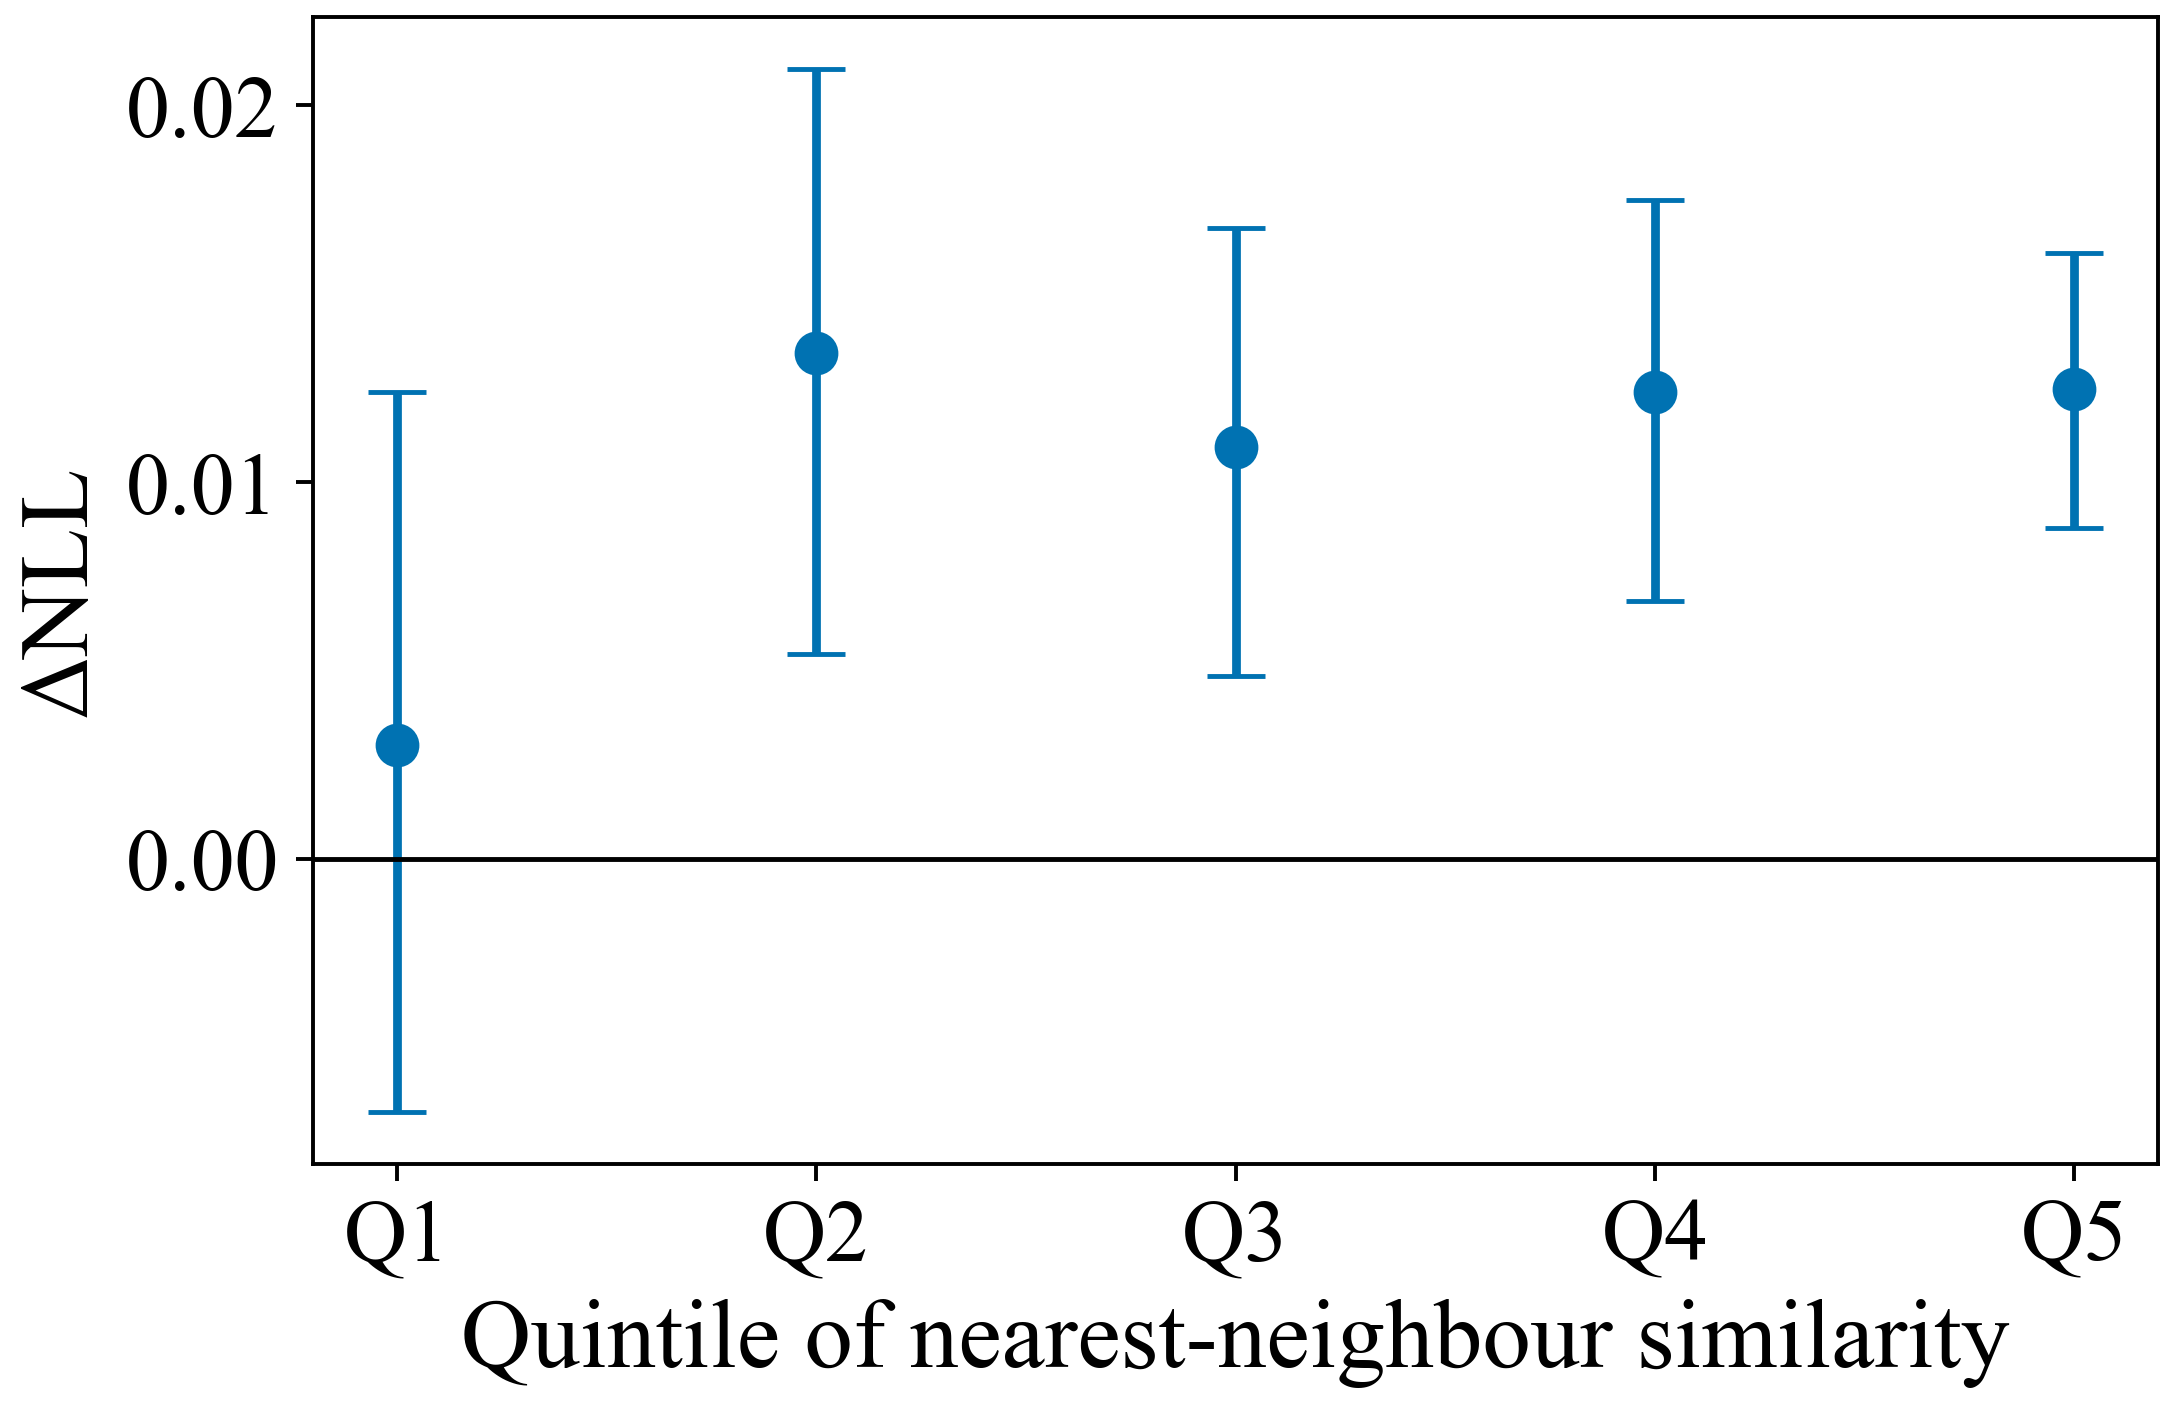

**Figure 6.3. ΔNLL (PRISM-Evidence − MASSK) under E1 by quintile of the similarity between a held-out publication and its nearest outer-training neighbour. Points are quintile means; bars are 95 % bootstrap intervals (20,000 resamples). Positive values favour MASSK. Similarity ranges: Q1: 0.570–0.757; Q2: 0.757–0.803; Q3: 0.803–0.835; Q4: 0.835–0.865; Q5: 0.865–0.973. Each quintile contains 1341–1342 publications.**

In [19]:
max_similarity = np.zeros((2, N))
for (r, f), c in ctx.items():
    max_similarity[r, c["hi"]] = NB_ALL[(r, f)]["outer_val"][:, 0]
nearest = max_similarity.mean(axis=0)
quintile = pd.qcut(nearest, 5, labels=False)
gain = NLL_BASE - per_paper_nll(PAPER["V1"])
rows = []
for q in range(5):
    m = quintile == q
    boot = bootstrap_mean(gain[m], N_BOOT, SEED)
    rows.append({"quintile": q + 1, "publications": int(m.sum()),
                 "similarity_min": float(nearest[m].min()), "similarity_max": float(nearest[m].max()),
                 "nll_prism": float(NLL_BASE[m].mean()),
                 "nll_massk": float(per_paper_nll(PAPER["V1"])[m].mean()),
                 "delta_nll": float(gain[m].mean()), "delta_ci_low": float(np.quantile(boot, 0.025)),
                 "delta_ci_high": float(np.quantile(boot, 0.975))})
dependence = pd.DataFrame(rows)
dependence.to_csv(TABLES / "figure6_3_neighbour_similarity.csv", index=False)
ranges = "; ".join(f"Q{int(r.quintile)}: {fmt_num(r.similarity_min, 3)}–{fmt_num(r.similarity_max, 3)}"
                   for r in dependence.itertuples())
CAPTION_F6_3 = ("Figure 6.3. ΔNLL (PRISM-Evidence − MASSK) under E1 by quintile of the similarity "
                "between a held-out publication and its nearest outer-training neighbour. Points are "
                "quintile means; bars are 95 % bootstrap intervals (20,000 resamples). Positive "
                f"values favour MASSK. Similarity ranges: {ranges}. Each quintile contains "
                f"{int(dependence['publications'].min())}–{int(dependence['publications'].max())} publications.")

fig, ax = plt.subplots(figsize=(6.2, 4.0))
x = np.arange(1, 6)
ax.errorbar(x, dependence["delta_nll"],
            yerr=[dependence["delta_nll"] - dependence["delta_ci_low"],
                  dependence["delta_ci_high"] - dependence["delta_nll"]],
            fmt="o", markersize=8, capsize=6, linewidth=1.8, color=MODEL_COLOUR["V1"])
ax.axhline(0.0, color="black", linewidth=1.0)
ax.set_xticks(x, [f"Q{i}" for i in x])
ax.set_xlabel("Quintile of nearest-neighbour similarity")
ax.set_ylabel("ΔNLL")
show_figure(fig, "figure6_3_neighbour_similarity", CAPTION_F6_3, "8")

**Interpretation.** The gain is not confined to near-identical neighbours. It is of similar size in Q2–Q5 (+0.0109 to +0.0134, all intervals above zero), including Q2 with similarities of 0.757–0.803. In the lowest quintile (similarity below 0.757) the gain is +0.0030 [−0.0067, +0.0124] and cannot be distinguished from zero. The correction gives no measurable benefit for publications without a close neighbour in the index. This is consistent with the loss of benefit recorded on the external cohort, but that cohort was not analysed here.

## 9. Stress evaluation with one implementation

**Question.** Does the correction improve probability quality on the temporal and external cohorts when one fully specified system is evaluated, and under which conditions does it help?

**Method.** The base posterior follows the recorded stress specification: three seeds each of a Qwen3 path, a SPECTER2 path and an interaction path; the consensus is the mean of the two single-view posteriors; the base posterior is the equal blend of consensus and interaction. The evidence router is not part of the evaluated system, because it failed its activation gate in the recorded fit. Three bases are compared:

| ID | Base | Fit rows | Stop rows |
|---|---|---|---|
| B0 | Frozen recorded model (fitted on a GPU) | repeat 0, outer folds 1–2 | outer fold 0 |
| B1 | Refit in this notebook on CPU, same rows | as B0 | as B0 |
| B2 (primary) | Refit in this notebook on CPU without the arXiv pilot rows | B0 fit rows minus pilot | B0 stop rows minus pilot |

For each base, the correction variants and calibration controls of Section 2 are fitted on the stop rows of that base, with its fit rows as the retrieval index. The same index is used for the cohorts, so the base and the correction see the same labelled publications. B2 contains no publication later than 2024 and only OpenAlex field labels. The stop rows also selected the early-stopping epoch of the paths, so base posteriors on them are slightly optimistic.

Both cohorts were evaluated before, and their recorded results are known. This section is therefore retrospective: it describes the evaluated system and cannot confirm a benefit. The primary family has eight comparisons on base B2 with NLL as endpoint: cohorts {temporal, external} × variants {V1, V4} × comparators {V0, C1}, with a paired document bootstrap (20,000 resamples) and the Holm correction. A variant is supported on a cohort if both comparisons favour it after adjustment and the lower 95 % bound of $\Delta$Macro-F1 against V0 is at least −0.003.

In [20]:
S2 = CFG["step2"]
BASE = S2["base"]
nn = torch.nn


class AtomicPath(nn.Module):
    """Single-view path of the recorded base specification."""

    def __init__(self, width: int):
        super().__init__()
        d = BASE["d_model"]
        self.projection = nn.Sequential(nn.LayerNorm(width), nn.Linear(width, d), nn.GELU(),
                                        nn.Dropout(BASE["core_dropout"]))
        self.position = nn.Parameter(torch.randn(1, d) * 0.01)
        self.state_norm = nn.LayerNorm(d)
        self.head = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, K))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.head(self.state_norm(self.projection(x) + self.position))


class InteractionPath(nn.Module):
    """Two-view interaction path of the recorded base specification."""

    def __init__(self, qwen_width: int, specter_width: int):
        super().__init__()
        d, rank, drop = BASE["d_model"], BASE["interaction_rank"], BASE["interaction_dropout"]

        def projector(width: int) -> nn.Sequential:
            return nn.Sequential(nn.LayerNorm(width), nn.Linear(width, d), nn.GELU(),
                                 nn.Dropout(drop), nn.LayerNorm(d))

        self.q_projection = projector(qwen_width)
        self.s_projection = projector(specter_width)
        self.q_head = nn.Linear(d, K)
        self.s_head = nn.Linear(d, K)
        self.reliability = nn.Sequential(nn.Linear(3, 16), nn.GELU(), nn.Linear(16, 1))
        self.residual = nn.Sequential(nn.LayerNorm(3 * d), nn.Linear(3 * d, rank), nn.GELU(),
                                      nn.Dropout(drop), nn.Linear(rank, K))
        nn.init.zeros_(self.residual[-1].weight)
        nn.init.zeros_(self.residual[-1].bias)

    @staticmethod
    def evidence(logits: torch.Tensor, state: torch.Tensor) -> torch.Tensor:
        p = logits.softmax(dim=1)
        entropy = -(p * (p + 1e-8).log()).sum(dim=1, keepdim=True) / math.log(K)
        top = p.topk(2, dim=1).values
        norm = state.norm(dim=1, keepdim=True) / math.sqrt(state.shape[1])
        return torch.cat([1 - entropy, top[:, :1] - top[:, 1:2], norm], dim=1)

    def forward(self, qwen: torch.Tensor, specter: torch.Tensor):
        q_state, s_state = self.q_projection(qwen), self.s_projection(specter)
        q_logits, s_logits = self.q_head(q_state), self.s_head(s_state)
        scores = torch.cat([self.reliability(self.evidence(q_logits, q_state)),
                            self.reliability(self.evidence(s_logits, s_state))], dim=1)
        gate = scores.softmax(dim=1)[:, :1]
        anchor = gate * q_logits + (1 - gate) * s_logits
        shared = gate * q_state + (1 - gate) * s_state
        interaction = torch.cat([shared, torch.abs(q_state - s_state), q_state * s_state], dim=1)
        logits = anchor + BASE["interaction_cap"] * torch.tanh(self.residual(interaction))
        return logits, q_logits, s_logits


def softmax_np(logits: np.ndarray, temperature: float = 1.0) -> np.ndarray:
    """Temperature-scaled softmax in float64."""
    z = np.asarray(logits, np.float64) / float(temperature)
    z -= z.max(axis=1, keepdims=True)
    p = np.exp(z)
    return p / p.sum(axis=1, keepdims=True)


def fit_temperature(logits: np.ndarray, target: np.ndarray) -> float:
    """Temperature that minimises NLL (bounded search between 0.5 and 4)."""
    def objective(log_t: float) -> float:
        p = softmax_np(logits, math.exp(log_t))
        return float(-np.log(np.clip(p[np.arange(len(target)), target], 1e-12, 1.0)).mean())

    result = minimize_scalar(objective, bounds=(math.log(0.5), math.log(4.0)), method="bounded")
    return float(math.exp(result.x))


def path_logits(model: nn.Module, *features: torch.Tensor, batch: int = 1024) -> np.ndarray:
    """Logits of a path model in evaluation mode."""
    model.eval()
    out = []
    with torch.inference_mode():
        for start in range(0, len(features[0]), batch):
            result = model(*(f[start:start + batch] for f in features))
            out.append((result[0] if isinstance(result, tuple) else result).float())
    return torch.cat(out).numpy()


def copy_state(model: nn.Module) -> dict:
    """Detached copy of the model parameters."""
    return {name: value.detach().clone() for name, value in model.state_dict().items()}


def fit_atomic(features: torch.Tensor, target: np.ndarray, fit_rows: np.ndarray,
               stop_rows: np.ndarray, seed: int) -> dict:
    """Fit one single-view path with early stopping on the stop rows."""
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    model = AtomicPath(features.shape[1])
    optimiser = torch.optim.AdamW(model.parameters(), lr=BASE["core_lr"],
                                  weight_decay=BASE["core_weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimiser, T_max=BASE["core_max_epochs"])
    counts = np.bincount(target[fit_rows], minlength=K)
    weight = torch.tensor(len(fit_rows) / (K * np.maximum(counts, 1)), dtype=torch.float32)
    yt, stop_features = torch.from_numpy(target), features[torch.from_numpy(stop_rows)]
    best_score, best_state, stale = -np.inf, None, 0
    for epoch in range(BASE["core_max_epochs"]):
        model.train()
        order = rng.permutation(fit_rows)
        for start in range(0, len(order), BASE["core_batch"]):
            rows = torch.from_numpy(order[start:start + BASE["core_batch"]])
            loss = F.cross_entropy(model(features[rows]), yt[rows], weight=weight,
                                   label_smoothing=BASE["core_label_smoothing"])
            optimiser.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), BASE["gradient_clip"])
            optimiser.step()
        scheduler.step()
        if epoch % 2 == 0:
            pred = path_logits(model, stop_features).argmax(axis=1)
            score = (f1_score(target[stop_rows], pred, average="macro", zero_division=0)
                     + 0.1 * accuracy_score(target[stop_rows], pred))
            if score > best_score + 1e-4:
                best_score, best_state, stale = score, copy_state(model), 0
            else:
                stale += 1
            if epoch >= 12 and stale >= 5:
                break
    return best_state


def fit_interaction(qwen: torch.Tensor, specter: torch.Tensor, target: np.ndarray,
                    fit_rows: np.ndarray, stop_rows: np.ndarray, seed: int) -> tuple[dict, float]:
    """Fit one interaction path; return its parameters and stop-row temperature."""
    torch.manual_seed(seed)
    generator = torch.Generator().manual_seed(seed)
    model = InteractionPath(qwen.shape[1], specter.shape[1])
    optimiser = torch.optim.AdamW(model.parameters(), lr=BASE["interaction_lr"],
                                  weight_decay=BASE["interaction_weight_decay"])
    counts = np.bincount(target[fit_rows], minlength=K)
    weight = torch.tensor(np.sqrt(len(fit_rows) / (K * np.maximum(counts, 1))), dtype=torch.float32)
    yt, fit_t, stop_t = torch.from_numpy(target), torch.from_numpy(fit_rows), torch.from_numpy(stop_rows)
    best_score, best_state, stale = -np.inf, None, 0
    for epoch in range(1, BASE["interaction_max_epochs"] + 1):
        model.train()
        order = fit_t[torch.randperm(len(fit_t), generator=generator)]
        for start in range(0, len(order), BASE["interaction_batch"]):
            rows = order[start:start + BASE["interaction_batch"]]
            logits, q_logits, s_logits = model(qwen[rows], specter[rows])
            loss = (F.cross_entropy(logits, yt[rows], weight=weight,
                                    label_smoothing=BASE["interaction_label_smoothing"])
                    + BASE["interaction_auxiliary_weight"] * 0.5
                    * (F.cross_entropy(q_logits, yt[rows], weight=weight)
                       + F.cross_entropy(s_logits, yt[rows], weight=weight)))
            optimiser.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), BASE["gradient_clip"])
            optimiser.step()
        stop_logits = path_logits(model, qwen[stop_t], specter[stop_t])
        score = f1_score(target[stop_rows], stop_logits.argmax(axis=1), average="macro", zero_division=0)
        if score > best_score + 1e-5:
            best_score, best_state, stale = score, copy_state(model), 0
        else:
            stale += 1
        if epoch >= 10 and stale >= 7:
            break
    model.load_state_dict(best_state)
    temperature = fit_temperature(path_logits(model, qwen[stop_t], specter[stop_t]), target[stop_rows])
    return best_state, temperature


def fit_base(fit_rows: np.ndarray, stop_rows: np.ndarray) -> dict:
    """Fit the nine path models of one base on development rows."""
    started = time.perf_counter()
    model = {"atomic_q": [], "atomic_s": [], "interaction": [], "temperatures": []}
    for seed in BASE["core_seeds"]:
        model["atomic_q"].append(fit_atomic(EQ, y, fit_rows, stop_rows, seed))
        model["atomic_s"].append(fit_atomic(ES, y, fit_rows, stop_rows, seed))
    for seed in BASE["interaction_seeds"]:
        state, temperature = fit_interaction(EQ, ES, y, fit_rows, stop_rows, seed)
        model["interaction"].append(state)
        model["temperatures"].append(temperature)
    model["seconds"] = time.perf_counter() - started
    return model


def load_path(module: nn.Module, state: dict) -> nn.Module:
    """Module with the given parameters."""
    module.load_state_dict(state)
    return module


def predict_base(model: dict, qwen: torch.Tensor, specter: torch.Tensor) -> np.ndarray:
    """Base posterior: equal blend of the consensus and interaction posteriors."""
    consensus = np.mean([
        0.5 * (softmax_np(path_logits(load_path(AtomicPath(qwen.shape[1]), q_state), qwen))
               + softmax_np(path_logits(load_path(AtomicPath(specter.shape[1]), s_state), specter)))
        for q_state, s_state in zip(model["atomic_q"], model["atomic_s"])], axis=0)
    interaction = np.mean([
        softmax_np(path_logits(load_path(InteractionPath(qwen.shape[1], specter.shape[1]), state),
                               qwen, specter), temperature)
        for state, temperature in zip(model["interaction"], model["temperatures"])], axis=0)
    return normalise(0.5 * (consensus + interaction))


def trainable_parameters(model: dict) -> int:
    """Number of trainable parameters of the nine path models."""
    return int(sum(value.numel() for group in ("atomic_q", "atomic_s", "interaction")
                   for state in model[group] for value in state.values()))


def neighbours_for(query_q: torch.Tensor, query_s: torch.Tensor, docs: np.ndarray, kmax: int = KMAX):
    """Dual-view similarities and labels of the nearest development rows for arbitrary queries."""
    d = torch.from_numpy(docs)
    sim = 0.5 * (query_q @ EQ[d].T + query_s @ ES[d].T)
    val, pos = torch.topk(sim, k=kmax, dim=1)
    return val.numpy(), YT[d[pos]].numpy()

In [21]:
full = (pd.read_parquet(ROOT / S2["inputs"]["full_dataset"]).sort_values("row_index")
        .reset_index(drop=True))
FULL_Q = torch.from_numpy(load_unit_vectors(ROOT / S2["inputs"]["full_qwen3"]))
FULL_S = torch.from_numpy(load_unit_vectors(ROOT / S2["inputs"]["full_specter2"]))
full_y = full["label_id"].to_numpy(np.int64)
dev_rows_in_full = torch.from_numpy(dev["original_row_index"].to_numpy(np.int64))
assert np.array_equal(full["row_index"].to_numpy(), np.arange(len(full)))
assert torch.allclose(FULL_Q[dev_rows_in_full], EQ, atol=1e-6)
assert torch.allclose(FULL_S[dev_rows_in_full], ES, atol=1e-6)

split_rows = np.load(ROOT / S2["inputs"]["split_indices"])
COHORTS = {"Temporal 2025": np.sort(split_rows["test"]).astype(np.int64),
           "External arXiv 2024": np.sort(split_rows["external_test"]).astype(np.int64)}
assert set(full.loc[COHORTS["Temporal 2025"], "split"]) == {"test"}
assert set(full.loc[COHORTS["External arXiv 2024"], "split"]) == {"external_test"}

bundle = torch.load(ROOT / S2["inputs"]["frozen_bundle"], map_location="cpu", weights_only=False)
F_ROWS = np.sort(np.asarray(bundle["fit_indices"], np.int64))
H_ROWS = np.sort(np.asarray(bundle["stop_indices"], np.int64))
assert len(np.intersect1d(F_ROWS, H_ROWS)) == 0 and len(F_ROWS) + len(H_ROWS) == N

BASES = {
    "B0": {"name": "Frozen recorded model", "fit": F_ROWS, "stop": H_ROWS,
           "model": {"atomic_q": bundle["atomic_qwen_states"], "atomic_s": bundle["atomic_specter_states"],
                     "interaction": bundle["interaction_states"],
                     "temperatures": [float(t) for t in bundle["interaction_temperatures"]]}},
    "B1": {"name": "Refit, same rows", "fit": F_ROWS, "stop": H_ROWS},
    "B2": {"name": "Refit without pilot rows", "fit": F_ROWS[~is_pilot[F_ROWS]],
           "stop": H_ROWS[~is_pilot[H_ROWS]]},
}
for bid in ("B1", "B2"):
    BASES[bid]["model"] = fit_base(BASES[bid]["fit"], BASES[bid]["stop"])

STEP2_VARIANTS = ["V0", "V1", "V2", "V3", "V4", "C1", "C2", "C3"]
EPS = DEFAULT["probability_floor"]


def evaluate_base(bid: str) -> dict:
    """Fit all variants on the stop rows of a base and apply them to both cohorts."""
    base = BASES[bid]
    stop_t = torch.from_numpy(base["stop"])
    base_stop = predict_base(base["model"], EQ[stop_t], ES[stop_t])
    val, lab = neighbours_for(EQ[stop_t], ES[stop_t], base["fit"])
    near_stop = knn_posterior(val, lab, DEFAULT["top_k"], DEFAULT["temperature"])
    params = {vid: fit_variant(VARIANTS[vid]["kind"], base_stop, near_stop, y[base["stop"]], EPS)
              for vid in STEP2_VARIANTS}
    out = {"params": params, "stop_base": base_stop, "stop_near": near_stop, "cohorts": {}}
    for cohort, rows in COHORTS.items():
        rows_t = torch.from_numpy(rows)
        base_c = predict_base(base["model"], FULL_Q[rows_t], FULL_S[rows_t])
        val, lab = neighbours_for(FULL_Q[rows_t], FULL_S[rows_t], base["fit"])
        near_c = knn_posterior(val, lab, DEFAULT["top_k"], DEFAULT["temperature"])
        post = {vid: apply_variant(VARIANTS[vid]["kind"], params[vid], base_c, near_c, EPS)
                for vid in STEP2_VARIANTS}
        out["cohorts"][cohort] = {"target": full_y[rows], "post": post, "near": near_c,
                                  "nearest": val[:, 0].copy()}
    return out


STRESS = {bid: evaluate_base(bid) for bid in BASES}

recorded_stress = pd.read_parquet(ROOT / S2["inputs"]["recorded_predictions"])
RECORDED = {}
for cohort, key in (("Temporal 2025", "Temporal 2025 stress"), ("External arXiv 2024", "External arXiv stress")):
    part = recorded_stress[recorded_stress["Cohort"] == key]
    for model_name in ("PRISM-Evidence", "MASSK"):
        frame = part[part["Model"] == model_name].set_index("row_index").loc[COHORTS[cohort]]
        assert np.array_equal(frame["true_label"].to_numpy(), full_y[COHORTS[cohort]])
        RECORDED[(cohort, model_name)] = frame[PC].to_numpy()

In [22]:
CAPTION_6_10 = ("Table 6.10. Bases of the stress evaluation. Stop-row NLL and macro-F1 describe the base "
                "posterior on the development stop rows, which also selected the early-stopping epoch. "
                "The last three columns are parameters fitted on the stop rows: the shared coefficient "
                "of V2, the shared coefficient of V4 and the temperature of C1.")
rows = []
for bid, base in BASES.items():
    m = metrics(STRESS[bid]["stop_base"], y[base["stop"]])
    rows.append({"base_id": bid, "base": base["name"], "fit_rows": len(base["fit"]),
                 "stop_rows": len(base["stop"]), "pilot_rows_in_fit": int(is_pilot[base["fit"]].sum()),
                 "trainable_parameters": trainable_parameters(base["model"]),
                 "stop_nll": m["NLL"], "stop_macro_f1": m["Macro-F1"],
                 "gamma_v2": float(sigmoid(STRESS[bid]["params"]["V2"]["raw"])[0]),
                 "gamma_v4": float(sigmoid(STRESS[bid]["params"]["V4"]["raw"])[0]),
                 "temperature_c1": float(np.exp(STRESS[bid]["params"]["C1"]["log_tau"])[0])})
bases_table = pd.DataFrame(rows)
save_table(bases_table, "table6_10_stress_bases", CAPTION_6_10, "9")
view = pd.DataFrame({
    "Base": [f"{a} {b}" for a, b in zip(bases_table["base_id"], bases_table["base"])],
    "Fit rows": bases_table["fit_rows"].map(lambda v: f"{v:d}"),
    "Stop rows": bases_table["stop_rows"].map(lambda v: f"{v:d}"),
    "Pilot rows in fit": bases_table["pilot_rows_in_fit"].map(lambda v: f"{v:d}"),
    "Trainable parameters": bases_table["trainable_parameters"].map(lambda v: f"{v:d}"),
    "Stop-row NLL": bases_table["stop_nll"].map(fmt_num),
    "Stop-row Macro-F1": bases_table["stop_macro_f1"].map(fmt_num),
    "γ (V2)": bases_table["gamma_v2"].map(lambda v: fmt_num(v, 3)),
    "γ (V4)": bases_table["gamma_v4"].map(lambda v: fmt_num(v, 3)),
    "τ (C1)": bases_table["temperature_c1"].map(lambda v: fmt_num(v, 3)),
}).set_index("Base")
show_table(view, CAPTION_6_10)

CAPTION_6_11 = ("Table 6.11. Agreement between the base posteriors recorded for the frozen model (B0) "
                "and their recomputation on CPU in this notebook.")
rows = []
for cohort in COHORTS:
    target = STRESS["B0"]["cohorts"][cohort]["target"]
    new, old = STRESS["B0"]["cohorts"][cohort]["post"]["V0"], RECORDED[(cohort, "PRISM-Evidence")]
    rows.append({"cohort": cohort, "publications": len(target),
                 "max_abs_difference": float(np.abs(new - old).max()),
                 "label_agreement_percent": 100.0 * float((new.argmax(axis=1) == old.argmax(axis=1)).mean()),
                 "recorded_nll": metrics(old, target)["NLL"], "recomputed_nll": metrics(new, target)["NLL"]})
frozen_check = pd.DataFrame(rows)
save_table(frozen_check, "table6_11_frozen_base_check", CAPTION_6_11, "9")
view = pd.DataFrame({
    "Cohort": frozen_check["cohort"],
    "Publications": frozen_check["publications"].map(lambda v: f"{v:d}"),
    "Maximum absolute difference": frozen_check["max_abs_difference"].map(fmt_sci),
    "Label agreement (%)": frozen_check["label_agreement_percent"].map(lambda v: fmt_num(v, 2)),
    "Recorded NLL": frozen_check["recorded_nll"].map(lambda v: fmt_num(v, 6)),
    "Recomputed NLL": frozen_check["recomputed_nll"].map(lambda v: fmt_num(v, 6)),
}).set_index("Cohort")
show_table(view, CAPTION_6_11)

**Table 6.10. Bases of the stress evaluation. Stop-row NLL and macro-F1 describe the base posterior on the development stop rows, which also selected the early-stopping epoch. The last three columns are parameters fitted on the stop rows: the shared coefficient of V2, the shared coefficient of V4 and the temperature of C1.**

,Fit rows,Stop rows,Pilot rows in fit,Trainable parameters,Stop-row NLL,Stop-row Macro-F1,γ (V2),γ (V4),τ (C1)
Base,,,,,,,,,
B0 Frozen recorded model,4472,2236,768,2230827,0.5718,0.7954,0.078,0.027,0.963
"B1 Refit, same rows",4472,2236,768,2230827,0.5867,0.7956,0.084,0.027,0.993
B2 Refit without pilot rows,3704,1828,0,2230827,0.5935,0.7835,0.067,0.022,0.979


**Table 6.11. Agreement between the base posteriors recorded for the frozen model (B0) and their recomputation on CPU in this notebook.**

,Publications,Maximum absolute difference,Label agreement (%),Recorded NLL,Recomputed NLL
Cohort,,,,,
Temporal 2025,1914,2.42 × 10⁻⁷,100.00,0.664585,0.664585
External arXiv 2024,1181,1.68 × 10⁻⁷,100.00,1.514694,1.514694


**Interpretation.** The frozen model is reproduced on CPU to within $2.42 \times 10^{-7}$, with identical predicted classes and NLL on both cohorts. The refits have the same 2,230,827 trainable parameters as the frozen model. Without the pilot rows (B2) the stop rows contain OpenAlex publications only, and the stop-row macro-F1 is lower (0.7835 against 0.7954 and 0.7956). The fitted coefficients are smaller than on the development panel of Section 4 (shared coefficient 0.067–0.084 against 0.112), and the temperature stays close to one (0.963–0.993).

In [23]:
POINT_S = {cohort: {vid: metrics(STRESS["B2"]["cohorts"][cohort]["post"][vid],
                                 STRESS["B2"]["cohorts"][cohort]["target"]) for vid in STEP2_VARIANTS}
           for cohort in COHORTS}
CAPTION_6_12 = ("Table 6.12. Performance of the base, the correction variants and the calibration "
                "controls on the two cohorts for base B2 (refit without pilot rows; index: B2 fit rows). "
                "NLL, Brier score and ECE: lower is better.")
stress_metrics = pd.DataFrame([{"cohort": cohort, "variant_id": vid, "variant": VARIANTS[vid]["name"],
                                **POINT_S[cohort][vid]} for cohort in COHORTS for vid in STEP2_VARIANTS])
save_table(stress_metrics, "table6_12_stress_metrics_b2", CAPTION_6_12, "9")
for cohort in COHORTS:
    part = stress_metrics[stress_metrics["cohort"] == cohort]
    view = pd.DataFrame({"Variant": [variant_label(v) for v in part["variant_id"]]})
    for name in METRIC_NAMES:
        view[name] = part[name].map(fmt_num).to_numpy()
    n_cohort = len(STRESS["B2"]["cohorts"][cohort]["target"])
    show_table(view.set_index("Variant"), f"{CAPTION_6_12} Part: {cohort} (n = {n_cohort}).")

**Table 6.12. Performance of the base, the correction variants and the calibration controls on the two cohorts for base B2 (refit without pilot rows; index: B2 fit rows). NLL, Brier score and ECE: lower is better. Part: Temporal 2025 (n = 1914).**

,NLL,Brier,ECE,Macro-F1,Accuracy,MCC
Variant,,,,,,
V0 PRISM-Evidence,0.6597,0.3296,0.0388,0.7733,0.7732,0.7410
V1 MASSK (Full),0.6583,0.3302,0.0459,0.7731,0.7732,0.7410
V2 Shared γ,0.6573,0.3293,0.0437,0.7746,0.7748,0.7428
V3 No multiplier,0.6592,0.3299,0.0510,0.7732,0.7732,0.7410
"V4 Shared γ, no multiplier",0.6587,0.3294,0.0458,0.7737,0.7738,0.7416
C1 Temperature scaling,0.6606,0.3302,0.0424,0.7733,0.7732,0.7410
C2 Class bias,0.6581,0.3295,0.0399,0.7754,0.7748,0.7427
C3 Vector scaling,0.6612,0.3297,0.0390,0.7758,0.7759,0.7440


**Table 6.12. Performance of the base, the correction variants and the calibration controls on the two cohorts for base B2 (refit without pilot rows; index: B2 fit rows). NLL, Brier score and ECE: lower is better. Part: External arXiv 2024 (n = 1181).**

,NLL,Brier,ECE,Macro-F1,Accuracy,MCC
Variant,,,,,,
V0 PRISM-Evidence,1.6669,0.7272,0.2549,0.4863,0.5106,0.4623
V1 MASSK (Full),1.7215,0.7368,0.2726,0.4853,0.5089,0.4604
V2 Shared γ,1.6897,0.7325,0.2680,0.4887,0.5106,0.4619
V3 No multiplier,1.7327,0.7389,0.2722,0.4890,0.5123,0.4642
"V4 Shared γ, no multiplier",1.7091,0.7348,0.2692,0.4883,0.5114,0.4631
C1 Temperature scaling,1.6873,0.7315,0.2633,0.4863,0.5106,0.4623
C2 Class bias,1.6825,0.7332,0.2623,0.4808,0.5047,0.4560
C3 Vector scaling,1.7290,0.7491,0.2763,0.4765,0.5038,0.4558


In [24]:
BOOT_S = {cohort: bootstrap_metrics(STRESS["B2"]["cohorts"][cohort]["post"],
                                    STRESS["B2"]["cohorts"][cohort]["target"], N_BOOT, SEED)
          for cohort in COHORTS}


def stress_delta(cohort: str, metric: str, better: str, reference: str) -> tuple[float, np.ndarray]:
    """Point estimate and bootstrap distribution of Δ; Δ > 0 favours `better` over `reference`."""
    sign = 1.0 if metric in LOWER_IS_BETTER else -1.0
    return (sign * (POINT_S[cohort][reference][metric] - POINT_S[cohort][better][metric]),
            sign * (BOOT_S[cohort][reference][metric] - BOOT_S[cohort][better][metric]))


rows = []
for cohort in COHORTS:
    for variant in ("V1", "V4"):
        d_f1, b_f1 = stress_delta(cohort, "Macro-F1", variant, "V0")
        for comparator in ("V0", "C1"):
            d, b = stress_delta(cohort, "NLL", variant, comparator)
            rows.append({"cohort": cohort, "variant_id": variant, "comparator_id": comparator,
                         "delta_nll": d, "nll_ci_low": np.quantile(b, 0.025),
                         "nll_ci_high": np.quantile(b, 0.975),
                         "p_bootstrap": min(1.0, 2.0 * min((b <= 0).mean(), (b >= 0).mean())),
                         "delta_macro_f1_vs_v0": d_f1, "f1_ci_low": np.quantile(b_f1, 0.025),
                         "f1_ci_high": np.quantile(b_f1, 0.975)})
primary_s = pd.DataFrame(rows)
primary_s["p_holm"] = holm(primary_s["p_bootstrap"].to_numpy())
primary_s["favours_variant"] = (primary_s["delta_nll"] > 0) & (primary_s["p_holm"] < STAT["alpha"])
primary_s["supported"] = (primary_s.groupby(["cohort", "variant_id"])["favours_variant"].transform("all")
                          & (primary_s["f1_ci_low"] >= -STAT["f1_tolerance"]))
CAPTION_6_13 = ("Table 6.13. Primary family of the stress evaluation (base B2): corrected variants V1 and V4 "
                "against the base (V0) and temperature scaling (C1) on NLL. Δ > 0 favours the corrected "
                "variant. Intervals are 95 % paired document-bootstrap intervals (20,000 resamples); "
                "p-values are Holm-adjusted over the eight comparisons. A variant is supported on a cohort "
                "if both of its comparisons favour it and the lower bound of ΔMacro-F1 against V0 is at "
                "least −0.003.")
save_table(primary_s, "table6_13_stress_primary_family", CAPTION_6_13, "9")
view = pd.DataFrame({
    "Cohort": primary_s["cohort"],
    "Variant": [variant_label(v) for v in primary_s["variant_id"]],
    "Against": [variant_label(v) for v in primary_s["comparator_id"]],
    "ΔNLL": primary_s["delta_nll"].map(fmt_signed),
    "95 % CI (ΔNLL)": [fmt_ci(a, b) for a, b in zip(primary_s["nll_ci_low"], primary_s["nll_ci_high"])],
    "p (Holm)": primary_s["p_holm"].map(fmt_p),
    "95 % CI (ΔMacro-F1 vs V0)": [fmt_ci(a, b) for a, b in zip(primary_s["f1_ci_low"], primary_s["f1_ci_high"])],
    "Supported": np.where(primary_s["supported"], "yes", "no"),
}).set_index("Cohort")
show_table(view, CAPTION_6_13)

**Table 6.13. Primary family of the stress evaluation (base B2): corrected variants V1 and V4 against the base (V0) and temperature scaling (C1) on NLL. Δ > 0 favours the corrected variant. Intervals are 95 % paired document-bootstrap intervals (20,000 resamples); p-values are Holm-adjusted over the eight comparisons. A variant is supported on a cohort if both of its comparisons favour it and the lower bound of ΔMacro-F1 against V0 is at least −0.003.**

,Variant,Against,ΔNLL,95 % CI (ΔNLL),p (Holm),95 % CI (ΔMacro-F1 vs V0),Supported
Cohort,,,,,,,
Temporal 2025,V1 MASSK (Full),V0 PRISM-Evidence,+0.0014,"[−0.0046, +0.0068]",> 0.999,"[−0.0044, +0.0039]",no
Temporal 2025,V1 MASSK (Full),C1 Temperature scaling,+0.0023,"[−0.0034, +0.0076]",> 0.999,"[−0.0044, +0.0039]",no
Temporal 2025,"V4 Shared γ, no multiplier",V0 PRISM-Evidence,+0.0010,"[−0.0026, +0.0045]",> 0.999,"[−0.0036, +0.0043]",no
Temporal 2025,"V4 Shared γ, no multiplier",C1 Temperature scaling,+0.0019,"[−0.0012, +0.0050]",0.858,"[−0.0036, +0.0043]",no
External arXiv 2024,V1 MASSK (Full),V0 PRISM-Evidence,−0.0546,"[−0.0737, −0.0369]",< 0.001,"[−0.0083, +0.0063]",no
External arXiv 2024,V1 MASSK (Full),C1 Temperature scaling,−0.0342,"[−0.0531, −0.0167]",< 0.001,"[−0.0083, +0.0063]",no
External arXiv 2024,"V4 Shared γ, no multiplier",V0 PRISM-Evidence,−0.0422,"[−0.0494, −0.0352]",< 0.001,"[−0.0038, +0.0081]",no
External arXiv 2024,"V4 Shared γ, no multiplier",C1 Temperature scaling,−0.0218,"[−0.0276, −0.0161]",< 0.001,"[−0.0038, +0.0081]",no


**Interpretation.** Neither corrected variant is supported on either cohort.

- **Temporal cohort.** The differences are close to zero and every interval includes zero: V1 against the base +0.0014 [−0.0046, +0.0068]; V4 against the base +0.0010 [−0.0026, +0.0045]. Macro-F1 is unchanged (0.7731 against 0.7733), and ECE rises from 0.0388 to 0.0459 with V1 (Table 6.12).
- **External cohort.** Both variants worsen NLL against the base, V1 by 0.0546 [0.0369, 0.0737] and V4 by 0.0422 [0.0352, 0.0494], and both are also worse than temperature scaling. Temperature scaling itself worsens NLL (1.6873 against 1.6669). Every adjustment fitted on development data therefore moves the probabilities in the wrong direction under this shift, and the retrieval correction moves them furthest.
- The development gain of Section 4 ($\Delta\mathrm{NLL} = +0.0104$) does not carry over to a later year of the same source, and it reverses on the other source.

In [25]:
def nll_of(p: np.ndarray, target: np.ndarray) -> np.ndarray:
    """Negative log-likelihood of each publication."""
    return -np.log(normalise(p)[np.arange(len(target)), target])


rows = []
for cohort in COHORTS:
    target = STRESS["B0"]["cohorts"][cohort]["target"]
    configurations = [("Recorded", "mean development coefficients, index of 6,708 rows",
                       RECORDED[(cohort, "PRISM-Evidence")], RECORDED[(cohort, "MASSK")])]
    configurations += [(bid, BASES[bid]["name"], STRESS[bid]["cohorts"][cohort]["post"]["V0"],
                        STRESS[bid]["cohorts"][cohort]["post"]["V1"]) for bid in BASES]
    for config, description, base_post, corrected in configurations:
        gain = nll_of(base_post, target) - nll_of(corrected, target)
        boot = bootstrap_mean(gain, N_BOOT, SEED)
        m0, m1 = metrics(base_post, target), metrics(corrected, target)
        rows.append({"cohort": cohort, "configuration": config, "description": description,
                     "nll_base": m0["NLL"], "nll_corrected": m1["NLL"], "delta_nll": float(gain.mean()),
                     "delta_ci_low": float(np.quantile(boot, 0.025)),
                     "delta_ci_high": float(np.quantile(boot, 0.975)),
                     "ece_base": m0["ECE"], "ece_corrected": m1["ECE"],
                     "macro_f1_base": m0["Macro-F1"], "macro_f1_corrected": m1["Macro-F1"]})
across_bases = pd.DataFrame(rows)
CAPTION_6_14 = ("Table 6.14. Base (V0) and class-wise correction (V1) across configurations. Recorded: the "
                "posteriors saved by the earlier stress run (coefficients averaged over development "
                "contexts, index of all 6,708 development rows). B0–B2: coefficients fitted on the stop "
                "rows of each base, index of its fit rows. ΔNLL is base minus corrected with a 95 % "
                "bootstrap interval; positive values favour the correction.")
save_table(across_bases, "table6_14_stress_across_bases", CAPTION_6_14, "9")
view = pd.DataFrame({
    "Cohort": across_bases["cohort"],
    "Configuration": across_bases["configuration"],
    "NLL base": across_bases["nll_base"].map(fmt_num),
    "NLL corrected": across_bases["nll_corrected"].map(fmt_num),
    "ΔNLL [95 % CI]": [f"{fmt_signed(d)} {fmt_ci(a, b)}" for d, a, b in zip(
        across_bases["delta_nll"], across_bases["delta_ci_low"], across_bases["delta_ci_high"])],
    "ECE base": across_bases["ece_base"].map(fmt_num),
    "ECE corrected": across_bases["ece_corrected"].map(fmt_num),
    "Macro-F1 base": across_bases["macro_f1_base"].map(fmt_num),
    "Macro-F1 corrected": across_bases["macro_f1_corrected"].map(fmt_num),
}).set_index("Cohort")
show_table(view, CAPTION_6_14)

**Table 6.14. Base (V0) and class-wise correction (V1) across configurations. Recorded: the posteriors saved by the earlier stress run (coefficients averaged over development contexts, index of all 6,708 development rows). B0–B2: coefficients fitted on the stop rows of each base, index of its fit rows. ΔNLL is base minus corrected with a 95 % bootstrap interval; positive values favour the correction.**

,Configuration,NLL base,NLL corrected,ΔNLL [95 % CI],ECE base,ECE corrected,Macro-F1 base,Macro-F1 corrected
Cohort,,,,,,,,
Temporal 2025,Recorded,0.6646,0.6614,"+0.0031 [−0.0041, +0.0102]",0.0433,0.0470,0.7732,0.7772
Temporal 2025,B0,0.6646,0.6669,"−0.0023 [−0.0091, +0.0041]",0.0433,0.0512,0.7732,0.7706
Temporal 2025,B1,0.6856,0.6855,"+0.0002 [−0.0069, +0.0067]",0.0449,0.0551,0.7773,0.7772
Temporal 2025,B2,0.6597,0.6583,"+0.0014 [−0.0046, +0.0068]",0.0388,0.0459,0.7733,0.7731
External arXiv 2024,Recorded,1.5147,1.5614,"−0.0467 [−0.0604, −0.0337]",0.2137,0.2367,0.5509,0.5499
External arXiv 2024,B0,1.5147,1.5661,"−0.0514 [−0.0676, −0.0366]",0.2137,0.2300,0.5509,0.5534
External arXiv 2024,B1,1.5366,1.5900,"−0.0534 [−0.0723, −0.0366]",0.2295,0.2461,0.5500,0.5501
External arXiv 2024,B2,1.6669,1.7215,"−0.0546 [−0.0737, −0.0369]",0.2549,0.2726,0.4863,0.4853


**Interpretation.** The pattern does not depend on the base or on the index. On the temporal cohort $\Delta$NLL lies between −0.0023 and +0.0031 in the four configurations, and every interval includes zero. On the external cohort it lies between −0.0467 and −0.0546, and every interval is below zero.

Two further observations concern the base.

- **Pilot rows.** Removing them lowers external macro-F1 from 0.5509 (B0) and 0.5500 (B1) to 0.4863 (B2) and raises external NLL from 1.5147 and 1.5366 to 1.6669. The arXiv pilot rows acted as training data from the same source as the arXiv-hosted external cohort, so the earlier external results were not obtained under a pure source shift. On the temporal cohort the pilot-free base is not worse (NLL 0.6597 against 0.6646 for B0).
- **Fit-to-fit variation.** Two fits of the same specification on the same rows (B0 and B1) differ by 0.0210 in temporal NLL. This fit-to-fit variation is larger than any correction effect on that cohort, and the bootstrap intervals do not include it.

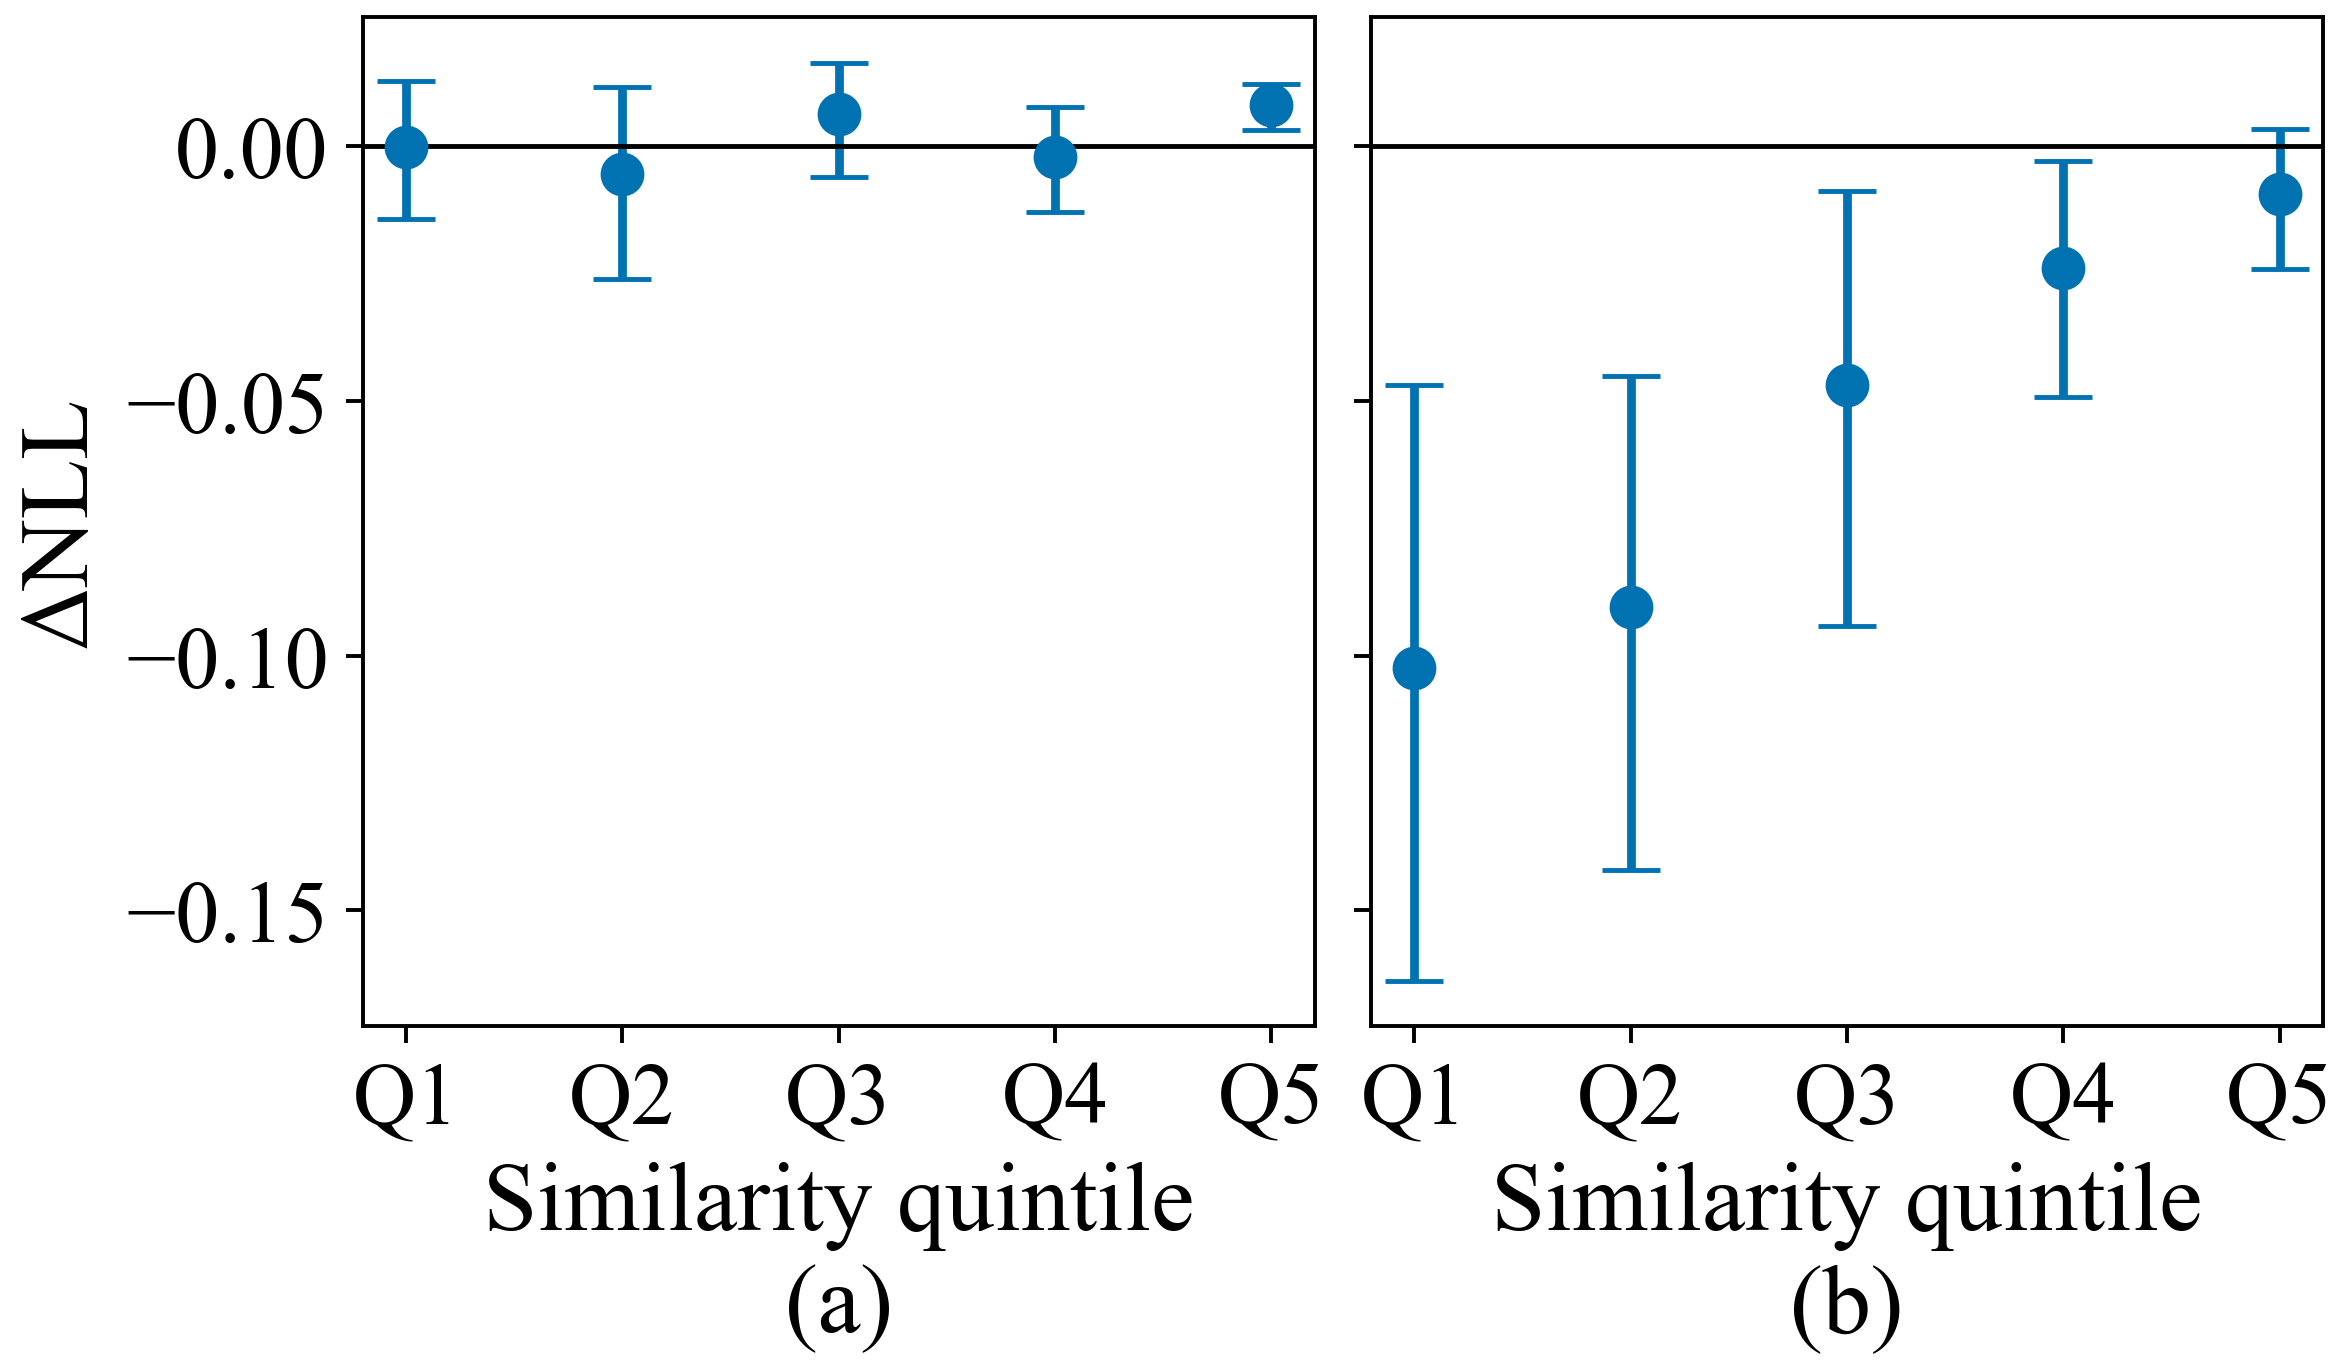

**Figure 6.4. ΔNLL (base − class-wise correction, V0 − V1) for base B2 by quintile of the similarity between a query and its nearest index publication: (a) temporal cohort; (b) external cohort. Points are quintile means; bars are 95 % bootstrap intervals. Positive values favour the correction. Similarity ranges, temporal: Q1: 0.614–0.750; Q2: 0.750–0.795; Q3: 0.795–0.827; Q4: 0.827–0.860; Q5: 0.860–0.957. External: Q1: 0.593–0.762; Q2: 0.762–0.799; Q3: 0.800–0.833; Q4: 0.833–0.859; Q5: 0.859–0.950.**

**Table 6.15. ΔNLL (V0 − V1, base B2) in subgroups defined without the query label: nearest-neighbour similarity against the fixed development threshold 0.757, and agreement among the five neighbours (largest neighbour-class weight). Intervals are 95 % bootstrap intervals; positive values favour the correction.**

,Subgroup,Publications,Share (%),NLL base,NLL corrected,ΔNLL [95 % CI]
Cohort,,,,,,
Temporal 2025,Nearest-neighbour similarity below 0.757,434,22.7,0.8662,0.8653,"+0.0008 [−0.0124, +0.0129]"
Temporal 2025,Nearest-neighbour similarity of 0.757 or more,1480,77.3,0.5991,0.5976,"+0.0015 [−0.0053, +0.0075]"
Temporal 2025,Largest neighbour-class weight below 0.60,309,16.1,1.1159,1.1077,"+0.0081 [−0.0075, +0.0224]"
Temporal 2025,Largest neighbour-class weight from 0.60 to below 1,793,41.4,0.7940,0.7928,"+0.0012 [−0.0095, +0.0109]"
Temporal 2025,All five neighbours in one class,812,42.4,0.3549,0.3560,"−0.0011 [−0.0086, +0.0050]"
External arXiv 2024,Nearest-neighbour similarity below 0.757,212,18.0,1.9107,2.0127,"−0.1020 [−0.1672, −0.0439]"
External arXiv 2024,Nearest-neighbour similarity of 0.757 or more,969,82.0,1.6135,1.6577,"−0.0442 [−0.0630, −0.0271]"
External arXiv 2024,Largest neighbour-class weight below 0.60,254,21.5,1.8641,1.9675,"−0.1034 [−0.1644, −0.0499]"
External arXiv 2024,Largest neighbour-class weight from 0.60 to below 1,476,40.3,1.6735,1.7229,"−0.0494 [−0.0801, −0.0227]"


In [26]:
THRESHOLD = float(S2["similarity_threshold"])
AGREEMENT_LOW = float(S2["agreement_bins"][0])
quintile_rows, group_rows = [], []
for cohort in COHORTS:
    c = STRESS["B2"]["cohorts"][cohort]
    gain = nll_of(c["post"]["V0"], c["target"]) - nll_of(c["post"]["V1"], c["target"])
    nll0, nll1 = nll_of(c["post"]["V0"], c["target"]), nll_of(c["post"]["V1"], c["target"])
    nearest, agreement = c["nearest"], c["near"].max(axis=1)
    quintile = pd.qcut(nearest, 5, labels=False)
    for q in range(5):
        m = quintile == q
        boot = bootstrap_mean(gain[m], N_BOOT, SEED)
        quintile_rows.append({"cohort": cohort, "quintile": q + 1, "publications": int(m.sum()),
                              "similarity_min": float(nearest[m].min()),
                              "similarity_max": float(nearest[m].max()),
                              "delta_nll": float(gain[m].mean()),
                              "delta_ci_low": float(np.quantile(boot, 0.025)),
                              "delta_ci_high": float(np.quantile(boot, 0.975))})
    groups = [("Nearest-neighbour similarity below 0.757", nearest < THRESHOLD),
              ("Nearest-neighbour similarity of 0.757 or more", nearest >= THRESHOLD),
              ("Largest neighbour-class weight below 0.60", agreement < AGREEMENT_LOW),
              ("Largest neighbour-class weight from 0.60 to below 1",
               (agreement >= AGREEMENT_LOW) & (agreement < 1.0 - 1e-9)),
              ("All five neighbours in one class", agreement >= 1.0 - 1e-9)]
    for label, m in groups:
        boot = bootstrap_mean(gain[m], N_BOOT, SEED)
        group_rows.append({"cohort": cohort, "group": label, "publications": int(m.sum()),
                           "share_percent": 100.0 * float(m.mean()), "nll_base": float(nll0[m].mean()),
                           "nll_corrected": float(nll1[m].mean()), "delta_nll": float(gain[m].mean()),
                           "delta_ci_low": float(np.quantile(boot, 0.025)),
                           "delta_ci_high": float(np.quantile(boot, 0.975))})
stress_quintiles, stress_groups = pd.DataFrame(quintile_rows), pd.DataFrame(group_rows)
stress_quintiles.to_csv(TABLES / "figure6_4_stress_similarity_quintiles.csv", index=False)

ranges = {cohort: "; ".join(f"Q{int(r.quintile)}: {fmt_num(r.similarity_min, 3)}–{fmt_num(r.similarity_max, 3)}"
                            for r in stress_quintiles[stress_quintiles["cohort"] == cohort].itertuples())
          for cohort in COHORTS}
CAPTION_F6_4 = ("Figure 6.4. ΔNLL (base − class-wise correction, V0 − V1) for base B2 by quintile of the "
                "similarity between a query and its nearest index publication: (a) temporal cohort; "
                "(b) external cohort. Points are quintile means; bars are 95 % bootstrap intervals. "
                "Positive values favour the correction. Similarity ranges, temporal: "
                f"{ranges['Temporal 2025']}. External: {ranges['External arXiv 2024']}.")
fig, axes = plt.subplots(1, 2, figsize=(6.7, 3.9), sharey=True)
for ax, cohort in zip(axes, COHORTS):
    part = stress_quintiles[stress_quintiles["cohort"] == cohort]
    ax.errorbar(part["quintile"], part["delta_nll"],
                yerr=[part["delta_nll"] - part["delta_ci_low"], part["delta_ci_high"] - part["delta_nll"]],
                fmt="o", markersize=8, capsize=6, linewidth=1.8, color=MODEL_COLOUR["V1"])
    ax.axhline(0.0, color="black", linewidth=1.0)
    ax.set_xticks(np.arange(1, 6), [f"Q{i}" for i in range(1, 6)])
    ax.set_xlabel("Similarity quintile")
axes[0].set_ylabel("ΔNLL")
label_panels(axes)
show_figure(fig, "figure6_4_stress_similarity_quintiles", CAPTION_F6_4, "9")

CAPTION_6_15 = ("Table 6.15. ΔNLL (V0 − V1, base B2) in subgroups defined without the query label: "
                "nearest-neighbour similarity against the fixed development threshold 0.757, and "
                "agreement among the five neighbours (largest neighbour-class weight). Intervals are "
                "95 % bootstrap intervals; positive values favour the correction.")
save_table(stress_groups, "table6_15_stress_subgroups", CAPTION_6_15, "9")
view = pd.DataFrame({
    "Cohort": stress_groups["cohort"],
    "Subgroup": stress_groups["group"],
    "Publications": stress_groups["publications"].map(lambda v: f"{v:d}"),
    "Share (%)": stress_groups["share_percent"].map(lambda v: fmt_num(v, 1)),
    "NLL base": stress_groups["nll_base"].map(fmt_num),
    "NLL corrected": stress_groups["nll_corrected"].map(fmt_num),
    "ΔNLL [95 % CI]": [f"{fmt_signed(d)} {fmt_ci(a, b)}" for d, a, b in zip(
        stress_groups["delta_nll"], stress_groups["delta_ci_low"], stress_groups["delta_ci_high"])],
}).set_index("Cohort")
show_table(view, CAPTION_6_15)

**Interpretation.**

- **Temporal cohort.** Only the highest similarity quintile (similarity of 0.860 or more) shows a gain, +0.0081 [+0.0032, +0.0123]. In the other quintiles and in the threshold and agreement subgroups every interval includes zero.
- **External cohort.** The harm decreases steadily as similarity increases, from −0.1025 [−0.1638, −0.0469] in the lowest quintile to −0.0092 [−0.0240, +0.0034] in the highest. It is about three times as large when the neighbours disagree (−0.1034) as when all five neighbours share one class (−0.0325).
- **Condition for use.** On both cohorts the correction is harmless or slightly beneficial only for queries whose nearest index publication is very similar (about 0.86 or more), which is the usual situation inside the development panel. The fixed threshold of 0.757 is too low to protect against the harm: above it the external $\Delta$NLL is still −0.0442. On the external cohort, low base confidence is not a sign that the neighbours are reliable.

These subgroup results are descriptive and come from cohorts that had been evaluated before.

In [27]:
rows = []
for cohort in COHORTS:
    c = STRESS["B2"]["cohorts"][cohort]
    target = c["target"]
    pred0, pred1 = c["post"]["V0"].argmax(axis=1), c["post"]["V1"].argmax(axis=1)
    gain = nll_of(c["post"]["V0"], target) - nll_of(c["post"]["V1"], target)
    for k in range(K):
        m = target == k
        boot = bootstrap_mean(gain[m], N_BOOT, SEED)
        rows.append({"cohort": cohort, "class_id": k, "class_name": CLASS_NAMES[k],
                     "publications": int(m.sum()), "recall_base": float((pred0[m] == k).mean()),
                     "recall_corrected": float((pred1[m] == k).mean()),
                     "delta_nll": float(gain[m].mean()),
                     "delta_ci_low": float(np.quantile(boot, 0.025)),
                     "delta_ci_high": float(np.quantile(boot, 0.975))})
per_class = pd.DataFrame(rows)
CAPTION_6_16 = ("Table 6.16. Per-class recall of the base (V0) and the class-wise correction (V1) for base "
                "B2, with ΔNLL (V0 − V1) and its 95 % bootstrap interval. Positive ΔNLL favours the "
                "correction. Labels of both cohorts are OpenAlex primary-topic fields.")
save_table(per_class, "table6_16_stress_per_class", CAPTION_6_16, "9")
for cohort in COHORTS:
    part = per_class[per_class["cohort"] == cohort]
    view = pd.DataFrame({
        "Class": part["class_name"],
        "Publications": part["publications"].map(lambda v: f"{v:d}"),
        "Recall base": part["recall_base"].map(lambda v: fmt_num(v, 3)),
        "Recall corrected": part["recall_corrected"].map(lambda v: fmt_num(v, 3)),
        "ΔNLL [95 % CI]": [f"{fmt_signed(d)} {fmt_ci(a, b)}" for d, a, b in zip(
            part["delta_nll"], part["delta_ci_low"], part["delta_ci_high"])],
    }).set_index("Class")
    show_table(view, f"{CAPTION_6_16} Part: {cohort}.")

**Table 6.16. Per-class recall of the base (V0) and the class-wise correction (V1) for base B2, with ΔNLL (V0 − V1) and its 95 % bootstrap interval. Positive ΔNLL favours the correction. Labels of both cohorts are OpenAlex primary-topic fields. Part: Temporal 2025.**

,Publications,Recall base,Recall corrected,ΔNLL [95 % CI]
Class,,,,
"Biochemistry, Genetics and Molecular Biology",240,0.738,0.742,"+0.0184 [+0.0118, +0.0254]"
Computer Science,242,0.723,0.723,"+0.0264 [+0.0198, +0.0338]"
"Economics, Econometrics and Finance",237,0.903,0.903,"−0.0205 [−0.0538, +0.0049]"
Engineering,243,0.654,0.642,"−0.0223 [−0.0425, −0.0037]"
Materials Science,239,0.745,0.762,"+0.0240 [+0.0161, +0.0319]"
Mathematics,235,0.843,0.838,"−0.0139 [−0.0315, +0.0016]"
Medicine,237,0.806,0.802,"+0.0112 [+0.0007, +0.0215]"
Physics and Astronomy,241,0.780,0.780,"−0.0127 [−0.0281, +0.0008]"


**Table 6.16. Per-class recall of the base (V0) and the class-wise correction (V1) for base B2, with ΔNLL (V0 − V1) and its 95 % bootstrap interval. Positive ΔNLL favours the correction. Labels of both cohorts are OpenAlex primary-topic fields. Part: External arXiv 2024.**

,Publications,Recall base,Recall corrected,ΔNLL [95 % CI]
Class,,,,
"Biochemistry, Genetics and Molecular Biology",149,0.336,0.329,"+0.0105 [−0.0034, +0.0248]"
Computer Science,149,0.799,0.792,"+0.0197 [+0.0136, +0.0272]"
"Economics, Econometrics and Finance",145,0.379,0.379,"−0.3613 [−0.4965, −0.2371]"
Engineering,148,0.311,0.311,"−0.0691 [−0.1044, −0.0362]"
Materials Science,149,0.423,0.430,"+0.0156 [+0.0042, +0.0275]"
Mathematics,144,0.861,0.861,"+0.0023 [−0.0058, +0.0093]"
Medicine,149,0.128,0.128,"−0.0519 [−0.0800, −0.0236]"
Physics and Astronomy,148,0.858,0.851,"−0.0086 [−0.0255, +0.0063]"


**Interpretation.** On the temporal cohort the correction lowers NLL for four classes (Biochemistry, Computer Science, Materials Science, Medicine) and raises it for Engineering; the class effects cancel in the cohort mean. On the external cohort most of the harm comes from Economics (−0.3613), followed by Engineering (−0.0691) and Medicine (−0.0519). The base already fails for these classes on this cohort (recall 0.379, 0.311 and 0.128), so their arXiv-hosted publications differ from the OpenAlex publications that carry the same field label in the index. Neighbours drawn from that different population are a plausible cause of the harm; this was not tested further.

In [28]:
inner_paths = pd.read_parquet(ROOT / CFG["inputs"]["inner_folds"])
dual_outer = pd.read_parquet(ROOT / S2["inputs"]["dual_path_outer"])
CORE_COLUMNS, INTERACTION_COLUMNS = [f"c_{i}" for i in range(K)], [f"i_{i}" for i in range(K)]
blend_ctx = {}
for r, f in CONTEXTS:
    c = ctx[(r, f)]
    inner = inner_paths[(inner_paths["repeat"] == r) & (inner_paths["outer_fold"] == f)].sort_values(
        "development_row_index")
    outer = dual_outer[(dual_outer["repeat"] == r) & (dual_outer["outer_fold"] == f)].sort_values(
        "development_row_index")
    assert np.array_equal(inner["development_row_index"].to_numpy(), c["ti"])
    assert np.array_equal(outer["development_row_index"].to_numpy(), c["hi"])
    blend_ctx[(r, f)] = {
        "base_inner": normalise(0.5 * (inner[CORE_COLUMNS].to_numpy() + inner[INTERACTION_COLUMNS].to_numpy())),
        "base_outer": outer[PC].to_numpy(np.float64)}


def run_variant_on(kind: str, bases: dict) -> np.ndarray:
    """E1 posterior of one variant when the base posteriors of every context are replaced."""
    post = np.zeros((2, N, K))
    for (r, f), c in ctx.items():
        nb = NB_ALL[(r, f)]
        near_inner = knn_posterior(nb["inner_val"], nb["inner_lab"], DEFAULT["top_k"], DEFAULT["temperature"])
        near_outer = knn_posterior(nb["outer_val"], nb["outer_lab"], DEFAULT["top_k"], DEFAULT["temperature"])
        params = fit_variant(kind, bases[(r, f)]["base_inner"], near_inner, y[c["ti"]], EPS)
        post[r, c["hi"]] = apply_variant(kind, params, bases[(r, f)]["base_outer"], near_outer, EPS)
    return post.mean(axis=0)


BLEND = {vid: run_variant_on(VARIANTS[vid]["kind"], blend_ctx) for vid in ("V0", "V1", "V4", "C1")}
blend_point = {vid: metrics(p, y) for vid, p in BLEND.items()}
blend_boot = bootstrap_metrics(BLEND, y, N_BOOT, SEED)
rows = []
for variant in ("V1", "V4"):
    for comparator in ("V0", "C1"):
        d = blend_point[comparator]["NLL"] - blend_point[variant]["NLL"]
        b = blend_boot[comparator]["NLL"] - blend_boot[variant]["NLL"]
        rows.append({"variant_id": variant, "comparator_id": comparator, "nll_variant": blend_point[variant]["NLL"],
                     "nll_comparator": blend_point[comparator]["NLL"], "delta_nll": d,
                     "delta_ci_low": float(np.quantile(b, 0.025)), "delta_ci_high": float(np.quantile(b, 0.975)),
                     "macro_f1_variant": blend_point[variant]["Macro-F1"],
                     "macro_f1_comparator": blend_point[comparator]["Macro-F1"]})
blend_check = pd.DataFrame(rows)
CAPTION_6_17 = ("Table 6.17. Development check with an equal-blend base without the evidence router "
                "(estimand E1, 6,708 publications). The base is built from saved artifacts: the mean of "
                "the saved core and interaction inner out-of-fold posteriors for fitting, and the saved "
                "Dual-Path posteriors for the outer-held rows. ΔNLL is comparator minus variant with a "
                "95 % paired bootstrap interval; positive values favour the corrected variant.")
save_table(blend_check, "table6_17_development_equal_blend", CAPTION_6_17, "9")
view = pd.DataFrame({
    "Variant": [variant_label(v) for v in blend_check["variant_id"]],
    "Against": [variant_label(v).replace("PRISM-Evidence", "equal-blend base") for v in blend_check["comparator_id"]],
    "NLL variant": blend_check["nll_variant"].map(fmt_num),
    "NLL comparator": blend_check["nll_comparator"].map(fmt_num),
    "ΔNLL [95 % CI]": [f"{fmt_signed(d)} {fmt_ci(a, b)}" for d, a, b in zip(
        blend_check["delta_nll"], blend_check["delta_ci_low"], blend_check["delta_ci_high"])],
    "Macro-F1 variant": blend_check["macro_f1_variant"].map(fmt_num),
    "Macro-F1 comparator": blend_check["macro_f1_comparator"].map(fmt_num),
}).set_index("Variant")
show_table(view, CAPTION_6_17)

**Table 6.17. Development check with an equal-blend base without the evidence router (estimand E1, 6,708 publications). The base is built from saved artifacts: the mean of the saved core and interaction inner out-of-fold posteriors for fitting, and the saved Dual-Path posteriors for the outer-held rows. ΔNLL is comparator minus variant with a 95 % paired bootstrap interval; positive values favour the corrected variant.**

,Against,NLL variant,NLL comparator,ΔNLL [95 % CI],Macro-F1 variant,Macro-F1 comparator
Variant,,,,,,
V1 MASSK (Full),V0 equal-blend base,0.5445,0.5550,"+0.0105 [+0.0074, +0.0135]",0.8056,0.8045
V1 MASSK (Full),C1 Temperature scaling,0.5445,0.5522,"+0.0077 [+0.0048, +0.0106]",0.8056,0.8042
"V4 Shared γ, no multiplier",V0 equal-blend base,0.5433,0.5550,"+0.0117 [+0.0090, +0.0143]",0.8048,0.8045
"V4 Shared γ, no multiplier",C1 Temperature scaling,0.5433,0.5522,"+0.0089 [+0.0066, +0.0112]",0.8048,0.8042


**Interpretation.** With the equal-blend base, the development result of Section 4 is unchanged: V1 lowers NLL by 0.0105 [0.0074, 0.0135] against the base and by 0.0077 [0.0048, 0.0106] against temperature scaling; V4 by 0.0117 and 0.0089. The development conclusion does not depend on the evidence router. The system evaluated on the two cohorts therefore has the same form as a system for which the development gain holds, although the development posteriors come from the earlier pipeline and not from the path models fitted in this section.

## 10. Raw-text perturbations of the temporal cohort

**Question.** How do the base and the corrected posteriors change when the input text of a query is shortened or damaged?

**Method.** The titles and abstracts of the 1,914 temporal publications are perturbed and encoded again with both frozen encoders; the fitted models (base B2 and its variants) and the retrieval index stay unchanged. Conditions: clean text; title only; abstract cut to its first 50 % or 25 % of words; random deletion of 10 % or 30 % of the words of title and abstract (at least one word is kept per field). Inputs follow notebook 02: the instruction prefix, title, a space and the abstract for Qwen3 (last-token pooling); title, the separator token and the abstract for SPECTER2 with its classification adapter (first-token pooling); at most 512 tokens. The adapter is a bottleneck adapter after the feed-forward sublayer of every layer: with the sublayer output $f$, the attention output $a$ and the layer normalisation $\mathrm{LN}$ of that sublayer, the layer returns $\mathrm{LN}\big(U\,\mathrm{ReLU}(D\,\mathrm{LN}(f + a)) + f + a\big)$, where $D$ and $U$ are the stored down- and up-projections. The implementation is accepted if the mean cosine between fresh and stored embeddings of the clean texts is at least 0.999 for both encoders. The external cohort is not perturbed.

In [29]:
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
ENC = S2["encoders"]
PAD_MULTIPLE = 64  # batches are padded to a few fixed lengths; the Apple GPU backend caches one graph per shape
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()


def synchronise() -> None:
    """Wait for queued GPU work so that timings are complete."""
    if DEVICE.type == "mps":
        torch.mps.synchronize()


class QwenEncoder:
    """Qwen3-Embedding with the instruction prefix and last-token pooling of notebook 02."""

    name = "qwen3"

    def __init__(self):
        cfg = ENC["qwen3"]
        self.tokenizer = AutoTokenizer.from_pretrained(cfg["model"], revision=cfg["revision"],
                                                       local_files_only=True, padding_side="left")
        self.model = AutoModel.from_pretrained(cfg["model"], revision=cfg["revision"],
                                               local_files_only=True, dtype=torch.float32).to(DEVICE).eval()
        self.prefix, self.batch = cfg["prefix"], int(cfg["batch_size"])
        self.parameters = int(sum(p.numel() for p in self.model.parameters()))

    def texts(self, titles: list[str], abstracts: list[str]) -> list[str]:
        return [self.prefix + f"{t} {a}".strip() for t, a in zip(titles, abstracts)]

    def embed(self, batch_texts: list[str]) -> torch.Tensor:
        enc = self.tokenizer(batch_texts, padding=True, truncation=True, max_length=int(ENC["max_length"]),
                             pad_to_multiple_of=PAD_MULTIPLE, return_tensors="pt").to(DEVICE)
        return self.model(**enc).last_hidden_state[:, -1]


class SpecterEncoder:
    """SPECTER2 base with the classification adapter applied after each feed-forward sublayer."""

    name = "specter2"

    def __init__(self):
        cfg = ENC["specter2"]
        self.tokenizer = AutoTokenizer.from_pretrained(cfg["model"], revision=cfg["revision"],
                                                       local_files_only=True)
        self.model = AutoModel.from_pretrained(cfg["model"], revision=cfg["revision"], local_files_only=True,
                                               add_pooling_layer=False).to(DEVICE).eval()
        folder = Path(snapshot_download(cfg["adapter"], revision=cfg["adapter_revision"],
                                        local_files_only=True))
        config = json.loads((folder / "adapter_config.json").read_text())["config"]
        expected = {"mh_adapter": False, "output_adapter": True, "non_linearity": "relu",
                    "original_ln_before": True, "original_ln_after": True, "residual_before_ln": True,
                    "adapter_residual_before_ln": False, "ln_before": False, "ln_after": False,
                    "is_parallel": False, "scaling": 1.0, "inv_adapter": None, "use_gating": False}
        assert all(config[key] == value for key, value in expected.items())
        state = torch.load(folder / "pytorch_adapter.bin", map_location="cpu", weights_only=True)
        assert len(state) == 4 * len(self.model.encoder.layer)
        for i, layer in enumerate(self.model.encoder.layer):
            def pick(suffix: str, i: int = i) -> torch.Tensor:
                matches = [v for k, v in state.items()
                           if f".layer.{i}.output.adapters." in k and k.endswith(suffix)]
                assert len(matches) == 1
                return matches[0].to(DEVICE)

            layer.output.register_forward_hook(self._adapter_hook(
                pick("adapter_down.0.weight"), pick("adapter_down.0.bias"),
                pick("adapter_up.weight"), pick("adapter_up.bias")))
        self.batch = int(cfg["batch_size"])
        self.parameters = int(sum(p.numel() for p in self.model.parameters())
                              + sum(v.numel() for v in state.values()))

    @staticmethod
    def _adapter_hook(down_w, down_b, up_w, up_b):
        def hook(module, args, output):
            sublayer, attention = module.dense(args[0]), args[1]
            hidden = module.LayerNorm(sublayer + attention)
            up = F.linear(torch.relu(F.linear(hidden, down_w, down_b)), up_w, up_b)
            return module.LayerNorm(up + sublayer + attention)
        return hook

    def texts(self, titles: list[str], abstracts: list[str]) -> list[str]:
        return [t + self.tokenizer.sep_token + a for t, a in zip(titles, abstracts)]

    def embed(self, batch_texts: list[str]) -> torch.Tensor:
        enc = self.tokenizer(batch_texts, padding=True, truncation=True, max_length=int(ENC["max_length"]),
                             pad_to_multiple_of=PAD_MULTIPLE, return_tensors="pt",
                             return_token_type_ids=False).to(DEVICE)
        return self.model(**enc).last_hidden_state[:, 0]


def encode_texts(encoder, texts: list[str], on_batch=None) -> tuple[np.ndarray, float]:
    """L2-normalised embeddings in the input order and the wall-clock encoding time in seconds."""
    order = np.argsort([-len(t) for t in texts], kind="stable")
    out = None
    synchronise()
    started = time.perf_counter()
    with torch.inference_mode():
        for start in range(0, len(order), encoder.batch):
            rows = order[start:start + encoder.batch]
            emb = F.normalize(encoder.embed([texts[i] for i in rows]).float(), dim=1).cpu().numpy()
            if out is None:
                out = np.zeros((len(texts), emb.shape[1]), np.float32)
            out[rows] = emb
            if DEVICE.type == "mps":
                torch.mps.empty_cache()
            if on_batch is not None:
                on_batch(len(rows))
    synchronise()
    return out, time.perf_counter() - started


def truncate_words(text: str, fraction: float) -> str:
    """First share of the whitespace-separated words, at least one word."""
    words = text.split()
    return " ".join(words[:max(1, int(np.ceil(len(words) * fraction)))])


def delete_words(text: str, rate: float, rng: np.random.Generator) -> str:
    """Random deletion of words at the given rate; at least one word is kept."""
    words = text.split()
    if len(words) <= 1:
        return text
    keep = rng.random(len(words)) >= rate
    if not keep.any():
        keep[rng.integers(len(words))] = True
    return " ".join(w for w, k in zip(words, keep) if k)


temporal_rows = COHORTS["Temporal 2025"]
titles = full.loc[temporal_rows, "title_clean"].tolist()
abstracts = full.loc[temporal_rows, "abstract_clean"].tolist()
perturb_rng = np.random.default_rng(SEED)
CONDITIONS = {"Clean, re-encoded": (titles, abstracts),
              "Title only": (titles, [""] * len(titles))}
for fraction in S2["perturbations"]["truncation_fractions"]:
    CONDITIONS[f"Abstract cut to first {int(round(100 * fraction))} % of words"] = (
        titles, [truncate_words(a, fraction) for a in abstracts])
for rate in S2["perturbations"]["deletion_rates"]:
    CONDITIONS[f"Random deletion of {int(round(100 * rate))} % of words"] = (
        [delete_words(t, rate, perturb_rng) for t in titles],
        [delete_words(a, rate, perturb_rng) for a in abstracts])
CONDITION_DIGEST = hashlib.sha256("\x1e".join(
    name + "\x1f" + "\x1f".join(t + "\x1d" + a for t, a in zip(*pair))
    for name, pair in CONDITIONS.items()).encode("utf-8")).hexdigest()

In [30]:
CACHE_PATH = ROOT / S2["embedding_cache"]
progress = display(Markdown("Encoding the perturbed temporal cohort"), display_id=True)
cached = np.load(CACHE_PATH, allow_pickle=False) if CACHE_PATH.exists() else None
if cached is not None and str(cached["digest"]) == CONDITION_DIGEST:
    FRESH = {name: {"qwen3": cached[f"q{i}"], "specter2": cached[f"s{i}"]}
             for i, name in enumerate(CONDITIONS)}
    ENCODING = json.loads(str(cached["encoding"]))
else:
    FRESH = {name: {} for name in CONDITIONS}
    ENCODING = {"device": str(DEVICE), "measured_utc": pd.Timestamp.now(tz="UTC").isoformat(),
                "seconds": {}, "parameters": {}}
    total, done = 2 * len(CONDITIONS) * len(titles), 0
    for encoder_class in (SpecterEncoder, QwenEncoder):
        encoder = encoder_class()
        ENCODING["parameters"][encoder.name] = encoder.parameters
        ENCODING["seconds"][encoder.name] = {}
        for name, (condition_titles, condition_abstracts) in CONDITIONS.items():
            def on_batch(count: int, name: str = name, label: str = encoder.name) -> None:
                global done
                done += count
                progress.update(Markdown(f"Encoding ({label}, {name}): {100.0 * done / total:.0f} %"))

            values, seconds = encode_texts(encoder, encoder.texts(condition_titles, condition_abstracts), on_batch)
            FRESH[name][encoder.name] = values
            ENCODING["seconds"][encoder.name][name] = seconds
        del encoder
        if DEVICE.type == "mps":
            torch.mps.empty_cache()
    arrays = {f"q{i}": FRESH[name]["qwen3"] for i, name in enumerate(CONDITIONS)}
    arrays.update({f"s{i}": FRESH[name]["specter2"] for i, name in enumerate(CONDITIONS)})
    np.savez(CACHE_PATH, digest=np.array(CONDITION_DIGEST), encoding=np.array(json.dumps(ENCODING)), **arrays)

temporal_t = torch.from_numpy(temporal_rows)
stored = {"qwen3": FULL_Q[temporal_t].numpy(), "specter2": FULL_S[temporal_t].numpy()}
clean = FRESH["Clean, re-encoded"]
rows = []
for key, label in (("qwen3", "Qwen3-Embedding-0.6B"), ("specter2", "SPECTER2 base + classification adapter")):
    cosine = (clean[key] * stored[key]).sum(axis=1)
    rows.append({"encoder": label, "publications": len(cosine), "mean_cosine": float(cosine.mean()),
                 "min_cosine": float(cosine.min()),
                 "share_at_least_0999_percent": 100.0 * float((cosine >= 0.999).mean())})
encoder_check = pd.DataFrame(rows)
base_fresh = predict_base(BASES["B2"]["model"], torch.from_numpy(clean["qwen3"]), torch.from_numpy(clean["specter2"]))
base_stored = STRESS["B2"]["cohorts"]["Temporal 2025"]["post"]["V0"]
ENCODER_CHECK_PASSED = bool((encoder_check["mean_cosine"]
                             >= float(S2["perturbations"]["encoder_check_min_mean_cosine"])).all())
CAPTION_6_18 = ("Table 6.18. Agreement between embeddings of the clean temporal texts encoded in this notebook "
                f"(device: {ENCODING['device']}) and the stored embeddings of notebook 02. With the fresh "
                "embeddings, the base B2 predicts the same class as with the stored ones for "
                f"{fmt_num(100.0 * float((base_fresh.argmax(axis=1) == base_stored.argmax(axis=1)).mean()), 2)} % "
                "of the publications; the largest posterior difference is "
                f"{fmt_sci(float(np.abs(base_fresh - base_stored).max()))}. The predeclared acceptance "
                "criterion (mean cosine of at least 0.999 for both encoders) is "
                f"{'met' if ENCODER_CHECK_PASSED else 'not met'}.")
save_table(encoder_check, "table6_18_encoder_check", CAPTION_6_18, "10")
view = pd.DataFrame({
    "Encoder": encoder_check["encoder"],
    "Publications": encoder_check["publications"].map(lambda v: f"{v:d}"),
    "Mean cosine": encoder_check["mean_cosine"].map(lambda v: fmt_num(v, 5)),
    "Minimum cosine": encoder_check["min_cosine"].map(lambda v: fmt_num(v, 5)),
    "Cosine ≥ 0.999 (%)": encoder_check["share_at_least_0999_percent"].map(lambda v: fmt_num(v, 2)),
}).set_index("Encoder")
progress.update(Markdown(f"**{CAPTION_6_18}**"))
display(view)

**Table 6.18. Agreement between embeddings of the clean temporal texts encoded in this notebook (device: mps) and the stored embeddings of notebook 02. With the fresh embeddings, the base B2 predicts the same class as with the stored ones for 99.79 % of the publications; the largest posterior difference is 1.31 × 10⁻². The predeclared acceptance criterion (mean cosine of at least 0.999 for both encoders) is met.**

,Publications,Mean cosine,Minimum cosine,Cosine ≥ 0.999 (%)
Encoder,,,,
Qwen3-Embedding-0.6B,1914,0.99991,0.99978,100.00
SPECTER2 base + classification adapter,1914,0.99999,0.99998,100.00


**Interpretation.** Both encoders reproduce the stored embeddings: the mean cosine is 0.99991 for Qwen3 and 0.99999 for SPECTER2 with the adapter, and every publication exceeds 0.999. The acceptance criterion is met. The remaining differences still change 0.21 % of the classes predicted by the base, which sets the noise level for the comparisons below.

In [31]:
PERTURB_VARIANTS = ["V0", "V1", "V4", "C1"]
temporal_target = full_y[temporal_rows]
b2_params, b2_fit = STRESS["B2"]["params"], BASES["B2"]["fit"]


def evaluate_embeddings(qwen: np.ndarray, specter: np.ndarray) -> tuple[dict, float]:
    """Posteriors of the perturbation variants and the mean nearest-neighbour similarity."""
    q_t, s_t = torch.from_numpy(qwen), torch.from_numpy(specter)
    base_post = predict_base(BASES["B2"]["model"], q_t, s_t)
    val, lab = neighbours_for(q_t, s_t, b2_fit)
    near = knn_posterior(val, lab, DEFAULT["top_k"], DEFAULT["temperature"])
    post = {vid: apply_variant(VARIANTS[vid]["kind"], b2_params[vid], base_post, near, EPS)
            for vid in PERTURB_VARIANTS}
    return post, float(val[:, 0].mean())


rows = []
inputs = {"Stored embeddings": stored, **FRESH}
for name, vectors in inputs.items():
    post, similarity = evaluate_embeddings(vectors["qwen3"], vectors["specter2"])
    m = {vid: metrics(post[vid], temporal_target) for vid in PERTURB_VARIANTS}
    row = {"condition": name, "mean_nearest_similarity": similarity,
           "macro_f1_v0": m["V0"]["Macro-F1"], "macro_f1_v1": m["V1"]["Macro-F1"],
           "nll_v0": m["V0"]["NLL"], "nll_c1": m["C1"]["NLL"], "nll_v1": m["V1"]["NLL"],
           "nll_v4": m["V4"]["NLL"], "ece_v0": m["V0"]["ECE"], "ece_v1": m["V1"]["ECE"]}
    for vid in ("V1", "V4"):
        gain = nll_of(post["V0"], temporal_target) - nll_of(post[vid], temporal_target)
        boot = bootstrap_mean(gain, N_BOOT, SEED)
        row.update({f"delta_nll_{vid.lower()}": float(gain.mean()),
                    f"delta_{vid.lower()}_ci_low": float(np.quantile(boot, 0.025)),
                    f"delta_{vid.lower()}_ci_high": float(np.quantile(boot, 0.975))})
    rows.append(row)
perturbation = pd.DataFrame(rows)
CAPTION_6_19 = ("Table 6.19. Raw-text perturbations of the temporal cohort (n = 1,914) for base B2. Queries "
                "are perturbed and re-encoded; models and index are unchanged. V0: base; C1: temperature "
                "scaling; V1: class-wise correction; V4: one shared coefficient without the multiplier. "
                "ΔNLL is V0 minus the corrected variant with a 95 % bootstrap interval; positive values "
                "favour the correction.")
save_table(perturbation, "table6_19_text_perturbations", CAPTION_6_19, "10")
view = pd.DataFrame({
    "Condition": perturbation["condition"],
    "Nearest-neighbour similarity": perturbation["mean_nearest_similarity"].map(lambda v: fmt_num(v, 3)),
    "Macro-F1 V0": perturbation["macro_f1_v0"].map(fmt_num),
    "Macro-F1 V1": perturbation["macro_f1_v1"].map(fmt_num),
    "NLL V0": perturbation["nll_v0"].map(fmt_num),
    "NLL C1": perturbation["nll_c1"].map(fmt_num),
    "NLL V1": perturbation["nll_v1"].map(fmt_num),
    "NLL V4": perturbation["nll_v4"].map(fmt_num),
}).set_index("Condition")
show_table(view, CAPTION_6_19 + " Part 1: performance.")
view = pd.DataFrame({
    "Condition": perturbation["condition"],
    "ECE V0": perturbation["ece_v0"].map(fmt_num),
    "ECE V1": perturbation["ece_v1"].map(fmt_num),
    "ΔNLL V0 − V1 [95 % CI]": [f"{fmt_signed(d)} {fmt_ci(a, b)}" for d, a, b in zip(
        perturbation["delta_nll_v1"], perturbation["delta_v1_ci_low"], perturbation["delta_v1_ci_high"])],
    "ΔNLL V0 − V4 [95 % CI]": [f"{fmt_signed(d)} {fmt_ci(a, b)}" for d, a, b in zip(
        perturbation["delta_nll_v4"], perturbation["delta_v4_ci_low"], perturbation["delta_v4_ci_high"])],
}).set_index("Condition")
show_table(view, CAPTION_6_19 + " Part 2: calibration and differences.")

**Table 6.19. Raw-text perturbations of the temporal cohort (n = 1,914) for base B2. Queries are perturbed and re-encoded; models and index are unchanged. V0: base; C1: temperature scaling; V1: class-wise correction; V4: one shared coefficient without the multiplier. ΔNLL is V0 minus the corrected variant with a 95 % bootstrap interval; positive values favour the correction. Part 1: performance.**

,Nearest-neighbour similarity,Macro-F1 V0,Macro-F1 V1,NLL V0,NLL C1,NLL V1,NLL V4
Condition,,,,,,,
Stored embeddings,0.805,0.7733,0.7731,0.6597,0.6606,0.6583,0.6587
"Clean, re-encoded",0.805,0.7754,0.7731,0.6597,0.6606,0.6581,0.6586
Title only,0.763,0.7585,0.7599,0.6840,0.6842,0.6729,0.6780
Abstract cut to first 50 % of words,0.803,0.7764,0.7774,0.6585,0.6594,0.6540,0.6556
Abstract cut to first 25 % of words,0.795,0.7719,0.7717,0.6630,0.6636,0.6590,0.6604
Random deletion of 10 % of words,0.806,0.7715,0.7725,0.6602,0.6611,0.6593,0.6597
Random deletion of 30 % of words,0.799,0.7689,0.7698,0.6709,0.6718,0.6663,0.6686


**Table 6.19. Raw-text perturbations of the temporal cohort (n = 1,914) for base B2. Queries are perturbed and re-encoded; models and index are unchanged. V0: base; C1: temperature scaling; V1: class-wise correction; V4: one shared coefficient without the multiplier. ΔNLL is V0 minus the corrected variant with a 95 % bootstrap interval; positive values favour the correction. Part 2: calibration and differences.**

,ECE V0,ECE V1,ΔNLL V0 − V1 [95 % CI],ΔNLL V0 − V4 [95 % CI]
Condition,,,,
Stored embeddings,0.0388,0.0459,"+0.0014 [−0.0046, +0.0068]","+0.0010 [−0.0026, +0.0045]"
"Clean, re-encoded",0.0397,0.0427,"+0.0016 [−0.0043, +0.0070]","+0.0010 [−0.0025, +0.0045]"
Title only,0.0296,0.0366,"+0.0111 [+0.0048, +0.0169]","+0.0060 [+0.0025, +0.0095]"
Abstract cut to first 50 % of words,0.0328,0.0359,"+0.0044 [−0.0013, +0.0096]","+0.0028 [−0.0006, +0.0062]"
Abstract cut to first 25 % of words,0.0313,0.0373,"+0.0040 [−0.0023, +0.0097]","+0.0026 [−0.0009, +0.0060]"
Random deletion of 10 % of words,0.0388,0.0391,"+0.0009 [−0.0052, +0.0064]","+0.0006 [−0.0030, +0.0040]"
Random deletion of 30 % of words,0.0312,0.0423,"+0.0046 [−0.0010, +0.0099]","+0.0023 [−0.0012, +0.0058]"


**Interpretation.**

- **The base is robust to the perturbations.** With the re-encoded clean texts it reaches a macro-F1 of 0.7754 and an NLL of 0.6597. The largest loss comes from removing the abstract: 0.7585 and 0.6840 with the title alone. Cutting the abstract to half leaves both measures unchanged (0.7764 and 0.6585). A quarter of the abstract, or the deletion of 30 % of the words, costs at most 0.0065 in macro-F1 and 0.0112 in NLL.
- **The correction does not become harmful under perturbation.** $\Delta$NLL of V1 is positive in every condition. Its interval excludes zero only with the title alone (+0.0111 [+0.0048, +0.0169]; V4 +0.0060 [+0.0025, +0.0095]), where the mean nearest-neighbour similarity falls from 0.805 to 0.763.
- **Noise level.** Re-encoding the clean texts changes the macro-F1 of the base from 0.7733 to 0.7754, so differences of about 0.002 between conditions are within encoding noise.

## 11. Computational cost of the evaluated system

**Question.** What does the evaluated system (base B2 with the correction) cost to fit and to apply?

**Method.** Parameter counts separate the frozen encoders, the trainable base and the correction. Fitting times are wall-clock times in this notebook. Inference is measured on the temporal cohort (1,914 publications): each encoder is timed once on the clean texts, including tokenisation; the base, the exact top-5 retrieval against the B2 index and the correction are timed as the median of five repetitions on stored embeddings. The encoders run on the Apple GPU of an M1 Pro machine with 16 GB of memory; the other stages run on CPU. The values describe this machine and are not comparable with the earlier GPU measurements.

In [32]:
REPEATS = int(S2["timing_repetitions"])


def median_seconds(function) -> float:
    """Median wall-clock time of repeated calls."""
    times = []
    for _ in range(REPEATS):
        started = time.perf_counter()
        function()
        times.append(time.perf_counter() - started)
    return float(np.median(times))


q_t, s_t = FULL_Q[temporal_t], FULL_S[temporal_t]
b2_stop = BASES["B2"]["stop"]
timing_base = median_seconds(lambda: predict_base(BASES["B2"]["model"], q_t, s_t))
timing_retrieval = median_seconds(lambda: knn_posterior(
    *neighbours_for(q_t, s_t, b2_fit, kmax=DEFAULT["top_k"]), DEFAULT["top_k"], DEFAULT["temperature"]))
_near = knn_posterior(*neighbours_for(q_t, s_t, b2_fit, kmax=DEFAULT["top_k"]), DEFAULT["top_k"],
                      DEFAULT["temperature"])
timing_correction = median_seconds(lambda: apply_variant("full", b2_params["V1"], base_stored, _near, EPS))
fit_full = median_seconds(lambda: fit_variant("full", STRESS["B2"]["stop_base"], STRESS["B2"]["stop_near"],
                                              y[b2_stop], EPS))
fit_shared = median_seconds(lambda: fit_variant("shared_no_mult", STRESS["B2"]["stop_base"],
                                                STRESS["B2"]["stop_near"], y[b2_stop], EPS))

components = pd.DataFrame([
    {"component": "Qwen3-Embedding-0.6B encoder", "status": "frozen",
     "parameters": int(ENCODING["parameters"]["qwen3"]), "fit_seconds": 0.0},
    {"component": "SPECTER2 base with classification adapter", "status": "frozen",
     "parameters": int(ENCODING["parameters"]["specter2"]), "fit_seconds": 0.0},
    {"component": "Base B2: nine path models", "status": "trained",
     "parameters": trainable_parameters(BASES["B2"]["model"]), "fit_seconds": BASES["B2"]["model"]["seconds"]},
    {"component": "Correction V1: class-wise coefficients", "status": "trained", "parameters": 8,
     "fit_seconds": fit_full},
    {"component": "Correction V4: one shared coefficient", "status": "trained", "parameters": 1,
     "fit_seconds": fit_shared},
])
stage_seconds = {"Qwen3 encoding": ENCODING["seconds"]["qwen3"]["Clean, re-encoded"],
                 "SPECTER2 encoding": ENCODING["seconds"]["specter2"]["Clean, re-encoded"],
                 "Base posterior": timing_base, "Exact top-5 retrieval": timing_retrieval,
                 "Correction": timing_correction}
stages = pd.DataFrame([{"stage": name, "seconds": value} for name, value in stage_seconds.items()])
stages.loc[len(stages)] = {"stage": "Total", "seconds": float(stages["seconds"].sum())}
stages["ms_per_publication"] = 1000.0 * stages["seconds"] / len(temporal_rows)
stages["share_percent"] = 100.0 * stages["seconds"] / float(stages.loc[stages["stage"] == "Total", "seconds"].iloc[0])
CAPTION_6_20 = ("Table 6.20. Computational cost of the evaluated system on an Apple M1 Pro machine "
                f"(encoders on {ENCODING['device']}, other stages on CPU). Encoding times were measured on "
                f"{ENCODING['measured_utc'][:10]} when the embeddings were computed; frozen components have "
                "no fitting time.")
save_table(components, "table6_20a_cost_components", CAPTION_6_20, "11")
save_table(stages, "table6_20b_cost_inference", CAPTION_6_20, "11")
view = pd.DataFrame({
    "Component": components["component"],
    "Status": components["status"],
    "Parameters": components["parameters"].map(lambda v: f"{v:d}"),
    "Fitting time (s)": [fmt_num(v, 2) if s == "trained" else "n/a"
                         for v, s in zip(components["fit_seconds"], components["status"])],
}).set_index("Component")
show_table(view, CAPTION_6_20 + " Part 1: parameters and fitting (n/a: frozen, not fitted).")
view = pd.DataFrame({
    "Stage": stages["stage"],
    "Time for 1,914 publications (s)": stages["seconds"].map(lambda v: fmt_num(v, 3)),
    "Time per publication (ms)": stages["ms_per_publication"].map(lambda v: fmt_num(v, 3)),
    "Share of total (%)": stages["share_percent"].map(lambda v: fmt_num(v, 2)),
}).set_index("Stage")
show_table(view, CAPTION_6_20 + " Part 2: inference on the temporal cohort.")

**Table 6.20. Computational cost of the evaluated system on an Apple M1 Pro machine (encoders on mps, other stages on CPU). Encoding times were measured on 2026-11-10 when the embeddings were computed; frozen components have no fitting time. Part 1: parameters and fitting (n/a: frozen, not fitted).**

,Status,Parameters,Fitting time (s)
Component,,,
Qwen3-Embedding-0.6B encoder,frozen,595776512,n/a
SPECTER2 base with classification adapter,frozen,110222400,n/a
Base B2: nine path models,trained,2230827,12.14
Correction V1: class-wise coefficients,trained,8,0.12
Correction V4: one shared coefficient,trained,1,0.11


**Table 6.20. Computational cost of the evaluated system on an Apple M1 Pro machine (encoders on mps, other stages on CPU). Encoding times were measured on 2026-11-10 when the embeddings were computed; frozen components have no fitting time. Part 2: inference on the temporal cohort.**

,"Time for 1,914 publications (s)",Time per publication (ms),Share of total (%)
Stage,,,
Qwen3 encoding,520.408,271.896,88.17
SPECTER2 encoding,69.702,36.417,11.81
Base posterior,0.067,0.035,0.01
Exact top-5 retrieval,0.026,0.014,0.00
Correction,0.000,0.000,0.00
Total,590.204,308.361,100.00


**Interpretation.** The two frozen encoders account for 99.98 % of the inference time: 271.9 ms per publication for Qwen3 and 36.4 ms for SPECTER2 on this machine, against 0.04 ms for the base, 0.01 ms for the exact retrieval and less than 0.001 ms for the correction. The correction adds eight parameters (or one) to 2,230,827 trainable base parameters and is fitted in about 0.1 s, against about 12 s for the base. The cost of the system is the cost of its encoders. The correction is almost free, so its value depends only on whether it improves the probabilities.

## 12. Topic-level relevance of the retrieved neighbours

**Question.** Do the neighbours retrieved with the frozen similarity share the topic of the query at finer levels than the eight classes, and are they related to it by citations?

**Method.** The analysis uses the 5,532 OpenAlex publications of the development panel. The arXiv pilot publications carry no OpenAlex topic and are excluded from queries and index. OpenAlex assigns every work a primary topic, which belongs to one subfield and one field; the field is the thematic class of this study. Queries, index, similarities and cutoff follow Section 6. A retrieved publication is relevant if it has the same field (L1), the same subfield (L2) or the same primary topic (L3) as the query, or if it shares at least one referenced work with the query (bibliographic coupling, BC). For BC, queries and index are limited to publications with at least one recorded reference.

Precision@10 is compared with two chance references: ten publications drawn at random from the index, and ten drawn at random from the index publications of the query's class. The second reference shows whether the neighbours are closer to the query than class agreement alone implies. $\mathrm{nDCG@10} = \mathrm{DCG@10} / \mathrm{IDCG@10}$ with $\mathrm{DCG@10} = \sum_{r=1}^{10} g_r / \log_2(r+1)$, where the ideal ranking is formed from the index of each query. Queries without a relevant index publication are excluded for that criterion. The graded variant uses $g = 3$ for the same topic, 2 for the same subfield, 1 for the same field and 0 otherwise.

The analysis is descriptive. OpenAlex assigns topics automatically, and no expert judgment of relevance is used; bibliographic coupling is the only criterion that does not depend on the topic classifier.

In [33]:
S3 = CFG["step3"]
GAIN = S3["relevance"]["gains"]
CUM_DISCOUNT = np.cumsum(DISCOUNT)
VIEWS = [("dual", "Dual view (Qwen3 + SPECTER2)"), ("qwen3", "Qwen3 only"), ("specter2", "SPECTER2 only")]
CRITERIA = {"field": "L1: same field (class)", "subfield": "L2: same subfield",
            "topic": "L3: same primary topic", "coupling": "BC: shared reference"}


def development_topics() -> dict:
    """Primary topic, subfield, field and referenced works of the stored development records (notebook 01)."""
    out = {}
    for path in sorted((ROOT / S3["relevance"]["raw_records"]).glob("*__seed_*.json")):
        if path.name.startswith(("confirmatory_", "confirmation_")):
            continue
        for work in json.loads(path.read_text(encoding="utf-8")).get("results", []):
            topic = work.get("primary_topic") or {}
            out.setdefault(work["id"], {"topic": topic.get("id", ""),
                                        "subfield": (topic.get("subfield") or {}).get("id", ""),
                                        "field": (topic.get("field") or {}).get("display_name", ""),
                                        "references": work.get("referenced_works") or []})
    return out


oa_rows = np.flatnonzero(~is_pilot)
_stored = development_topics()
oa_meta = [_stored[paper_id] for paper_id in dev.loc[oa_rows, "paper_id"]]
del _stored
assert all(m["topic"] and m["subfield"] for m in oa_meta)
assert [m["field"] for m in oa_meta] == dev.loc[oa_rows, "thematic_class"].tolist()


def codes_on_rows(values: list[str]) -> np.ndarray:
    """Integer codes on the development rows; pilot rows receive −1."""
    out = np.full(N, -1, np.int64)
    out[oa_rows] = pd.factorize(pd.Series(values))[0]
    return out


LEVEL_CODE = {"field": np.where(is_pilot, -1, y),
              "subfield": codes_on_rows([m["subfield"] for m in oa_meta]),
              "topic": codes_on_rows([m["topic"] for m in oa_meta])}
reference_lists = [m["references"] for m in oa_meta]
reference_code = pd.factorize(pd.Series([w for refs in reference_lists for w in refs]))[0]
REFS = sparse.csr_matrix((np.ones(len(reference_code), np.float32),
                          (np.repeat(oa_rows, [len(refs) for refs in reference_lists]), reference_code)),
                         shape=(N, int(reference_code.max()) + 1))
has_refs = np.zeros(N, bool)
has_refs[oa_rows] = [len(refs) > 0 for refs in reference_lists]


def ranked_rows(query: np.ndarray, docs: np.ndarray, view: str) -> np.ndarray:
    """Development rows of the CUTOFF nearest index publications of each query row."""
    q, d = torch.from_numpy(query), torch.from_numpy(docs)
    if view == "dual":
        sim = 0.5 * (EQ[q] @ EQ[d].T + ES[q] @ ES[d].T)
    elif view == "qwen3":
        sim = EQ[q] @ EQ[d].T
    else:
        sim = ES[q] @ ES[d].T
    return docs[torch.topk(sim, k=CUTOFF, dim=1).indices.numpy()]


def binary_measures(rel: np.ndarray, n_relevant: np.ndarray, n_index: int,
                    n_relevant_same_class: np.ndarray, n_same_class: np.ndarray) -> dict:
    """Precision, nDCG and chance references over the queries with a relevant index publication."""
    valid = n_relevant > 0
    ideal = CUM_DISCOUNT[np.minimum(n_relevant[valid], CUTOFF) - 1]
    return {"queries_evaluated_percent": 100.0 * float(valid.mean()),
            "precision": float(rel[valid].mean()),
            "ndcg": float(((rel[valid] * DISCOUNT).sum(axis=1) / ideal).mean()),
            "chance_index": float((n_relevant[valid] / n_index).mean()),
            "chance_same_class": float((n_relevant_same_class[valid] / n_same_class[valid]).mean())}


binary_rows, graded_rows = [], []
position = np.arange(CUTOFF)[None, :]
for key in CONTEXTS:
    hi, ti = ctx[key]["hi"], ctx[key]["ti"]
    hi, ti = hi[~is_pilot[hi]], ti[~is_pilot[ti]]
    class_size = np.bincount(y[ti], minlength=K)[y[hi]]
    hq, tq = hi[has_refs[hi]], ti[has_refs[ti]]
    coupled = np.asarray((REFS[hq] @ REFS[tq].T).todense()) > 0
    same_class = y[tq][None, :] == y[hq][:, None]
    column_of = np.full(N, -1, np.int64)
    column_of[tq] = np.arange(len(tq))
    for view_name, view_label in VIEWS:
        near = ranked_rows(hi, ti, view_name)
        match, count = {}, {}
        for level, code in LEVEL_CODE.items():
            match[level] = (code[near] == code[hi][:, None]).astype(float)
            count[level] = np.bincount(code[ti], minlength=int(code.max()) + 1)[code[hi]]
            binary_rows.append({"context": str(key), "criterion": level, "similarity": view_label,
                                **binary_measures(match[level], count[level], len(ti),
                                                  count[level], class_size)})
        gain = (GAIN["field"] * match["field"] + (GAIN["subfield"] - GAIN["field"]) * match["subfield"]
                + (GAIN["topic"] - GAIN["subfield"]) * match["topic"])
        ideal = np.where(position < count["topic"][:, None], GAIN["topic"],
                         np.where(position < count["subfield"][:, None], GAIN["subfield"],
                                  np.where(position < count["field"][:, None], GAIN["field"], 0))).astype(float)
        graded_rows.append({"context": str(key), "similarity": view_label,
                            "ndcg": float(((gain * DISCOUNT).sum(axis=1) / (ideal * DISCOUNT).sum(axis=1)).mean())})
        near_refs = ranked_rows(hq, tq, view_name)
        rel = coupled[np.arange(len(hq))[:, None], column_of[near_refs]].astype(float)
        binary_rows.append({"context": str(key), "criterion": "coupling", "similarity": view_label,
                            **binary_measures(rel, coupled.sum(axis=1), len(tq),
                                              (coupled & same_class).sum(axis=1), same_class.sum(axis=1))})

binary_rows, graded_rows = pd.DataFrame(binary_rows), pd.DataFrame(graded_rows)
MEASURES = ["queries_evaluated_percent", "precision", "ndcg", "chance_index", "chance_same_class"]
rows = []
for criterion in CRITERIA:
    for _, view_label in VIEWS:
        part = binary_rows[(binary_rows["criterion"] == criterion) & (binary_rows["similarity"] == view_label)]
        assert len(part) == len(CONTEXTS)
        rows.append({"criterion": criterion, "similarity": view_label,
                     **{f"{m}_mean": part[m].mean() for m in MEASURES},
                     "precision_sd": part["precision"].std(ddof=1), "ndcg_sd": part["ndcg"].std(ddof=1)})
topic_relevance = pd.DataFrame(rows)
graded = pd.DataFrame([{"similarity": view_label,
                        "ndcg_mean": graded_rows.loc[graded_rows["similarity"] == view_label, "ndcg"].mean(),
                        "ndcg_sd": graded_rows.loc[graded_rows["similarity"] == view_label, "ndcg"].std(ddof=1)}
                       for _, view_label in VIEWS])

CAPTION_6_21 = ("Table 6.21. Topic-level relevance of the ten nearest neighbours under frozen cosine similarity. "
                f"Development panel, OpenAlex publications only: {len(oa_rows):,} publications with "
                f"{int(LEVEL_CODE['topic'].max()) + 1:,} primary topics in {int(LEVEL_CODE['subfield'].max()) + 1} "
                f"subfields; {int(has_refs.sum()):,} of them have recorded references. Mean ± SD over the six "
                "outer contexts; queries are the outer-held publications and the index contains the "
                "outer-training publications.")
PART_6_21_1 = (" Part 1: binary criteria. A neighbour is relevant if it has the same field, subfield or primary "
               "topic as the query, or shares at least one referenced work with it. Queries without a relevant "
               "index publication are excluded for that criterion. Chance: expected Precision@10 when ten "
               "publications are drawn at random from the index, or from the index publications of the query's "
               "class (n/a: the ratio is not defined for the class itself).")
save_table(topic_relevance, "table6_21a_topic_relevance", CAPTION_6_21 + PART_6_21_1, "12")
view = pd.DataFrame({
    "Criterion": topic_relevance["criterion"].map(CRITERIA),
    "Similarity": topic_relevance["similarity"],
    "Queries evaluated (%)": topic_relevance["queries_evaluated_percent_mean"].map(lambda v: fmt_num(v, 1)),
    "Precision@10": [fmt_pm(a, b) for a, b in zip(topic_relevance["precision_mean"], topic_relevance["precision_sd"])],
    "nDCG@10": [fmt_pm(a, b) for a, b in zip(topic_relevance["ndcg_mean"], topic_relevance["ndcg_sd"])],
    "Chance, index": topic_relevance["chance_index_mean"].map(fmt_num),
    "Chance, same class": topic_relevance["chance_same_class_mean"].map(fmt_num),
    "Precision / same-class chance": [
        "n/a" if criterion == "field" else fmt_num(p / c, 1)
        for criterion, p, c in zip(topic_relevance["criterion"], topic_relevance["precision_mean"],
                                   topic_relevance["chance_same_class_mean"])],
}).set_index("Criterion")
show_table(view, CAPTION_6_21 + PART_6_21_1)

PART_6_21_2 = (" Part 2: graded nDCG@10 (gain 3 for the same primary topic, 2 for the same subfield, 1 for the "
               "same field, 0 otherwise; ideal ranking formed from the index of each query).")
save_table(graded, "table6_21b_graded_relevance", CAPTION_6_21 + PART_6_21_2, "12")
view = pd.DataFrame({"Similarity": graded["similarity"],
                     "Graded nDCG@10": [fmt_pm(a, b) for a, b in zip(graded["ndcg_mean"], graded["ndcg_sd"])],
                     }).set_index("Similarity")
show_table(view, CAPTION_6_21 + PART_6_21_2)

**Table 6.21. Topic-level relevance of the ten nearest neighbours under frozen cosine similarity. Development panel, OpenAlex publications only: 5,532 publications with 1,488 primary topics in 109 subfields; 4,523 of them have recorded references. Mean ± SD over the six outer contexts; queries are the outer-held publications and the index contains the outer-training publications. Part 1: binary criteria. A neighbour is relevant if it has the same field, subfield or primary topic as the query, or shares at least one referenced work with it. Queries without a relevant index publication are excluded for that criterion. Chance: expected Precision@10 when ten publications are drawn at random from the index, or from the index publications of the query's class (n/a: the ratio is not defined for the class itself).**

,Similarity,Queries evaluated (%),Precision@10,nDCG@10,"Chance, index","Chance, same class",Precision / same-class chance
Criterion,,,,,,,
L1: same field (class),Dual view (Qwen3 + SPECTER2),100.0,0.6870 ± 0.0045,0.6993 ± 0.0046,0.1276,1.0000,n/a
L1: same field (class),Qwen3 only,100.0,0.6913 ± 0.0067,0.7028 ± 0.0067,0.1276,1.0000,n/a
L1: same field (class),SPECTER2 only,100.0,0.6610 ± 0.0047,0.6712 ± 0.0042,0.1276,1.0000,n/a
L2: same subfield,Dual view (Qwen3 + SPECTER2),99.8,0.3794 ± 0.0025,0.4052 ± 0.0025,0.0305,0.2427,1.6
L2: same subfield,Qwen3 only,99.8,0.3873 ± 0.0046,0.4124 ± 0.0043,0.0305,0.2427,1.6
L2: same subfield,SPECTER2 only,99.8,0.3393 ± 0.0025,0.3602 ± 0.0024,0.0305,0.2427,1.4
L3: same primary topic,Dual view (Qwen3 + SPECTER2),84.9,0.2044 ± 0.0053,0.3578 ± 0.0073,0.0019,0.0151,13.5
L3: same primary topic,Qwen3 only,84.9,0.2169 ± 0.0049,0.3797 ± 0.0060,0.0019,0.0151,14.4
L3: same primary topic,SPECTER2 only,84.9,0.1612 ± 0.0052,0.2761 ± 0.0051,0.0019,0.0151,10.7


**Table 6.21. Topic-level relevance of the ten nearest neighbours under frozen cosine similarity. Development panel, OpenAlex publications only: 5,532 publications with 1,488 primary topics in 109 subfields; 4,523 of them have recorded references. Mean ± SD over the six outer contexts; queries are the outer-held publications and the index contains the outer-training publications. Part 2: graded nDCG@10 (gain 3 for the same primary topic, 2 for the same subfield, 1 for the same field, 0 otherwise; ideal ranking formed from the index of each query).**

,Graded nDCG@10
Similarity,
Dual view (Qwen3 + SPECTER2),0.5076 ± 0.0034
Qwen3 only,0.5157 ± 0.0049
SPECTER2 only,0.4635 ± 0.0029


**Interpretation.** The neighbours are topically closer to the query than class agreement alone implies.

- **Finer levels.** With the dual-view similarity, 37.9 % of the ten nearest neighbours share the subfield of the query and 20.4 % share its primary topic, against 24.3 % and 1.5 % for a random publication of the same class. The ratio to this chance level is 1.6 for the subfield and 13.5 for the primary topic.
- **Citations.** For the queries that have a coupled publication in the index (55.3 % of the queries with references), 11.4 % of the neighbours share a referenced work with the query, 13 times the rate for a random publication of the same class (0.9 %). This criterion does not use the topic classifier.
- **Views.** Qwen3 alone is slightly ahead of the dual view at every level (graded nDCG@10 0.5157 against 0.5076), and SPECTER2 alone is lowest (0.4635), also for bibliographic coupling. The second view adds no retrieval quality at any level.
- **Limits.** Precision at the topic level is bounded by the index: on average 0.19 % of the index shares the primary topic of a query. No expert judged the relevance of the retrieved publications.

## 13. Prespecified confirmation on a newly acquired cohort

**Question.** Does the neighbour correction lower NLL on publications that no earlier analysis had used, when they come from the same source, years and eligibility rules as the fit rows?

**Method.** The evaluated system is base B2 with the variants V1, V4 and C1 exactly as fitted in Section 9. It is written to a file, and the SHA-256 of that file is registered in the configuration and in the protocol before any record of the new cohort is requested. Nothing is refitted or re-selected afterwards.

The cohort is requested from the OpenAlex Works service with the filter of the development acquisition (primary-topic field of the class, abstract available, English, publication date from 2018 to 2024) and three random seeds per class that were never used before. The eligibility rules are those of notebook 02: work type article, a label equal to the requested class, at least 4 title tokens and 30 abstract tokens, and no junk title. Exact duplicates and near-duplicate titles are resolved within the cohort as in notebook 02, and a record that matches any of the 9,803 corpus publications is removed. All remaining publications form the cohort.

The primary family has four comparisons on NLL: variants {V1, V4} × comparators {V0, C1}, with a paired document bootstrap (20,000 resamples) and the Holm correction. $\Delta > 0$ favours the corrected variant. The claim is confirmed for a variant if both of its comparisons favour it after adjustment and the lower 95 % bound of $\Delta$Macro-F1 against V0 is at least −0.003. The evaluation is executed once. The remaining analyses of this section are descriptive.

The cohort is a new sample from the service that supplied the fit rows. It tests the in-distribution claim only; transfer to another year and another source was examined in Section 9.

In [34]:
C3 = S3["confirmation"]
CONFIRM_VARIANTS = ["V0", "V1", "V4", "C1"]
FROZEN_PATH = ROOT / C3["frozen_system"]
if not FROZEN_PATH.exists():
    FROZEN_PATH.parent.mkdir(parents=True, exist_ok=True)
    torch.save({"base": {name: BASES["B2"]["model"][name]
                         for name in ("atomic_q", "atomic_s", "interaction", "temperatures")},
                "params": {vid: STRESS["B2"]["params"][vid] for vid in CONFIRM_VARIANTS},
                "fit_rows": BASES["B2"]["fit"], "stop_rows": BASES["B2"]["stop"],
                "fit_sample_ids": dev.loc[BASES["B2"]["fit"], "sample_id"].tolist(),
                "retrieval": {"top_k": int(DEFAULT["top_k"]), "temperature": float(DEFAULT["temperature"]),
                              "probability_floor": float(EPS)},
                "frozen_utc": pd.Timestamp.now(tz="UTC").isoformat()}, FROZEN_PATH)
FROZEN_SHA256 = hashlib.sha256(FROZEN_PATH.read_bytes()).hexdigest()
FROZEN = torch.load(FROZEN_PATH, map_location="cpu", weights_only=False)
_registered = yaml.safe_load((ROOT / "Configs" / "rev01_experiment.yaml").read_text())[
    "step3"]["confirmation"]["frozen_system_sha256"]
FROZEN_REGISTERED = _registered == FROZEN_SHA256
assert _registered is None or FROZEN_REGISTERED, "the stored system differs from the registered one"


def system_posteriors(model: dict, params: dict, fit_rows: np.ndarray, setting: dict,
                      qwen: torch.Tensor, specter: torch.Tensor) -> tuple[dict, np.ndarray]:
    """Posteriors of V0, V1, V4 and C1 of one system and the similarity of the nearest index publication."""
    base_post = predict_base(model, qwen, specter)
    val, lab = neighbours_for(qwen, specter, fit_rows)
    near = knn_posterior(val, lab, setting["top_k"], setting["temperature"])
    post = {vid: apply_variant(VARIANTS[vid]["kind"], params[vid], base_post, near, setting["probability_floor"])
            for vid in CONFIRM_VARIANTS}
    return post, val[:, 0].copy()


def frozen_posteriors(qwen: torch.Tensor, specter: torch.Tensor) -> tuple[dict, np.ndarray]:
    """Posteriors of the frozen system."""
    return system_posteriors(FROZEN["base"], FROZEN["params"], FROZEN["fit_rows"], FROZEN["retrieval"],
                             qwen, specter)


assert np.array_equal(FROZEN["fit_rows"], BASES["B2"]["fit"])
frozen_temporal, _ = frozen_posteriors(FULL_Q[temporal_t], FULL_S[temporal_t])
rows = []
for vid in CONFIRM_VARIANTS:
    this_run = STRESS["B2"]["cohorts"]["Temporal 2025"]["post"][vid]
    rows.append({"variant_id": vid, "variant": VARIANTS[vid]["name"],
                 "nll_frozen_system": metrics(frozen_temporal[vid], temporal_target)["NLL"],
                 "nll_section_9_this_run": metrics(this_run, temporal_target)["NLL"],
                 "max_abs_posterior_difference": float(np.abs(frozen_temporal[vid] - this_run).max())})
frozen_check = pd.DataFrame(rows).set_index("variant_id")
for vid, reference in C3["temporal_reference_nll"].items():
    assert abs(frozen_check.loc[vid, "nll_frozen_system"] - float(reference)) < 5e-7, vid
frozen_check = frozen_check.reset_index()

CAPTION_6_22 = ("Table 6.22. Frozen system of the confirmation (base B2 with V1, V4 and C1): agreement with "
                "Section 9 on the temporal cohort (n = 1,914). The system was written to a file at "
                f"{FROZEN['frozen_utc'][:19].replace('T', ' ')} UTC; SHA-256 of the file: {FROZEN_SHA256}. "
                "Its NLL for V0 and V1 equals the values fixed in the protocol (0.659680 and 0.658327). "
                "The last column compares its posteriors with those of the base refitted in Section 9 of the "
                "present execution.")
save_table(frozen_check, "table6_22_frozen_system_check", CAPTION_6_22, "13")
view = pd.DataFrame({
    "Variant": [variant_label(v) for v in frozen_check["variant_id"]],
    "NLL, frozen system": frozen_check["nll_frozen_system"].map(lambda v: fmt_num(v, 6)),
    "NLL, Section 9 of this execution": frozen_check["nll_section_9_this_run"].map(lambda v: fmt_num(v, 6)),
    "Maximum absolute posterior difference": frozen_check["max_abs_posterior_difference"].map(fmt_sci),
}).set_index("Variant")
show_table(view, CAPTION_6_22)
display(Markdown("Registration of the frozen system in the configuration: "
                 + ("**registered**; the requests of the next cell are permitted."
                    if FROZEN_REGISTERED else "**not yet registered**; no record may be requested.")))

**Table 6.22. Frozen system of the confirmation (base B2 with V1, V4 and C1): agreement with Section 9 on the temporal cohort (n = 1,914). The system was written to a file at 2026-11-10 13:25:50 UTC; SHA-256 of the file: c5adf21f83d0829e8aa731558e8b69bb538e1fa9b869814b7154e8e32f564ef6. Its NLL for V0 and V1 equals the values fixed in the protocol (0.659680 and 0.658327). The last column compares its posteriors with those of the base refitted in Section 9 of the present execution.**

,"NLL, frozen system","NLL, Section 9 of this execution",Maximum absolute posterior difference
Variant,,,
V0 PRISM-Evidence,0.659680,0.659680,0
V1 MASSK (Full),0.658327,0.658327,0
"V4 Shared γ, no multiplier",0.658696,0.658696,0
C1 Temperature scaling,0.660621,0.660621,0


Registration of the frozen system in the configuration: **registered**; the requests of the next cell are permitted.

**Interpretation.** The stored system reproduces the temporal-cohort values fixed in the protocol (NLL 0.659680 for V0 and 0.658327 for V1). The SHA-256 of the file equals the value registered in the configuration and in the protocol at 13:26:19 UTC on 10 November 2026, before the first request for the new cohort (13:26:43 UTC). The base refitted in Section 9 of the present execution gives the same posteriors as the stored one (largest difference 0), so the fit on the processor is reproducible.

In [35]:
assert FROZEN_REGISTERED, "the SHA-256 of the frozen system must be registered before any request"

LATEX_COMMAND = re.compile(r"\\[a-zA-Z]+(?:\[[^]]*\])?(?:\{([^{}]*)\})?")
TAG_PATTERN = re.compile(r"<[^>]+>")
SPACE_PATTERN = re.compile(r"\s+")
JUNK_TITLE = re.compile(r"(?i)(?:occurrence download|supporting information|supplementary material|"
                        r"graphical abstract|table of contents|\.jpe?g$|\.png$|^untitled$)")


def clean_scientific_text(value) -> str:
    """Text cleaning of notebook 02: entities, Unicode form, markup, LaTeX commands, whitespace."""
    text = html.unescape("" if value is None else str(value))
    text = unicodedata.normalize("NFKC", text)
    text = TAG_PATTERN.sub(" ", text)
    for _ in range(2):
        text = LATEX_COMMAND.sub(lambda match: f" {match.group(1) or ''} ", text)
    text = text.replace("\x00", " ")
    return SPACE_PATTERN.sub(" ", text).strip()


def normalize_identifier(value) -> str:
    """Lower-case DOI without its resolver prefix (notebook 02)."""
    return re.sub(r"^https?://(dx\.)?doi\.org/", "", clean_scientific_text(value).lower()).strip()


def normalize_title(value) -> str:
    """Lower-case title reduced to letters and digits (notebook 02)."""
    return re.sub(r"[^a-z0-9]+", " ", clean_scientific_text(value).lower()).strip()


def reconstruct_abstract(inverted_index) -> str:
    """Abstract text from the OpenAlex inverted index (notebook 01)."""
    if not inverted_index:
        return ""
    positions = [(position, token) for token, locs in inverted_index.items() for position in locs]
    return " ".join(token for position, token in sorted(positions))


def request_json(path: Path, params: dict) -> dict:
    """Stored response of one request; the service is called only if the file does not exist."""
    if not path.exists():
        for attempt in range(5):
            response = SESSION.get(C3["endpoint"], params=params, timeout=90)
            if response.ok:
                path.write_bytes(response.content)
                break
            time.sleep(min(2 ** attempt, 20))
        else:
            raise RuntimeError(f"request failed with HTTP {response.status_code}: {path.name}")
        time.sleep(0.2)
    return json.loads(path.read_text(encoding="utf-8"))


# The copied cleaning rules must reproduce the stored cleaned texts of the corpus.
assert (full["title_raw"].map(clean_scientific_text) == full["title_clean"]).all()
assert (full["abstract_raw"].map(clean_scientific_text) == full["abstract_clean"]).all()

design = json.loads((ROOT / S3["relevance"]["raw_records"] / "request_config.json").read_text(encoding="utf-8"))
FIELD_ID = {c["thematic_class"]: int(c["openalex_field_id"]) for c in design["classes"]}
earlier_seeds = {int(path.stem.rsplit("_", 1)[-1])
                 for folder in ("dataset/raw/openalex", "dataset/raw/arxiv")
                 for path in (ROOT / folder).glob("*__seed_*.json")
                 if not path.name.startswith(Path(C3["raw_prefix"]).name)}
assert earlier_seeds.isdisjoint(C3["seeds"]) and set(FIELD_ID) == set(CLASS_NAMES)

SESSION = requests.Session()
SESSION.headers.update({"User-Agent": "MASSK-reproducible-research/1.0 (notebook-only academic project)",
                        "Accept": "application/json"})
request_rows, parsed_rows = [], []
for class_name in CLASS_NAMES:
    slug = re.sub(r"[^a-z0-9]+", "_", class_name.lower()).strip("_")
    for seed in C3["seeds"]:
        raw_path = ROOT / f"{C3['raw_prefix']}__{slug}__seed_{seed}.json"
        payload = request_json(raw_path, {
            "filter": (f"primary_topic.field.id:{FIELD_ID[class_name]},has_abstract:true,language:en,"
                       f"from_publication_date:{C3['date_range'][0]},to_publication_date:{C3['date_range'][1]}"),
            "sample": C3["sample_per_request"], "seed": seed, "per-page": C3["sample_per_request"],
            "select": C3["select"]})
        works = payload.get("results", [])
        request_rows.append({"class": class_name, "seed": int(seed), "records_returned": len(works),
                             "response_stored_utc": pd.Timestamp(raw_path.stat().st_mtime, unit="s", tz="UTC")
                             .strftime("%Y-%m-%d %H:%M:%S"),
                             "sha256": hashlib.sha256(raw_path.read_bytes()).hexdigest()})
        for work in works:
            topic = work.get("primary_topic") or {}
            parsed_rows.append({
                "paper_id": work.get("id") or "",
                "doi": (work.get("ids") or {}).get("doi") or work.get("doi") or "",
                "title_raw": work.get("title") or work.get("display_name") or "",
                "abstract_raw": reconstruct_abstract(work.get("abstract_inverted_index")),
                "publication_year": int(work.get("publication_year") or 0),
                "work_type": work.get("type") or "",
                "requested_class": class_name,
                "field": (topic.get("field") or {}).get("display_name", ""),
                "references": len(work.get("referenced_works") or [])})
requests_table = pd.DataFrame(request_rows)
assert requests_table["response_stored_utc"].min() > FROZEN["frozen_utc"][:19].replace("T", " ")

CAPTION_6_23 = ("Table 6.23. Requests of the confirmation cohort: OpenAlex Works service, random sample of "
                f"{C3['sample_per_request']} per request with the filter of the development acquisition "
                f"(publication dates {C3['date_range'][0]} to {C3['date_range'][1]}), three new seeds per class. "
                "Every response was stored after the system of Table 6.22 had been frozen "
                f"({FROZEN['frozen_utc'][:19].replace('T', ' ')} UTC).")
save_table(requests_table, "table6_23_confirmation_requests", CAPTION_6_23, "13")
view = pd.DataFrame({
    "Class": requests_table["class"],
    "Seed": requests_table["seed"].map(lambda v: f"{v:d}"),
    "Records returned": requests_table["records_returned"].map(lambda v: f"{v:d}"),
    "Response stored (UTC)": requests_table["response_stored_utc"],
    "SHA-256 (first 16 hex digits)": requests_table["sha256"].str.slice(0, 16),
}).set_index("Class")
show_table(view, CAPTION_6_23)

**Table 6.23. Requests of the confirmation cohort: OpenAlex Works service, random sample of 200 per request with the filter of the development acquisition (publication dates 2018-01-01 to 2024-12-31), three new seeds per class. Every response was stored after the system of Table 6.22 had been frozen (2026-11-10 13:25:50 UTC).**

,Seed,Records returned,Response stored (UTC),SHA-256 (first 16 hex digits)
Class,,,,
"Biochemistry, Genetics and Molecular Biology",20269024,200,2026-11-10 13:26:43,276dfc7300a9d334
"Biochemistry, Genetics and Molecular Biology",20276943,200,2026-11-10 13:26:47,e39381b641961df8
"Biochemistry, Genetics and Molecular Biology",20284862,200,2026-11-10 13:26:49,88d4b0a682e2dee8
Computer Science,20269024,200,2026-11-10 13:26:51,8d32e622eab92052
Computer Science,20276943,200,2026-11-10 13:26:54,d8796862267d64f0
Computer Science,20284862,200,2026-11-10 13:26:56,4142392e76e61078
"Economics, Econometrics and Finance",20269024,200,2026-11-10 13:26:58,d478f214e865a2d9
"Economics, Econometrics and Finance",20276943,200,2026-11-10 13:26:59,160942619f040b04
"Economics, Econometrics and Finance",20284862,200,2026-11-10 13:27:01,a4a2c4da52b9d712


In [36]:
class UnionFind:
    """Disjoint sets for duplicate components."""

    def __init__(self, n: int):
        self.parent = np.arange(n)

    def find(self, i: int) -> int:
        while self.parent[i] != i:
            self.parent[i] = self.parent[self.parent[i]]
            i = self.parent[i]
        return int(i)

    def union(self, a: int, b: int) -> None:
        root_a, root_b = self.find(a), self.find(b)
        if root_a != root_b:
            self.parent[root_b] = root_a

    def components(self) -> np.ndarray:
        return np.array([self.find(i) for i in range(len(self.parent))])


def resolve_components(frame: pd.DataFrame, component: np.ndarray) -> pd.DataFrame:
    """Notebook-02 rule: drop components with several labels or more than ten rows, keep the longest abstract."""
    frame = frame.assign(component=component)
    stats = frame.groupby("component").agg(size=("paper_id", "size"), labels=("requested_class", "nunique"))
    conflict = stats.index[(stats["labels"] > 1) | (stats["size"] > 10)]
    frame = frame[~frame["component"].isin(conflict)]
    return (frame.sort_values(["component", "abstract_tokens", "title_tokens", "paper_id"],
                              ascending=[True, False, False, True])
            .drop_duplicates("component", keep="first").drop(columns="component"))


KEY_COLUMNS = ["normalized_doi", "normalized_title", "abstract_sha256", "paper_id"]


def with_keys(frame: pd.DataFrame) -> pd.DataFrame:
    """Duplicate keys of notebook 02."""
    return frame.assign(
        normalized_doi=frame["doi"].fillna("").map(normalize_identifier),
        normalized_title=frame["title_clean"].map(normalize_title),
        abstract_sha256=frame["abstract_clean"].map(
            lambda value: hashlib.sha256(value.encode("utf-8")).hexdigest() if value else ""))


parsed = pd.DataFrame(parsed_rows)
flow = [("Records requested", len(requests_table) * int(C3["sample_per_request"])),
        ("Records returned", len(parsed))]
candidates = parsed.drop_duplicates("paper_id", keep="first")
flow.append(("Unique identifiers", len(candidates)))
candidates = candidates[candidates["field"] == candidates["requested_class"]]
flow.append(("Label equal to the requested class", len(candidates)))
candidates = candidates[candidates["work_type"] == "article"]
flow.append(("Work type article", len(candidates)))
candidates = candidates.assign(title_clean=candidates["title_raw"].map(clean_scientific_text),
                               abstract_clean=candidates["abstract_raw"].map(clean_scientific_text))
candidates = candidates.assign(
    title_tokens=candidates["title_clean"].str.findall(r"[A-Za-z]{2,}").str.len(),
    abstract_tokens=candidates["abstract_clean"].str.findall(r"[A-Za-z]{2,}").str.len())
candidates = candidates[(candidates["title_tokens"] >= int(C3["min_title_tokens"]))
                        & (candidates["abstract_tokens"] >= int(C3["min_abstract_tokens"]))
                        & ~candidates["title_clean"].str.contains(JUNK_TITLE, na=False)]
flow.append(("At least 4 title tokens and 30 abstract tokens, no junk title", len(candidates)))

candidates = with_keys(candidates).reset_index(drop=True)
exact = UnionFind(len(candidates))
for column in KEY_COLUMNS:
    first_seen = {}
    for i, value in enumerate(candidates[column]):
        if value and value in first_seen:
            exact.union(i, first_seen[value])
        elif value:
            first_seen[value] = i
candidates = resolve_components(candidates, exact.components()).reset_index(drop=True)
flow.append(("After resolution of exact duplicates within the cohort", len(candidates)))

corpus = with_keys(full[["paper_id", "doi", "title_clean", "abstract_clean"]])
in_corpus = np.zeros(len(candidates), bool)
for column in KEY_COLUMNS:
    known = set(corpus[column]) - {""}
    in_corpus |= candidates[column].isin(known).to_numpy()
candidates = candidates[~in_corpus].reset_index(drop=True)
flow.append((f"No exact match with the {len(corpus):,} corpus publications", len(candidates)))

vectoriser = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, max_features=50000,
                             sublinear_tf=True, dtype=np.float32)
title_matrix = vectoriser.fit_transform(pd.concat([corpus["normalized_title"], candidates["normalized_title"]],
                                                  ignore_index=True))
neighbour_model = NearestNeighbors(n_neighbors=5, metric="cosine", algorithm="brute").fit(title_matrix)
distance, neighbour = neighbour_model.kneighbors(title_matrix[len(corpus):])
NEAR_THRESHOLD = float(C3["near_duplicate_threshold"])
near_corpus = np.zeros(len(candidates), bool)
near = UnionFind(len(candidates))
for i in range(len(candidates)):
    for d, j in zip(distance[i], neighbour[i]):
        if j == len(corpus) + i or 1.0 - float(d) < NEAR_THRESHOLD:
            continue
        if j < len(corpus):
            near_corpus[i] = True
        else:
            near.union(i, int(j) - len(corpus))
candidates = candidates.assign(near_component=near.components())[~near_corpus]
flow.append(("No near-duplicate title in the corpus", len(candidates)))
new_cohort = (resolve_components(candidates.drop(columns="near_component"), candidates["near_component"].to_numpy())
          .sort_values("paper_id").reset_index(drop=True))
flow.append(("After resolution of near-duplicate titles within the cohort: final cohort", len(new_cohort)))
new_cohort = new_cohort.assign(sample_id="openalex:" + new_cohort["paper_id"].str.rsplit("/", n=1).str[-1],
                       thematic_class=new_cohort["requested_class"],
                       label_id=new_cohort["requested_class"].map({name: i for i, name in enumerate(CLASS_NAMES)}))
assert not set(new_cohort["paper_id"]) & set(full["paper_id"]) and new_cohort["label_id"].notna().all()
new_cohort["label_id"] = new_cohort["label_id"].astype(np.int64)
(new_cohort[["sample_id", "paper_id", "doi", "title_clean", "abstract_clean", "publication_year", "thematic_class",
         "label_id", "references"]].to_parquet(ROOT / C3["cohort_table"], index=False))

flow_table = pd.DataFrame(flow, columns=["stage", "records"])
CAPTION_6_24 = ("Table 6.24. Construction of the confirmation cohort with the eligibility and duplicate rules of "
                "notebook 02. Near-duplicate titles have a character TF–IDF cosine of at least "
                f"{fmt_num(NEAR_THRESHOLD, 2)}. No other exclusion was applied.")
save_table(flow_table, "table6_24_confirmation_flow", CAPTION_6_24, "13")
show_table(pd.DataFrame({"Stage": flow_table["stage"],
                         "Records": flow_table["records"].map(lambda v: f"{v:d}")}).set_index("Stage"),
           CAPTION_6_24)

composition_new = pd.DataFrame([
    {"class": name, "publications": int((new_cohort["label_id"] == i).sum()),
     "share_percent": 100.0 * float((new_cohort["label_id"] == i).mean()),
     "year_min": int(new_cohort.loc[new_cohort["label_id"] == i, "publication_year"].min()),
     "year_max": int(new_cohort.loc[new_cohort["label_id"] == i, "publication_year"].max()),
     "fit_rows_of_class": int((y[FROZEN["fit_rows"]] == i).sum())}
    for i, name in enumerate(CLASS_NAMES)])
CAPTION_6_25 = (f"Table 6.25. Confirmation cohort by class (n = {len(new_cohort):,}; publication years "
                f"{int(new_cohort['publication_year'].min())}–{int(new_cohort['publication_year'].max())}). The last "
                "column gives the number of fit rows of the frozen system in the class; these rows are also its "
                "retrieval index.")
save_table(composition_new, "table6_25_confirmation_cohort", CAPTION_6_25, "13")
view = pd.DataFrame({
    "Class": composition_new["class"],
    "Publications": composition_new["publications"].map(lambda v: f"{v:d}"),
    "Share (%)": composition_new["share_percent"].map(lambda v: fmt_num(v, 2)),
    "Publication years": [f"{a}–{b}" for a, b in zip(composition_new["year_min"], composition_new["year_max"])],
    "Fit rows of the frozen system": composition_new["fit_rows_of_class"].map(lambda v: f"{v:d}"),
}).set_index("Class")
show_table(view, CAPTION_6_25)

**Table 6.24. Construction of the confirmation cohort with the eligibility and duplicate rules of notebook 02. Near-duplicate titles have a character TF–IDF cosine of at least 0.94. No other exclusion was applied.**

,Records
Stage,
Records requested,4800
Records returned,4800
Unique identifiers,4798
Label equal to the requested class,4798
Work type article,3106
"At least 4 title tokens and 30 abstract tokens, no junk title",2953
After resolution of exact duplicates within the cohort,2953
"No exact match with the 9,803 corpus publications",2946
No near-duplicate title in the corpus,2946


**Table 6.25. Confirmation cohort by class (n = 2,940; publication years 2018–2024). The last column gives the number of fit rows of the frozen system in the class; these rows are also its retrieval index.**

,Publications,Share (%),Publication years,Fit rows of the frozen system
Class,,,,
"Biochemistry, Genetics and Molecular Biology",373,12.69,2018–2024,461
Computer Science,255,8.67,2018–2024,327
"Economics, Econometrics and Finance",379,12.89,2018–2024,489
Engineering,320,10.88,2018–2024,441
Materials Science,406,13.81,2018–2024,481
Mathematics,387,13.16,2018–2024,466
Medicine,408,13.88,2018–2024,587
Physics and Astronomy,412,14.01,2018–2024,452


**Interpretation.** All 24 requests returned 200 records, and every response was stored after the system had been frozen. Of the 4,800 records, 3,106 are articles; the development acquisition applied the same screening after sampling. Of these, 2,953 pass the content rules, 7 match a corpus publication exactly and are removed, and 6 are removed as near-duplicates within the cohort. The cohort has 2,940 publications from 2018 to 2024, with 255 to 412 publications per class. Computer Science is the smallest class in the cohort and among the fit rows of the frozen system.

In [37]:
new_titles, new_abstracts = new_cohort["title_clean"].tolist(), new_cohort["abstract_clean"].tolist()
NEW_DIGEST = hashlib.sha256("\x1e".join(t + "\x1d" + a for t, a in zip(new_titles, new_abstracts))
                            .encode("utf-8")).hexdigest()
NEW_CACHE = ROOT / C3["embedding_cache"]
progress = display(Markdown("Encoding the confirmation cohort"), display_id=True)
cached = np.load(NEW_CACHE, allow_pickle=False) if NEW_CACHE.exists() else None
if cached is not None and str(cached["digest"]) == NEW_DIGEST:
    NEW_Q, NEW_S = cached["qwen3"], cached["specter2"]
    NEW_ENCODING = json.loads(str(cached["encoding"]))
else:
    NEW_ENCODING = {"device": str(DEVICE), "measured_utc": pd.Timestamp.now(tz="UTC").isoformat(), "seconds": {}}
    total, done, vectors = 2 * len(new_titles), 0, {}
    for encoder_class in (SpecterEncoder, QwenEncoder):
        encoder = encoder_class()

        def on_batch(count: int, label: str = encoder.name) -> None:
            global done
            done += count
            progress.update(Markdown(f"Encoding the confirmation cohort ({label}): {100.0 * done / total:.0f} %"))

        vectors[encoder.name], NEW_ENCODING["seconds"][encoder.name] = encode_texts(
            encoder, encoder.texts(new_titles, new_abstracts), on_batch)
        del encoder
        if DEVICE.type == "mps":
            torch.mps.empty_cache()
    NEW_Q, NEW_S = vectors["qwen3"], vectors["specter2"]
    np.savez(NEW_CACHE, digest=np.array(NEW_DIGEST), encoding=np.array(json.dumps(NEW_ENCODING)),
             qwen3=NEW_Q, specter2=NEW_S)
assert NEW_Q.shape == (len(new_cohort), EQ.shape[1]) and NEW_S.shape == (len(new_cohort), ES.shape[1])
progress.update(Markdown(
    f"The {len(new_cohort):,} publications of the confirmation cohort were encoded with both encoders "
    f"(device: {NEW_ENCODING['device']}; Qwen3 {fmt_num(NEW_ENCODING['seconds']['qwen3'], 0)} s, "
    f"SPECTER2 {fmt_num(NEW_ENCODING['seconds']['specter2'], 0)} s)."))

The 2,940 publications of the confirmation cohort were encoded with both encoders (device: mps; Qwen3 788 s, SPECTER2 129 s).

In [38]:
def confirmation_family(post: dict, target: np.ndarray) -> pd.DataFrame:
    """Four NLL comparisons with the Holm adjustment; Δ > 0 favours the corrected variant."""
    point = {vid: metrics(post[vid], target) for vid in CONFIRM_VARIANTS}
    boot = bootstrap_metrics({vid: post[vid] for vid in CONFIRM_VARIANTS}, target, N_BOOT, SEED)
    rows = []
    for variant in ("V1", "V4"):
        d_f1 = point[variant]["Macro-F1"] - point["V0"]["Macro-F1"]
        b_f1 = boot[variant]["Macro-F1"] - boot["V0"]["Macro-F1"]
        for comparator in ("V0", "C1"):
            d = point[comparator]["NLL"] - point[variant]["NLL"]
            b = boot[comparator]["NLL"] - boot[variant]["NLL"]
            rows.append({"variant_id": variant, "comparator_id": comparator, "delta_nll": d,
                         "nll_ci_low": np.quantile(b, 0.025), "nll_ci_high": np.quantile(b, 0.975),
                         "p_bootstrap": min(1.0, 2.0 * min((b <= 0).mean(), (b >= 0).mean())),
                         "delta_macro_f1_vs_v0": d_f1, "f1_ci_low": np.quantile(b_f1, 0.025),
                         "f1_ci_high": np.quantile(b_f1, 0.975)})
    out = pd.DataFrame(rows)
    out["p_holm"] = holm(out["p_bootstrap"].to_numpy())
    out["favours_variant"] = (out["delta_nll"] > 0) & (out["p_holm"] < STAT["alpha"])
    out["confirmed"] = (out.groupby("variant_id")["favours_variant"].transform("all")
                        & (out["f1_ci_low"] >= -STAT["f1_tolerance"]))
    return out


# Code check: with the Section 9 posteriors of the temporal cohort the function returns Table 6.13.
_check = confirmation_family(STRESS["B2"]["cohorts"]["Temporal 2025"]["post"], temporal_target)
_reference = primary_s[primary_s["cohort"] == "Temporal 2025"].reset_index(drop=True)
for column in ("delta_nll", "nll_ci_low", "nll_ci_high", "p_bootstrap", "f1_ci_low", "f1_ci_high"):
    assert np.allclose(_check[column], _reference[column], atol=1e-12), column

new_target = new_cohort["label_id"].to_numpy(np.int64)
NEW_POST, new_nearest = frozen_posteriors(torch.from_numpy(NEW_Q), torch.from_numpy(NEW_S))
POINT_N = {vid: metrics(NEW_POST[vid], new_target) for vid in CONFIRM_VARIANTS}
new_metrics = pd.DataFrame([{"variant_id": vid, "variant": VARIANTS[vid]["name"], **POINT_N[vid]}
                            for vid in CONFIRM_VARIANTS])
CAPTION_6_26 = (f"Table 6.26. Performance of the frozen system on the confirmation cohort (n = {len(new_cohort):,}; "
                "base B2, index of its 3,704 fit rows). NLL, Brier score and ECE: lower is better.")
save_table(new_metrics, "table6_26_confirmation_metrics", CAPTION_6_26, "13")
view = pd.DataFrame({"Variant": [variant_label(v) for v in new_metrics["variant_id"]]})
for name in METRIC_NAMES:
    view[name] = new_metrics[name].map(fmt_num).to_numpy()
show_table(view.set_index("Variant"), CAPTION_6_26)

confirm = confirmation_family(NEW_POST, new_target)
CAPTION_6_27 = ("Table 6.27. Primary family of the prespecified confirmation: corrected variants V1 and V4 "
                "of the frozen system against its base (V0) and temperature scaling (C1) on NLL. Δ > 0 favours "
                "the corrected variant. Intervals are 95 % paired document-bootstrap intervals (20,000 "
                "resamples); p-values are Holm-adjusted over the four comparisons. A variant is confirmed if "
                "both of its comparisons favour it and the lower bound of ΔMacro-F1 against V0 is at least "
                "−0.003.")
save_table(confirm, "table6_27_confirmation_primary_family", CAPTION_6_27, "13")
view = pd.DataFrame({
    "Variant": [variant_label(v) for v in confirm["variant_id"]],
    "Against": [variant_label(v) for v in confirm["comparator_id"]],
    "ΔNLL": confirm["delta_nll"].map(fmt_signed),
    "95 % CI (ΔNLL)": [fmt_ci(a, b) for a, b in zip(confirm["nll_ci_low"], confirm["nll_ci_high"])],
    "p": confirm["p_bootstrap"].map(fmt_p),
    "p (Holm)": confirm["p_holm"].map(fmt_p),
    "95 % CI (ΔMacro-F1 vs V0)": [fmt_ci(a, b) for a, b in zip(confirm["f1_ci_low"], confirm["f1_ci_high"])],
    "Confirmed": np.where(confirm["confirmed"], "yes", "no"),
}).set_index("Variant")
show_table(view, CAPTION_6_27)

**Table 6.26. Performance of the frozen system on the confirmation cohort (n = 2,940; base B2, index of its 3,704 fit rows). NLL, Brier score and ECE: lower is better.**

,NLL,Brier,ECE,Macro-F1,Accuracy,MCC
Variant,,,,,,
V0 PRISM-Evidence,0.4962,0.2459,0.0317,0.8283,0.8299,0.8056
V1 MASSK (Full),0.4910,0.2437,0.0261,0.8313,0.8330,0.8092
"V4 Shared γ, no multiplier",0.4863,0.2430,0.0260,0.8321,0.8337,0.8099
C1 Temperature scaling,0.4938,0.2456,0.0300,0.8283,0.8299,0.8056


**Table 6.27. Primary family of the prespecified confirmation: corrected variants V1 and V4 of the frozen system against its base (V0) and temperature scaling (C1) on NLL. Δ > 0 favours the corrected variant. Intervals are 95 % paired document-bootstrap intervals (20,000 resamples); p-values are Holm-adjusted over the four comparisons. A variant is confirmed if both of its comparisons favour it and the lower bound of ΔMacro-F1 against V0 is at least −0.003.**

,Against,ΔNLL,95 % CI (ΔNLL),p,p (Holm),95 % CI (ΔMacro-F1 vs V0),Confirmed
Variant,,,,,,,
V1 MASSK (Full),V0 PRISM-Evidence,+0.0053,"[+0.0008, +0.0095]",0.022,0.044,"[−0.0011, +0.0072]",no
V1 MASSK (Full),C1 Temperature scaling,+0.0028,"[−0.0015, +0.0070]",0.195,0.195,"[−0.0011, +0.0072]",no
"V4 Shared γ, no multiplier",V0 PRISM-Evidence,+0.0100,"[+0.0076, +0.0123]",< 0.001,< 0.001,"[+0.0003, +0.0075]",yes
"V4 Shared γ, no multiplier",C1 Temperature scaling,+0.0075,"[+0.0054, +0.0097]",< 0.001,< 0.001,"[+0.0003, +0.0075]",yes


**Interpretation.** The prespecified rule gives different outcomes for the two corrected variants.

- **One shared coefficient (V4): confirmed.** V4 lowers NLL by 0.0100 [0.0076, 0.0123] against the base and by 0.0075 [0.0054, 0.0097] against temperature scaling. Both differences remain after the Holm adjustment ($p < 0.001$), and the lower bound of $\Delta$Macro-F1 is +0.0003. The gain is close to the cross-validated development estimate for V4 (+0.0117 [0.0090, 0.0143], Table 6.17).
- **Class-wise form with the multiplier (V1): not confirmed.** V1 lowers NLL against the base by 0.0053 [0.0008, 0.0095] (Holm $p = 0.044$), but not against temperature scaling (+0.0028 [−0.0015, +0.0070], Holm $p = 0.195$). The rule requires both, so the proposed form of the correction is not confirmed.
- **Reading.** On publications that no earlier analysis had used, neighbour evidence improves probability quality beyond recalibration, and the simplest form of the correction carries this gain. This agrees with Section 4, where neither the class-specific coefficients nor the multiplier was supported.
- **Classification.** Macro-F1 rises from 0.8283 to 0.8321 with V4 (interval of the difference +0.0003 to +0.0075). Temperature scaling leaves the predicted classes unchanged.

In [39]:
def gain_row(group_type: str, group: str, mask: np.ndarray, post: dict) -> dict:
    """ΔNLL of V1 and V4 against V0 in one subgroup, with 95 % bootstrap intervals."""
    row = {"group_type": group_type, "group": group, "publications": int(mask.sum()),
           "share_percent": 100.0 * float(mask.mean())}
    for vid in ("V1", "V4"):
        gain = (nll_of(post["V0"], new_target) - nll_of(post[vid], new_target))[mask]
        boot = bootstrap_mean(gain, N_BOOT, SEED)
        row.update({f"delta_nll_{vid.lower()}": float(gain.mean()),
                    f"delta_{vid.lower()}_ci_low": float(np.quantile(boot, 0.025)),
                    f"delta_{vid.lower()}_ci_high": float(np.quantile(boot, 0.975))})
    return row


everyone = np.ones(len(new_cohort), bool)
rows = [gain_row("System", "Frozen system (B2)", everyone, NEW_POST)]
for bid in ("B0", "B1"):
    other, _ = system_posteriors(BASES[bid]["model"], STRESS[bid]["params"], BASES[bid]["fit"], FROZEN["retrieval"],
                                 torch.from_numpy(NEW_Q), torch.from_numpy(NEW_S))
    rows.append(gain_row("System", f"{bid} {BASES[bid]['name']}", everyone, other))
new_quintile = pd.qcut(new_nearest, 5, labels=False)
for q in range(5):
    m = new_quintile == q
    rows.append(gain_row("Similarity quintile",
                         f"Q{q + 1}: {fmt_num(float(new_nearest[m].min()), 3)}–{fmt_num(float(new_nearest[m].max()), 3)}",
                         m, NEW_POST))
rows.append(gain_row("Similarity threshold", "Nearest-neighbour similarity below 0.757",
                     new_nearest < THRESHOLD, NEW_POST))
rows.append(gain_row("Similarity threshold", "Nearest-neighbour similarity of 0.757 or more",
                     new_nearest >= THRESHOLD, NEW_POST))
for i, name in enumerate(CLASS_NAMES):
    rows.append(gain_row("Class", name, new_target == i, NEW_POST))
new_groups = pd.DataFrame(rows)
CAPTION_6_28 = ("Table 6.28. Descriptive analyses of the confirmation cohort: ΔNLL of V1 and V4 against the base "
                "(V0) for the frozen system and for the two other bases of Section 9, by quintile of the "
                "similarity to the nearest index publication, against the fixed threshold 0.757, and by class. "
                "Intervals are 95 % bootstrap intervals; positive values favour the correction.")
save_table(new_groups, "table6_28_confirmation_subgroups", CAPTION_6_28, "13")
view = pd.DataFrame({
    "Grouping": new_groups["group_type"],
    "Group": new_groups["group"],
    "Publications": new_groups["publications"].map(lambda v: f"{v:d}"),
    "Share (%)": new_groups["share_percent"].map(lambda v: fmt_num(v, 1)),
    "ΔNLL V0 − V1 [95 % CI]": [f"{fmt_signed(d)} {fmt_ci(a, b)}" for d, a, b in zip(
        new_groups["delta_nll_v1"], new_groups["delta_v1_ci_low"], new_groups["delta_v1_ci_high"])],
    "ΔNLL V0 − V4 [95 % CI]": [f"{fmt_signed(d)} {fmt_ci(a, b)}" for d, a, b in zip(
        new_groups["delta_nll_v4"], new_groups["delta_v4_ci_low"], new_groups["delta_v4_ci_high"])],
}).set_index("Grouping")
show_table(view, CAPTION_6_28)

**Table 6.28. Descriptive analyses of the confirmation cohort: ΔNLL of V1 and V4 against the base (V0) for the frozen system and for the two other bases of Section 9, by quintile of the similarity to the nearest index publication, against the fixed threshold 0.757, and by class. Intervals are 95 % bootstrap intervals; positive values favour the correction.**

,Group,Publications,Share (%),ΔNLL V0 − V1 [95 % CI],ΔNLL V0 − V4 [95 % CI]
Grouping,,,,,
System,Frozen system (B2),2940,100.0,"+0.0053 [+0.0008, +0.0095]","+0.0100 [+0.0076, +0.0123]"
System,B0 Frozen recorded model,2940,100.0,"+0.0061 [+0.0013, +0.0108]","+0.0097 [+0.0068, +0.0126]"
System,"B1 Refit, same rows",2940,100.0,"+0.0081 [+0.0035, +0.0126]","+0.0100 [+0.0071, +0.0128]"
Similarity quintile,Q1: 0.594–0.751,588,20.0,"+0.0007 [−0.0115, +0.0124]","+0.0039 [−0.0031, +0.0106]"
Similarity quintile,Q2: 0.751–0.792,588,20.0,"−0.0022 [−0.0164, +0.0095]","+0.0039 [−0.0026, +0.0101]"
Similarity quintile,Q3: 0.792–0.825,588,20.0,"+0.0054 [−0.0055, +0.0148]","+0.0110 [+0.0059, +0.0159]"
Similarity quintile,Q4: 0.826–0.861,588,20.0,"+0.0121 [+0.0051, +0.0187]","+0.0156 [+0.0116, +0.0194]"
Similarity quintile,Q5: 0.861–0.974,588,20.0,"+0.0104 [+0.0055, +0.0149]","+0.0154 [+0.0122, +0.0184]"
Similarity threshold,Nearest-neighbour similarity below 0.757,681,23.2,"−0.0036 [−0.0173, +0.0086]","+0.0029 [−0.0037, +0.0092]"


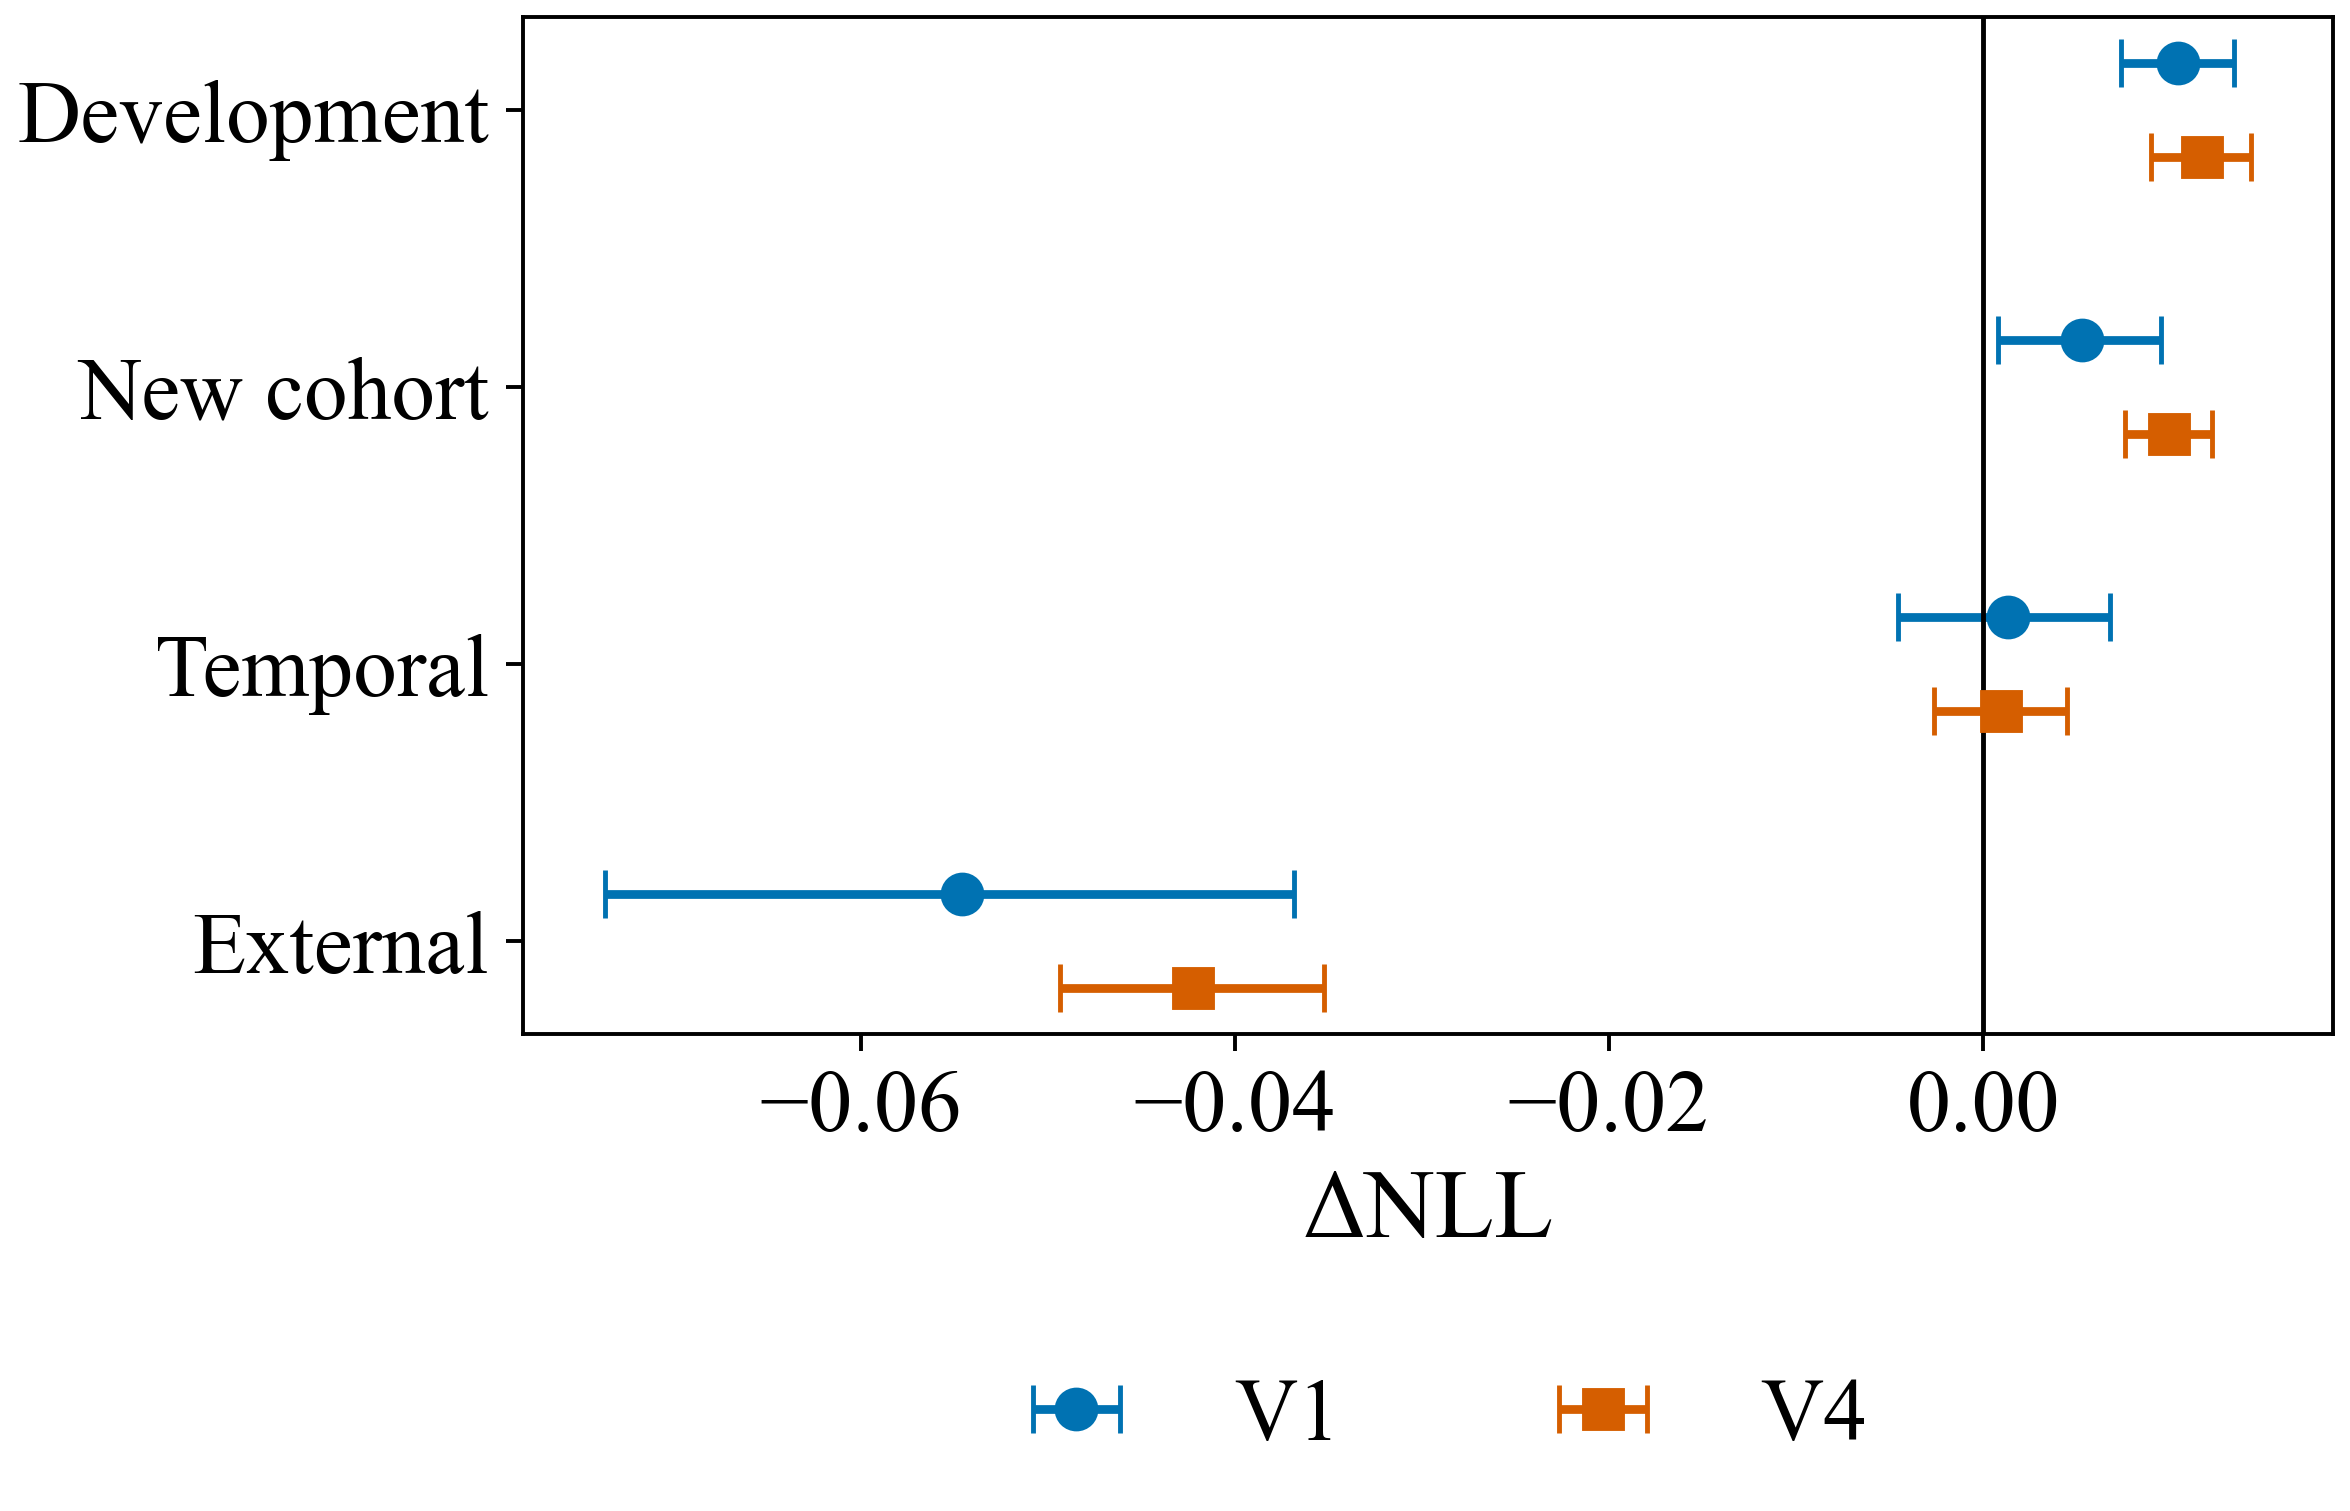

**Figure 6.5. ΔNLL of the corrected variants against the base (V0 − corrected) in the four evaluations: class-wise correction V1 (circles) and one shared coefficient V4 (squares). Development: cross-validated estimate on the development panel (n = 6,708; PRISM-Evidence base). New cohort: prespecified confirmation with the frozen system (n = 2,940). Temporal (n = 1,914) and External (n = 1,181): base B2 of Section 9. Bars are 95 % bootstrap intervals; positive values favour the correction.**

In [40]:
def paired_gain(base_post: np.ndarray, corrected: np.ndarray, target: np.ndarray) -> tuple[float, float, float]:
    """ΔNLL (base − corrected) with its 95 % bootstrap interval."""
    gain = nll_of(base_post, target) - nll_of(corrected, target)
    boot = bootstrap_mean(gain, N_BOOT, SEED)
    return float(gain.mean()), float(np.quantile(boot, 0.025)), float(np.quantile(boot, 0.975))


forest_rows = []
for vid in ("V1", "V4"):
    d, lo, hi = paired_gain(PAPER["V0"], PAPER[vid], y)
    forest_rows.append({"cohort": "Development", "publications": N, "variant_id": vid,
                        "delta_nll": d, "ci_low": lo, "ci_high": hi})
    d, lo, hi = paired_gain(NEW_POST["V0"], NEW_POST[vid], new_target)
    forest_rows.append({"cohort": "New cohort", "publications": len(new_cohort), "variant_id": vid,
                        "delta_nll": d, "ci_low": lo, "ci_high": hi})
    for cohort_name, short in (("Temporal 2025", "Temporal"), ("External arXiv 2024", "External")):
        c = STRESS["B2"]["cohorts"][cohort_name]
        d, lo, hi = paired_gain(c["post"]["V0"], c["post"][vid], c["target"])
        forest_rows.append({"cohort": short, "publications": len(c["target"]), "variant_id": vid,
                            "delta_nll": d, "ci_low": lo, "ci_high": hi})
forest = pd.DataFrame(forest_rows)
forest.to_csv(TABLES / "figure6_5_gain_across_cohorts.csv", index=False)

FOREST_ORDER = ["Development", "New cohort", "Temporal", "External"]
sizes = forest.drop_duplicates("cohort").set_index("cohort")["publications"]
CAPTION_F6_5 = ("Figure 6.5. ΔNLL of the corrected variants against the base (V0 − corrected) in the four "
                "evaluations: class-wise correction V1 (circles) and one shared coefficient V4 (squares). "
                f"Development: cross-validated estimate on the development panel (n = {sizes['Development']:,}; "
                "PRISM-Evidence base). New cohort: prespecified confirmation with the frozen system "
                f"(n = {sizes['New cohort']:,}). Temporal (n = {sizes['Temporal']:,}) and External "
                f"(n = {sizes['External']:,}): base B2 of Section 9. Bars are 95 % bootstrap intervals; "
                "positive values favour the correction.")
fig, ax = plt.subplots(figsize=(6.7, 4.3))
for vid, offset, colour, marker in (("V1", -0.17, OKABE_ITO[0], "o"), ("V4", 0.17, OKABE_ITO[1], "s")):
    part = forest[forest["variant_id"] == vid].set_index("cohort").loc[FOREST_ORDER]
    ax.errorbar(part["delta_nll"], np.arange(len(FOREST_ORDER)) + offset,
                xerr=[part["delta_nll"] - part["ci_low"], part["ci_high"] - part["delta_nll"]],
                fmt=marker, markersize=8, capsize=5, linewidth=1.8, color=colour, label=vid)
ax.axvline(0.0, color="black", linewidth=1.0)
ax.set_yticks(np.arange(len(FOREST_ORDER)), FOREST_ORDER)
ax.invert_yaxis()
ax.set_xlabel("ΔNLL")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.26), ncol=2, frameon=False)
show_figure(fig, "figure6_5_gain_across_cohorts", CAPTION_F6_5, "13")

**Interpretation.**

- **Bases.** The gain of V4 is the same for the three bases (+0.0097 to +0.0100). The gain of V1 varies more (+0.0053 to +0.0081).
- **Similarity.** The gain grows with the similarity to the nearest index publication. For V4 it is +0.0039 in the two lowest quintiles, with intervals that include zero, and +0.0154 to +0.0156 in the two highest. Below the fixed threshold of 0.757 (23.2 % of the cohort) the interval includes zero for both variants. No subgroup shows a loss whose interval excludes zero.
- **Classes.** V4 has a positive point estimate in seven of the eight classes, with intervals above zero in five, and is neutral for Physics and Astronomy (−0.0004). V1 is uneven: it improves four classes by 0.0145 to 0.0283 and has negative point estimates for the other four (−0.0031 to −0.0130), with intervals that include zero. The class-specific coefficients, fitted on 1,828 stop rows, do not generalise evenly, which is why V1 falls behind V4.
- **Figure 6.5.** The gain of V4 has the same size on the development panel (+0.0117) and on the new cohort (+0.0100). It is absent one year later (+0.0010) and reversed on the other source (−0.0422).

In [41]:
recheck_ids = dev.loc[oa_rows, "paper_id"].str.rsplit("/", n=1).str[-1].tolist()
BATCH = int(C3["label_recheck_batch"])
current_field, stored_at = {}, []
for b, start in enumerate(range(0, len(recheck_ids), BATCH)):
    raw_path = ROOT / f"{C3['label_recheck_prefix']}__batch_{b:03d}.json"
    payload = request_json(raw_path, {"filter": "openalex:" + "|".join(recheck_ids[start:start + BATCH]),
                                      "per-page": BATCH, "select": "id,primary_topic"})
    stored_at.append(raw_path.stat().st_mtime)
    for work in payload.get("results", []):
        current_field[work["id"]] = ((work.get("primary_topic") or {}).get("field") or {}).get("display_name", "")


def label_status(paper_id: str, stored_class: str) -> str:
    """Relation between the stored class and the field currently reported by OpenAlex."""
    if paper_id not in current_field:
        return "Record not returned"
    field = current_field[paper_id]
    if field == stored_class:
        return "Same field as stored"
    if field in CLASS_NAMES:
        return "Another of the eight fields"
    return "A field outside the eight classes" if field else "No primary topic"


status = pd.Series([label_status(p, c) for p, c in zip(dev.loc[oa_rows, "paper_id"],
                                                        dev.loc[oa_rows, "thematic_class"])])
ORDER = ["Same field as stored", "Another of the eight fields", "A field outside the eight classes",
         "No primary topic", "Record not returned"]
label_stability = pd.DataFrame([{"current_state": name, "publications": int((status == name).sum()),
                                 "share_percent": 100.0 * float((status == name).mean())} for name in ORDER])
assert label_stability["publications"].sum() == len(oa_rows)
CAPTION_6_29 = ("Table 6.29. Stability of the labels of the 5,532 OpenAlex publications of the development panel: "
                "primary-topic field stored at acquisition (July 2026) against the field reported by the service "
                f"on {pd.Timestamp(min(stored_at), unit='s', tz='UTC').strftime('%Y-%m-%d')}, the day on which "
                "the confirmation cohort was acquired.")
save_table(label_stability, "table6_29_label_stability", CAPTION_6_29, "13")
show_table(pd.DataFrame({"Current state": label_stability["current_state"],
                         "Publications": label_stability["publications"].map(lambda v: f"{v:d}"),
                         "Share (%)": label_stability["share_percent"].map(lambda v: fmt_num(v, 2)),
                         }).set_index("Current state"), CAPTION_6_29)

**Table 6.29. Stability of the labels of the 5,532 OpenAlex publications of the development panel: primary-topic field stored at acquisition (July 2026) against the field reported by the service on 2026-11-10, the day on which the confirmation cohort was acquired.**

,Publications,Share (%)
Current state,,
Same field as stored,3722,67.28
Another of the eight fields,695,12.56
A field outside the eight classes,970,17.53
No primary topic,7,0.13
Record not returned,138,2.49


In [42]:
# Post hoc analysis, added after Table 6.29 was seen; it is recorded among the deviations of step 3.
current_of = np.array([current_field.get(paper_id, "") for paper_id in dev.loc[oa_rows, "paper_id"]])
stored_of = dev.loc[oa_rows, "thematic_class"].to_numpy()
predicted_of = np.array(CLASS_NAMES)[PAPER["V0"][oa_rows].argmax(axis=1)]
in_taxonomy = np.isin(current_of, CLASS_NAMES)
loss = {vid: nll_of(PAPER[vid], y)[oa_rows] for vid in ("V0", "V1", "V4")}
rows = []
for name, mask in (("Same field as stored", current_of == stored_of),
                   ("Another of the eight fields", in_taxonomy & (current_of != stored_of)),
                   ("A field outside the eight classes", (current_of != "") & ~in_taxonomy)):
    row = {"current_state": name, "publications": int(mask.sum()),
           "accuracy_stored_label_percent": 100.0 * float((predicted_of == stored_of)[mask].mean()),
           "prediction_equals_current_field_percent": 100.0 * float((predicted_of == current_of)[mask].mean()),
           "nll_v0_stored_label": float(loss["V0"][mask].mean())}
    for vid in ("V1", "V4"):
        gain = (loss["V0"] - loss[vid])[mask]
        boot = bootstrap_mean(gain, N_BOOT, SEED)
        row.update({f"delta_nll_{vid.lower()}": float(gain.mean()),
                    f"delta_{vid.lower()}_ci_low": float(np.quantile(boot, 0.025)),
                    f"delta_{vid.lower()}_ci_high": float(np.quantile(boot, 0.975))})
    rows.append(row)
label_states = pd.DataFrame(rows)
without_field = len(oa_rows) - int(label_states["publications"].sum())
assert without_field == int((current_of == "").sum())
CAPTION_6_30 = ("Table 6.30. Post hoc analysis: cross-validated development predictions of the base (V0, "
                "PRISM-Evidence) by the current label state of the publication "
                f"({int(label_states['publications'].sum()):,} OpenAlex publications with a current field; the "
                f"{without_field} without one are excluded). Accuracy and NLL use the stored label. The fourth "
                "column is the share of publications whose predicted class is the field that OpenAlex reports "
                "now; it is zero by construction when that field lies outside the eight classes. ΔNLL is V0 minus "
                "the corrected variant with a 95 % bootstrap interval; positive values favour the correction.")
save_table(label_states, "table6_30_development_by_label_state", CAPTION_6_30, "13")
view = pd.DataFrame({
    "Current state": label_states["current_state"],
    "Publications": label_states["publications"].map(lambda v: f"{v:d}"),
    "Accuracy, stored label (%)": label_states["accuracy_stored_label_percent"].map(lambda v: fmt_num(v, 2)),
    "Prediction equals current field (%)": label_states["prediction_equals_current_field_percent"].map(
        lambda v: fmt_num(v, 2)),
    "NLL V0": label_states["nll_v0_stored_label"].map(fmt_num),
    "ΔNLL V0 − V1 [95 % CI]": [f"{fmt_signed(d)} {fmt_ci(a, b)}" for d, a, b in zip(
        label_states["delta_nll_v1"], label_states["delta_v1_ci_low"], label_states["delta_v1_ci_high"])],
    "ΔNLL V0 − V4 [95 % CI]": [f"{fmt_signed(d)} {fmt_ci(a, b)}" for d, a, b in zip(
        label_states["delta_nll_v4"], label_states["delta_v4_ci_low"], label_states["delta_v4_ci_high"])],
}).set_index("Current state")
show_table(view, CAPTION_6_30)

**Table 6.30. Post hoc analysis: cross-validated development predictions of the base (V0, PRISM-Evidence) by the current label state of the publication (5,387 OpenAlex publications with a current field; the 145 without one are excluded). Accuracy and NLL use the stored label. The fourth column is the share of publications whose predicted class is the field that OpenAlex reports now; it is zero by construction when that field lies outside the eight classes. ΔNLL is V0 minus the corrected variant with a 95 % bootstrap interval; positive values favour the correction.**

,Publications,"Accuracy, stored label (%)",Prediction equals current field (%),NLL V0,ΔNLL V0 − V1 [95 % CI],ΔNLL V0 − V4 [95 % CI]
Current state,,,,,,
Same field as stored,3722,88.12,88.12,0.3661,"+0.0158 [+0.0125, +0.0189]","+0.0212 [+0.0186, +0.0238]"
Another of the eight fields,695,45.61,44.32,1.4319,"−0.0257 [−0.0418, −0.0101]","−0.0433 [−0.0576, −0.0291]"
A field outside the eight classes,970,74.12,0.00,0.7592,"+0.0156 [+0.0060, +0.0249]","+0.0092 [+0.0004, +0.0176]"


**Interpretation.**

- **Label stability.** Four months after acquisition, OpenAlex reports the stored field for 67.28 % of the 5,532 development publications. It now reports another of the eight fields for 12.56 % and a field outside the eight classes for 17.53 %; 2.62 % have no current field. The reference labels of the study are therefore not stable. The confirmation cohort carries the November state of the labels, whereas the fit rows and the retrieval index carry the July state.
- **Consequence for the confirmation.** This difference works against the correction, because part of the neighbour labels no longer agrees with the current labelling. V4 was confirmed despite it.
- **Post hoc breakdown (Table 6.30).** For publications with an unchanged field, the base is correct for 88.12 % and its NLL is 0.3661; both corrected variants improve NLL there (V1 +0.0158, V4 +0.0212). Where OpenAlex now reports another of the eight fields, the base agrees with the stored label for 45.61 % and with the current label for 44.32 %, and the correction worsens NLL against the stored label (V1 −0.0257, V4 −0.0433). A substantial part of the measured error is therefore disagreement between two states of the reference labels. This breakdown was added after Table 6.29 was seen and is descriptive.

## 14. Findings against the predeclared rules

**Question.** Which claims do the predeclared decision rules support?

**Method.** The table collects the outcome of every research question from the results above. RQ1 is supported for a component only if the corresponding comparison in Table 6.5 meets the rule. RQ2 is supported only if MASSK (Full) meets the rule against all three calibration controls. RQ3–RQ6 are descriptive. For the stress evaluation, a corrected variant is supported on a cohort only if it meets the rule of Section 9 against both the base and temperature scaling; the remaining step-2 results are descriptive. The confirmation of Section 13 follows its own prespecified rule: a corrected variant is confirmed only if it is favoured over both the base and temperature scaling after adjustment; the other step-3 results are descriptive.

In [43]:
P = primary.set_index("comparator_id")


def primary_text(vid: str) -> str:
    """ΔNLL with its interval and adjusted p-value for one primary comparison."""
    return (f"ΔNLL = {fmt_signed(P.loc[vid, 'delta_nll'])} "
            f"{fmt_ci(P.loc[vid, 'nll_ci_low'], P.loc[vid, 'nll_ci_high'])}, "
            f"Holm p {fmt_p(P.loc[vid, 'p_holm'])}")


def verdict(flags) -> str:
    """Outcome of a predeclared rule."""
    return "supported" if all(flags) else "not supported"


controls_met = [bool(P.loc[v, "rule_met"]) for v in ["C1", "C2", "C3"]]
sens_k = sensitivity[sensitivity["factor"] == "k"]
sens_all_better = int((sensitivity["delta_nll_vs_prism"] > 0).sum())
openalex = pilot[pilot["evaluation_rows"] == "OpenAlex"].set_index("model")
findings = pd.DataFrame([
    {"finding_id": "F6.1", "question": "RQ1: class-specific coefficients (Full versus V2)",
     "result": primary_text("V2"), "outcome": verdict([P.loc["V2", "rule_met"]]), "evidence": "Table 6.5"},
    {"finding_id": "F6.2", "question": "RQ1: confidence multiplier (Full versus V3)",
     "result": primary_text("V3"), "outcome": verdict([P.loc["V3", "rule_met"]]), "evidence": "Table 6.5"},
    {"finding_id": "F6.3", "question": "RQ1: both elements (Full versus V4)",
     "result": primary_text("V4"), "outcome": verdict([P.loc["V4", "rule_met"]]), "evidence": "Table 6.5"},
    {"finding_id": "F6.4", "question": "Correction versus PRISM-Evidence (Full versus V0)",
     "result": primary_text("V0"), "outcome": verdict([P.loc["V0", "rule_met"]]), "evidence": "Table 6.5"},
    {"finding_id": "F6.5", "question": "RQ2: retrieval beyond recalibration (Full versus C1, C2, C3)",
     "result": "; ".join(f"{v}: {primary_text(v)}" for v in ["C1", "C2", "C3"]),
     "outcome": verdict(controls_met), "evidence": "Table 6.5"},
    {"finding_id": "F6.6", "question": "RQ3: sensitivity to k, T and ε",
     "result": (f"Full has lower NLL than PRISM-Evidence in {sens_all_better} of {len(sensitivity)} "
                f"settings; NLL {fmt_num(sensitivity['NLL'].min())}–{fmt_num(sensitivity['NLL'].max())}; "
                f"lowest NLL over k at k = {int(sens_k.loc[sens_k['NLL'].idxmin(), 'value'])}"),
     "outcome": "descriptive", "evidence": "Figure 6.2"},
    {"finding_id": "F6.7", "question": "RQ4: frozen dual-view retrieval",
     "result": "; ".join(f"{r.similarity}: nDCG@10 {fmt_num(r.ndcg_mean)}" for r in retrieval.itertuples()),
     "outcome": "descriptive", "evidence": "Table 6.8"},
    {"finding_id": "F6.8", "question": "RQ5: pilot cohort excluded from index and evaluation",
     "result": (f"OpenAlex rows: ΔNLL = {fmt_signed(openalex.loc['MASSK (Full)', 'delta_nll'])} "
                f"{fmt_ci(openalex.loc['MASSK (Full)', 'delta_ci_low'], openalex.loc['MASSK (Full)', 'delta_ci_high'])} "
                f"with the full index and {fmt_signed(openalex.loc['MASSK (Full), refitted', 'delta_nll'])} "
                f"{fmt_ci(openalex.loc['MASSK (Full), refitted', 'delta_ci_low'], openalex.loc['MASSK (Full), refitted', 'delta_ci_high'])} "
                "with the pilot rows excluded"),
     "outcome": "descriptive", "evidence": "Table 6.9"},
    {"finding_id": "F6.9", "question": "RQ6: dependence on nearest-neighbour similarity",
     "result": "; ".join(f"Q{int(r.quintile)}: {fmt_signed(r.delta_nll)} {fmt_ci(r.delta_ci_low, r.delta_ci_high)}"
                         for r in dependence.itertuples()),
     "outcome": "descriptive", "evidence": "Figure 6.3"},
])
PS = primary_s.set_index(["cohort", "variant_id", "comparator_id"])
AB = across_bases.set_index(["cohort", "configuration"])
SG = stress_groups.set_index(["cohort", "group"])
PT = perturbation.set_index("condition")
ST = stages.set_index("stage")


def stress_text(cohort: str, variant: str) -> str:
    """ΔNLL of a corrected variant against V0 and C1 on one cohort (base B2)."""
    parts = [f"against {comparator}: {fmt_signed(PS.loc[(cohort, variant, comparator), 'delta_nll'])} "
             f"{fmt_ci(PS.loc[(cohort, variant, comparator), 'nll_ci_low'], PS.loc[(cohort, variant, comparator), 'nll_ci_high'])}, "
             f"Holm p {fmt_p(PS.loc[(cohort, variant, comparator), 'p_holm'])}" for comparator in ("V0", "C1")]
    return f"{variant}: " + "; ".join(parts)


step2_rows = []
for index, cohort in enumerate(COHORTS):
    supported = [bool(PS.loc[(cohort, variant, "V0"), "supported"]) for variant in ("V1", "V4")]
    step2_rows.append({
        "finding_id": f"F6.{10 + index}", "question": f"Stress evaluation, {cohort} (base B2, ΔNLL)",
        "result": ". ".join(stress_text(cohort, variant) for variant in ("V1", "V4")),
        "outcome": "supported" if all(supported) else ("supported for one variant" if any(supported)
                                                       else "not supported"),
        "evidence": "Table 6.13"})
step2_rows.append({
    "finding_id": "F6.12", "question": "ΔNLL (V0 − V1) across configurations",
    "result": "; ".join(f"{cohort}, {config}: {fmt_signed(AB.loc[(cohort, config), 'delta_nll'])}"
                        for cohort in COHORTS for config in ("Recorded", "B0", "B1", "B2")),
    "outcome": "descriptive", "evidence": "Table 6.14"})
step2_rows.append({
    "finding_id": "F6.13", "question": "Queries without a close neighbour (similarity below 0.757)",
    "result": "; ".join(
        f"{cohort}: {fmt_num(SG.loc[(cohort, 'Nearest-neighbour similarity below 0.757'), 'share_percent'], 1)} % "
        f"of queries, ΔNLL {fmt_signed(SG.loc[(cohort, 'Nearest-neighbour similarity below 0.757'), 'delta_nll'])}; "
        f"others ΔNLL {fmt_signed(SG.loc[(cohort, 'Nearest-neighbour similarity of 0.757 or more'), 'delta_nll'])}"
        for cohort in COHORTS),
    "outcome": "descriptive", "evidence": "Table 6.15, Figure 6.4"})
step2_rows.append({
    "finding_id": "F6.14", "question": "Development check with an equal-blend base",
    "result": "; ".join(f"{r.variant_id} against {r.comparator_id}: {fmt_signed(r.delta_nll)} "
                        f"{fmt_ci(r.delta_ci_low, r.delta_ci_high)}" for r in blend_check.itertuples()),
    "outcome": "descriptive", "evidence": "Table 6.17"})
step2_rows.append({
    "finding_id": "F6.15", "question": "Raw-text perturbations, temporal cohort",
    "result": "; ".join(f"{name}: Macro-F1 V0 {fmt_num(PT.loc[name, 'macro_f1_v0'])}, "
                        f"ΔNLL V0 − V1 {fmt_signed(PT.loc[name, 'delta_nll_v1'])}"
                        for name in PT.index if name != "Stored embeddings"),
    "outcome": "descriptive" if ENCODER_CHECK_PASSED else "descriptive, encoder check not met",
    "evidence": "Tables 6.18 and 6.19"})
step2_rows.append({
    "finding_id": "F6.16", "question": "Computational cost of the evaluated system",
    "result": (f"{fmt_num(ST.loc['Total', 'ms_per_publication'], 1)} ms per publication in total; encoders "
               f"{fmt_num(ST.loc['Qwen3 encoding', 'share_percent'] + ST.loc['SPECTER2 encoding', 'share_percent'], 2)} % "
               f"of the time; retrieval and correction "
               f"{fmt_num(ST.loc['Exact top-5 retrieval', 'ms_per_publication'] + ST.loc['Correction', 'ms_per_publication'], 3)} "
               "ms per publication"),
    "outcome": "descriptive", "evidence": "Table 6.20"})
TR = topic_relevance[topic_relevance["similarity"] == VIEWS[0][1]].set_index("criterion")
CF = confirm.set_index(["variant_id", "comparator_id"])
LS = label_stability.set_index("current_state")


def confirmation_text(variant: str) -> str:
    """ΔNLL of a corrected variant against V0 and C1 on the confirmation cohort."""
    return "; ".join(f"against {comparator}: {fmt_signed(CF.loc[(variant, comparator), 'delta_nll'])} "
                     f"{fmt_ci(CF.loc[(variant, comparator), 'nll_ci_low'], CF.loc[(variant, comparator), 'nll_ci_high'])}, "
                     f"Holm p {fmt_p(CF.loc[(variant, comparator), 'p_holm'])}" for comparator in ("V0", "C1"))


step3_rows = [{
    "finding_id": "F6.17", "question": "Topic-level relevance of the neighbours (dual view, Precision@10)",
    "result": "; ".join(f"{CRITERIA[c].split(': ')[1]}: {fmt_num(TR.loc[c, 'precision_mean'])} against "
                        f"{fmt_num(TR.loc[c, 'chance_same_class_mean'])} for a random publication of the same class"
                        for c in ("subfield", "topic", "coupling")),
    "outcome": "descriptive", "evidence": "Table 6.21"}]
for index, variant in enumerate(("V1", "V4")):
    step3_rows.append({
        "finding_id": f"F6.{18 + index}",
        "question": f"Prespecified confirmation on the new cohort (n = {len(new_cohort):,}), {variant}",
        "result": confirmation_text(variant),
        "outcome": "confirmed" if bool(CF.loc[(variant, "V0"), "confirmed"]) else "not confirmed",
        "evidence": "Table 6.27"})
step3_rows.append({
    "finding_id": "F6.20", "question": "Stability of the development labels in OpenAlex",
    "result": (f"{fmt_num(LS.loc['Same field as stored', 'share_percent'], 2)} % of the "
               f"{int(label_stability['publications'].sum()):,} publications have the stored field; "
               f"{fmt_num(100.0 - LS.loc['Same field as stored', 'share_percent'], 2)} % do not"),
    "outcome": "descriptive", "evidence": "Table 6.29"})
BY_STATE = label_states.set_index("current_state")
step3_rows.append({
    "finding_id": "F6.21", "question": "Development predictions of the base by current label state (post hoc)",
    "result": (f"accuracy against the stored label {fmt_num(BY_STATE.loc['Same field as stored', 'accuracy_stored_label_percent'], 2)} % "
               "when the field is unchanged and "
               f"{fmt_num(BY_STATE.loc['Another of the eight fields', 'accuracy_stored_label_percent'], 2)} % when OpenAlex now "
               "reports another of the eight fields; in the latter group the prediction equals the current field for "
               f"{fmt_num(BY_STATE.loc['Another of the eight fields', 'prediction_equals_current_field_percent'], 2)} %"),
    "outcome": "descriptive, post hoc", "evidence": "Table 6.30"})
findings = pd.concat([findings, pd.DataFrame(step2_rows), pd.DataFrame(step3_rows)], ignore_index=True)
CAPTION_6_31 = ("Table 6.31. Outcomes of run rev01 against the predeclared rules. ΔNLL > 0 favours "
                "the corrected model. Step-1 results are post hoc development evidence on a reused panel; "
                "step-2 results are retrospective; the confirmation of step 3 was prespecified and "
                "executed once on newly acquired publications.")
save_table(findings, "nb06_findings", CAPTION_6_31, "14")
pd.DataFrame(REGISTRY).to_csv(TABLES / "result_registry.csv", index=False)
show_table(findings.rename(columns={"finding_id": "ID", "question": "Question", "result": "Result",
                                    "outcome": "Outcome", "evidence": "Evidence"}).set_index("ID"),
           CAPTION_6_31)

**Table 6.31. Outcomes of run rev01 against the predeclared rules. ΔNLL > 0 favours the corrected model. Step-1 results are post hoc development evidence on a reused panel; step-2 results are retrospective; the confirmation of step 3 was prespecified and executed once on newly acquired publications.**

,Question,Result,Outcome,Evidence
ID,,,,
F6.1,RQ1: class-specific coefficients (Full versus V2),"ΔNLL = −0.0006 [−0.0017, +0.0005], Holm p 0.547",not supported,Table 6.5
F6.2,RQ1: confidence multiplier (Full versus V3),"ΔNLL = −0.0010 [−0.0026, +0.0006], Holm p 0.547",not supported,Table 6.5
F6.3,RQ1: both elements (Full versus V4),"ΔNLL = −0.0012 [−0.0031, +0.0006], Holm p 0.547",not supported,Table 6.5
F6.4,Correction versus PRISM-Evidence (Full versus V0),"ΔNLL = +0.0104 [+0.0074, +0.0134], Holm p < 0.001",supported,Table 6.5
F6.5,"RQ2: retrieval beyond recalibration (Full versus C1, C2, C3)","C1: ΔNLL = +0.0077 [+0.0048, +0.0106], Holm p < 0.001; C2: ΔNLL = +0.0129 [+0.0097, +0.0161], Holm p < 0.001; C3: ΔNLL = +0.0084 [+0.0051, +0.0117], Holm p < 0.001",supported,Table 6.5
F6.6,"RQ3: sensitivity to k, T and ε",Full has lower NLL than PRISM-Evidence in 15 of 16 settings; NLL 0.5416–0.5684; lowest NLL over k at k = 50,descriptive,Figure 6.2
F6.7,RQ4: frozen dual-view retrieval,Dual view (Qwen3 + SPECTER2): nDCG@10 0.7077; Qwen3 only: nDCG@10 0.7070; SPECTER2 only: nDCG@10 0.6832,descriptive,Table 6.8
F6.8,RQ5: pilot cohort excluded from index and evaluation,"OpenAlex rows: ΔNLL = +0.0099 [+0.0065, +0.0133] with the full index and +0.0133 [+0.0105, +0.0161] with the pilot rows excluded",descriptive,Table 6.9
F6.9,RQ6: dependence on nearest-neighbour similarity,"Q1: +0.0030 [−0.0067, +0.0124]; Q2: +0.0134 [+0.0054, +0.0210]; Q3: +0.0109 [+0.0048, +0.0167]; Q4: +0.0124 [+0.0068, +0.0175]; Q5: +0.0125 [+0.0088, +0.0161]",descriptive,Figure 6.3


## 15. Conclusions and limitations

**Conclusions.**

1. **Development.** On the development panel, retrieval-conditioned correction improves NLL and Brier score beyond recalibration of the base posterior. Predicted classes do not change. The result holds with and without the evidence router in the base.
2. **Form of the correction.** The specific form of the MASSK correction is not supported. One shared coefficient without the confidence multiplier gives an NLL at least as low as the eight-coefficient form.
3. **Confirmation.** On 2,940 newly acquired publications from the source and years of the fit rows, with the system frozen before acquisition, the one-coefficient correction is confirmed: it lowers NLL by 0.0100 against the base and by 0.0075 against temperature scaling. The class-wise form with the multiplier is not confirmed, because it does not exceed temperature scaling.
4. **Transfer.** The gain does not transfer. On the temporal cohort the correction has no measurable effect. On the external cohort it worsens NLL by about 0.05 in every configuration, more than temperature scaling does, and the harm is concentrated in classes where the base already fails.
5. **Conditions.** The harm on the external cohort shrinks as the nearest-neighbour similarity grows and disappears only in the highest similarity quintile. Neighbour disagreement marks the most harmful cases. On the new cohort the gain grows with the similarity, and no subgroup shows harm.
6. **Pilot cohort.** The arXiv pilot rows acted as same-source training data for the external cohort: without them, external macro-F1 falls from 0.55 to 0.49.
7. **Retrieval.** The frozen dual-view similarity retrieves no better than Qwen3 alone. Its neighbours are topically related beyond class agreement: they share the primary topic of the query 13.5 times as often, and a referenced work 13 times as often, as a random publication of the same class.
8. **Robustness and cost.** The base loses 0.017 macro-F1 with the title alone and at most 0.007 under the other perturbations, and the correction is not harmful in any perturbed condition. The encoders take 99.98 % of the inference time.
9. **Labels.** OpenAlex reports the stored field for 67.28 % of the development publications four months after acquisition.

**Limitations.**

- The step-1 analyses are post hoc on a panel reused through fourteen earlier refinement rounds. NLL became the primary endpoint after its development values were known.
- The stress evaluation is retrospective: both cohorts had been evaluated before.
- The confirmation cohort comes from the service that supplied the fit rows and tests the in-distribution claim only. Its labels reflect a later state of OpenAlex than the labels of the fit rows.
- Bootstrap intervals condition on the fitted models. Two fits of the same base specification differ by 0.021 in temporal NLL.
- The development and stress bases share a specification but not a code path: the development posteriors come from the earlier pipeline. The stop rows used to fit the correction also selected the early-stopping epoch of the base.
- The outer folds are effectively ungrouped, and the default $k = 5$ was not re-selected.
- Labels are OpenAlex primary-topic fields without expert verification, and a third of them changed within four months. Topic-level relevance relies on automatically assigned topics and on shared references; no expert judged relevance. The breakdown by label state is post hoc.